<a href="https://colab.research.google.com/github/TasminaTasin75/cataract-detection/blob/master/llm_agent_for_ecom_assignment_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# COMP6012 Assignment 4 — LLM-based eCommerce Agent

A LLM-based eCommerce Agent for an online phone shop, with three tasks:
1. **Advertisement generation** — find matching product images, write a slogan, put it on the image.
2. **Product recommendation** — list every phone that fits a buyer's request and recommend the best ones.
3. **Customer review analysis** — sentiment, common pros and cons, and improvement ideas.

**Models:** Qwen3.5-2B (vision), Qwen3-4B in 4-bit (text), all-MiniLM-L6-v2 (embeddings).

In [1]:
# Install required libraries
%pip install -q "transformers==5.21.0" "accelerate>=1.4" "bitsandbytes==0.49.0" "peft" \
    "sentence-transformers" "kagglehub" "gradio>=6,<7"

## Setup
Basic imports, output folder and a fixed random seed.

In [34]:
# Basic library imports
import torch
import numpy as np
import pandas as pd
from transformers import set_seed
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import json
import re
import time
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

SEED = 42
set_seed(SEED)   # same random results each run

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


## Data inspection
### Image dataset
140 images with short captions, from Hugging Face.

In [35]:
# Load the image dataset
from datasets import load_dataset

image_dataset = load_dataset("daekeun-ml/mobile-icons-poc")
print(image_dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'text'],
        num_rows: 140
    })
})


**Viewing sample images**

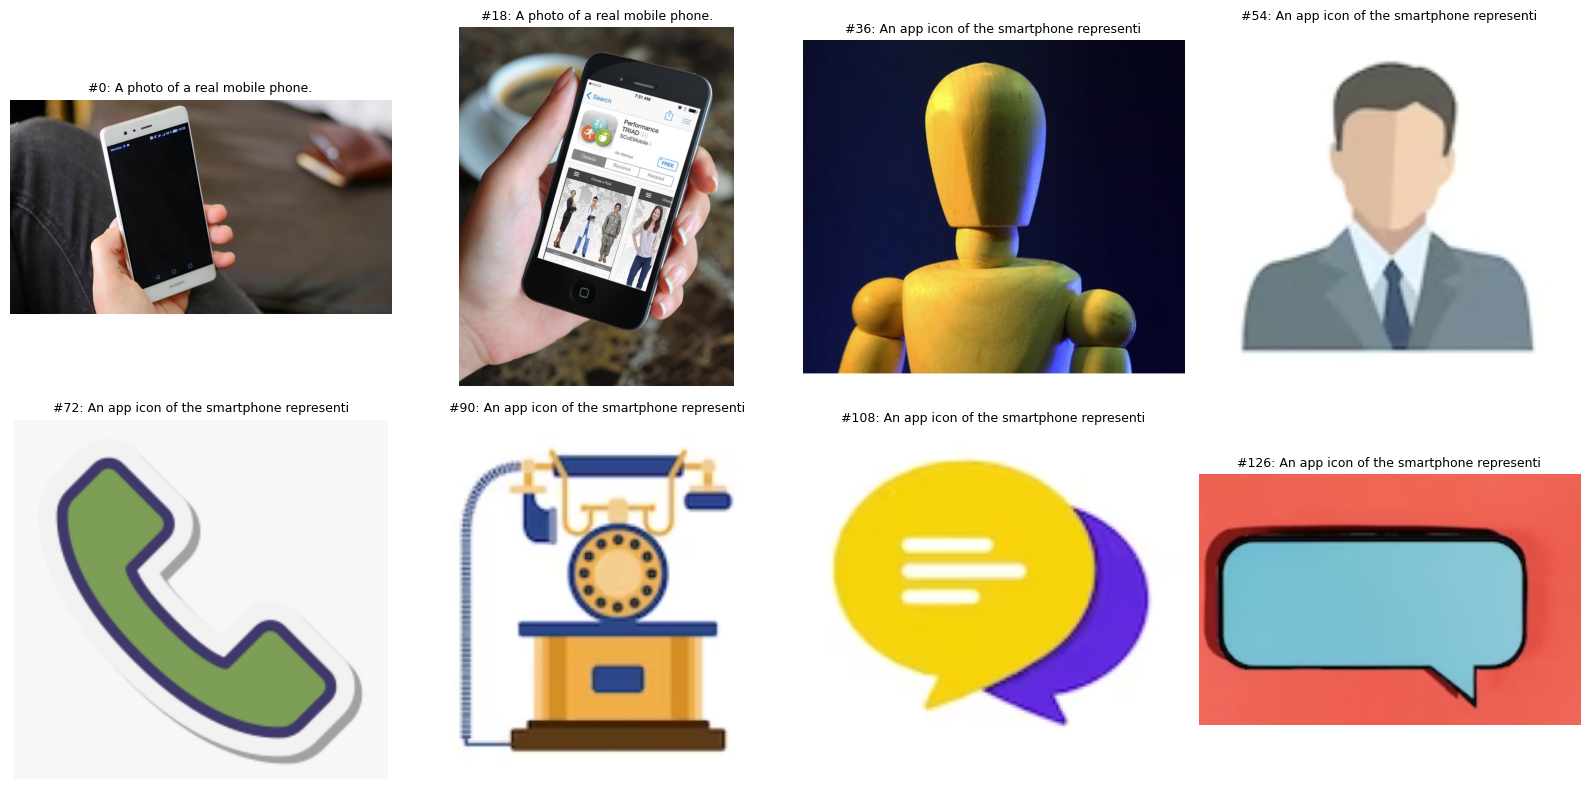

In [36]:
# View sample images with captions
import matplotlib.pyplot as plt

images = image_dataset["train"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, idx in zip(axes.ravel(), range(0, 140, 18)):   # 8 images spread across the dataset
    ax.imshow(images[idx]["image"])
    ax.set_title(f"#{idx}: {images[idx]['text'][:40]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Caption summary**

How many different captions are there?

In [37]:
# Caption types and full captions
captions = pd.Series(images["text"])

# Group by the start of the caption to see the image types
caption_type = captions.str.split().str[:4].str.join(" ")
print("Caption types:")
print(caption_type.value_counts())

print("\nSome full captions:")
for idx in [0, 18, 36, 54, 72, 90]:
    print(f"#{idx}: {captions[idx]}")

Caption types:
An app icon of    105
A photo of a       35
Name: count, dtype: int64

Some full captions:
#0: A photo of a real mobile phone.
#18: A photo of a real mobile phone.
#36: An app icon of the smartphone representing the person avatar.
#54: An app icon of the smartphone representing the person avatar.
#72: An app icon of the smartphone representing the phone.
#90: An app icon of the smartphone representing the phone.


In [38]:
# get all unique captions and their counts
print("Unique captions:", captions.nunique())
print(captions.value_counts())

Unique captions: 4
A photo of a real mobile phone.                                  35
An app icon of the smartphone representing the person avatar.    35
An app icon of the smartphone representing the phone.            35
An app icon of the smartphone representing the speech bubble.    35
Name: count, dtype: int64


**Loading the Amazon reviews dataset**

In [39]:
# Load the Amazon cell phones reviews from Kaggle dataset
import kagglehub
from pathlib import Path

try:
    data_path = Path(kagglehub.dataset_download("grikomsn/amazon-cell-phones-reviews"))
    print("Downloaded to:", data_path)
except Exception as error:
    print("Download failed:", error)
    data_path = Path("/content")   # fallback: files uploaded manually

# Show the CSV files found
for file in data_path.rglob("*.csv"):
    print(file.name)

Using Colab cache for faster access to the 'amazon-cell-phones-reviews' dataset.
Downloaded to: /kaggle/input/amazon-cell-phones-reviews
20191226-items.csv
20191226-reviews.csv


In [40]:
# Read the CSV files
items = pd.read_csv(data_path / "20191226-items.csv")
reviews = pd.read_csv(data_path / "20191226-reviews.csv")

print("Items:", items.shape)
print("Reviews:", reviews.shape)

display(items.head(3))
display(reviews.head(3))

Items: (720, 10)
Reviews: (67986, 8)


,asin,brand,title,url,image,rating,reviewUrl,totalReviews,price,originalPrice
0,B0000SX2UC,NaN,Dual-Band / Tri-Mode Sprint PCS Phone w/ Voice...,https://www.amazon.com/Dual-Band-Tri-Mode-Acti...,https://m.media-amazon.com/images/I/2143EBQ210...,3.0,https://www.amazon.com/product-reviews/B0000SX2UC,14,0.00,0.0
1,B0009N5L7K,Motorola,Motorola I265 phone,https://www.amazon.com/Motorola-i265-I265-phon...,https://m.media-amazon.com/images/I/419WBAVDAR...,3.0,https://www.amazon.com/product-reviews/B0009N5L7K,7,49.95,0.0
2,B000SKTZ0S,Motorola,MOTOROLA C168i AT&T CINGULAR PREPAID GOPHONE C...,https://www.amazon.com/MOTOROLA-C168i-CINGULAR...,https://m.media-amazon.com/images/I/71b+q3ydkI...,2.7,https://www.amazon.com/product-reviews/B000SKTZ0S,22,99.99,0.0


,asin,name,rating,date,verified,title,body,helpfulVotes
0,B0000SX2UC,Janet,3,"October 11, 2005",False,"Def not best, but not worst",I had the Samsung A600 for awhile which is abs...,1.0
1,B0000SX2UC,Luke Wyatt,1,"January 7, 2004",False,Text Messaging Doesn't Work,Due to a software issue between Nokia and Spri...,17.0
2,B0000SX2UC,Brooke,5,"December 30, 2003",False,Love This Phone,"This is a great, reliable phone. I also purcha...",5.0


**Inspecting the Kaggle data**

Quick checks: missing values, brands, star ratings, review length, and links between the two files.

In [41]:
# Check missing values
print("Missing values in items:")
print(items.isna().sum())

print("\nMissing values in reviews:")
print(reviews.isna().sum())

Missing values in items:
asin             0
brand            4
title            0
url              0
image            0
rating           0
reviewUrl        0
totalReviews     0
price            0
originalPrice    0
dtype: int64

Missing values in reviews:
asin                0
name                3
rating              0
date                0
verified            0
title              29
body               26
helpfulVotes    40771
dtype: int64


In [42]:
# Counting how many different brands there are.
print("Number of brands:", items["brand"].nunique())
# How many phones each brand has
print(items["brand"].value_counts())

Number of brands: 10
brand
Samsung     346
Motorola    105
Apple        63
Xiaomi       46
Nokia        44
Google       38
HUAWEI       32
Sony         27
OnePlus      10
ASUS          5
Name: count, dtype: int64


rating
1    12743
2     3915
3     4752
4     8824
5    37752
Name: count, dtype: int64


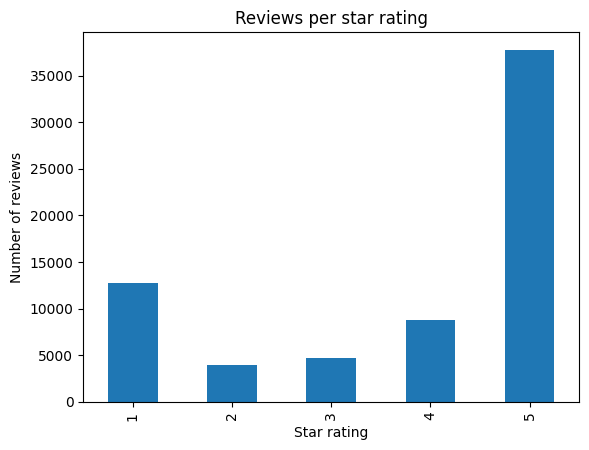

In [43]:
# Reviewing star-rating distribution
rating_counts = reviews["rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar", title="Reviews per star rating")
plt.xlabel("Star rating")
plt.ylabel("Number of reviews")
plt.show()

In [44]:
# Review length in words
review_words = reviews["body"].fillna("").str.split().str.len()

print(review_words.describe())
print("Empty reviews:", (review_words == 0).sum())

count    67986.000000
mean        55.291795
std        119.500034
min          0.000000
25%          8.000000
50%         23.000000
75%         56.000000
max       5345.000000
Name: body, dtype: float64
Empty reviews: 26


In [45]:
# Checking reviews link to products by asin(product id)
is_linked = reviews["asin"].isin(items["asin"])

print("Reviews linked to a product:", is_linked.sum(), "of", len(reviews))
print("Products that have reviews:", reviews["asin"].nunique(), "of", len(items))

Reviews linked to a product: 67986 of 67986
Products that have reviews: 720 of 720


**What we found**
- Images: 140 images in 4 groups of 35 (phone photos, avatar icons, phone icons, speech bubbles), but only 4 different captions. So we need a vision model to describe each image.
- Products: 720 phones from 10 brands (Samsung has 346). Only 4 brands are missing.
- Reviews: all 67,986 link to a product. 26 are empty which will be removed.
- Ratings are unbalanced: approx 68% positive (4–5 stars), approx 25% negative (1–2), approx 7% neutral (3).
- Most reviews are short (median 23 words). We will truncate the long reviews.

# Task 1 - Advertisement Generation

## 1.1 Candidate image selection
First we load the vision-language model (Qwen3.5-2B). It looks at an image and answers questions about it.

In [46]:
#Load the VLM and its processor
from transformers import AutoProcessor, AutoModelForMultimodalLM

VLM_MODEL_ID = "Qwen/Qwen3.5-2B"
MODEL_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

processor = AutoProcessor.from_pretrained(
    VLM_MODEL_ID,
    min_pixels=224 * 224,
    max_pixels=448 * 448,
)
vlm_model = AutoModelForMultimodalLM.from_pretrained(
    VLM_MODEL_ID,
    dtype=MODEL_DTYPE,
    device_map=DEVICE,
)
vlm_model.eval()
print("VLM loaded:", VLM_MODEL_ID)

Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

VLM loaded: Qwen/Qwen3.5-2B


**Generating caption for images**

In [47]:
# Caption function
CAPTION_PROMPT = (
    "Describe this image in one or two sentences for an online phone shop. "
    "Mention the main object, its colours, and any visible details."
)

def generate_caption_from_image(image, text_prompt=None, max_new_tokens=90):
    """Caption or answer a question about one PIL image."""
    image = image.convert("RGB")
    question = (text_prompt or CAPTION_PROMPT).strip()

    messages = [
        {"role": "user", "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": question},
        ]}
    ]

    inputs = processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt",
    )
    inputs = inputs.to(vlm_model.device, dtype=MODEL_DTYPE)

    input_length = inputs["input_ids"].shape[-1]
    with torch.inference_mode():
        output_ids = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)

    new_tokens = output_ids[0][input_length:]
    return processor.decode(new_tokens, skip_special_tokens=True).strip()


# Testing on the first image
print("Original caption:", images[0]["text"])
print("VLM caption:", generate_caption_from_image(images[0]["image"]))

Original caption: A photo of a real mobile phone.
VLM caption: A sleek white Huawei smartphone is held in a hand, displaying a black screen with visible status icons and navigation buttons — ideal for showcasing its design and build quality. The phone’s clean lines and minimalist aesthetic make it perfect for online listings, especially if you’re highlighting its modern appeal or compatibility with Android devices.


**Factual caption prompt**

The first Prompt added marketing language ("ideal for showcasing..."), so now we ask only for visible facts. It is tested on one image from each group.

#0 | A photo of a real mobile phone.
   VLM (6.0s): A white smartphone with a black screen is held in a person's hand, showing the time 12:25 and a few status icons, with a brown leather-bound book resting on a dark surface in the background.



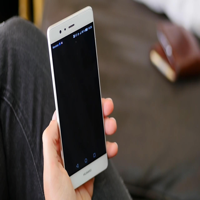

#35 | An app icon of the smartphone representing the person avatar.
   VLM (2.0s): A wooden mannequin with a smooth, rounded head and articulated joints stands against a deep blue background, illuminated by soft lighting that highlights its pale yellow hue and subtle grain texture.



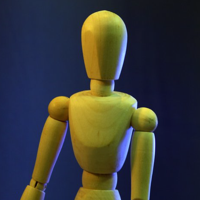

#70 | An app icon of the smartphone representing the phone.
   VLM (1.6s): A purple and blue outlined telephone handset icon is centered within a rounded square frame, featuring a gradient from purple to blue along its edges.



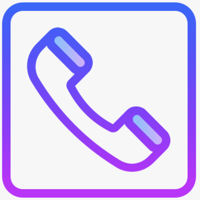

#105 | An app icon of the smartphone representing the speech bubble.
   VLM (1.2s): A yellow 3D speech bubble with a pointed tail is centered on a solid blue background.



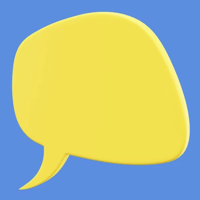

In [48]:
# Factual prompt, tested on one image per group
CAPTION_PROMPT = (
    "Describe only what is visible in this image in one sentence. "
    "Mention the main object, its colours, and any visible details. "
    "Do not add opinions or marketing language."
)

import time

for idx in [0, 35, 70, 105]:      # first image of each group
    start = time.time()
    caption = generate_caption_from_image(images[idx]["image"])
    seconds = time.time() - start # checking the elpsed time for generating the caption
    print(f"#{idx} | {images[idx]['text']}")
    print(f"   VLM ({seconds:.1f}s): {caption}\n")
    image = images[idx]["image"]
    display(image.resize((200, 200)))

**Generate Caption for all 140 images and saving to csv for future reuse in case of gpu disconnect**

Combines the original caption (category) with the VLM caption (details)

In [49]:
# Caption all the 140 images and save
CAPTIONS_FILE = OUTPUT_DIR / "image_captions.csv"

if CAPTIONS_FILE.exists():
    captions_df = pd.read_csv(CAPTIONS_FILE)
    print("Loaded saved captions:", len(captions_df))
else:
    rows = []
    for idx in range(len(images)):
        vlm_caption = generate_caption_from_image(images[idx]["image"])
        rows.append({
            "index": idx,
            "original_caption": images[idx]["text"],
            "vlm_caption": vlm_caption,
        })
        if (idx + 1) % 20 == 0:
            print(f"Captioned {idx + 1} / {len(images)}")

    captions_df = pd.DataFrame(rows)
    captions_df["full_caption"] = captions_df["original_caption"] + " " + captions_df["vlm_caption"]
    captions_df.to_csv(CAPTIONS_FILE, index=False)
    print("Saved to", CAPTIONS_FILE)

display(captions_df.head())

Loaded saved captions: 140


,index,original_caption,vlm_caption,full_caption
0,0,A photo of a real mobile phone.,A white smartphone with a black screen is held...,A photo of a real mobile phone. A white smartp...
1,1,A photo of a real mobile phone.,A black smartphone lies on a light gray surfac...,A photo of a real mobile phone. A black smartp...
2,2,A photo of a real mobile phone.,A hand holds a black smartphone displaying the...,A photo of a real mobile phone. A hand holds a...
3,3,A photo of a real mobile phone.,A pink smartphone with a visible keyboard inte...,A photo of a real mobile phone. A pink smartph...
4,4,A photo of a real mobile phone.,A hand holds a black smartphone displaying a W...,A photo of a real mobile phone. A hand holds a...


**Candidate Image Selection**

Every caption is turned into an embedding with all-MiniLM-L6-v2

In [50]:
# Embed every caption with 'all-MiniLM-L6-v2'
from sentence_transformers import SentenceTransformer

print("Unique VLM captions:", captions_df["vlm_caption"].nunique(), "of", len(captions_df))

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

caption_embeddings = embedding_model.encode(
    captions_df["full_caption"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True,
)

print("Embedding matrix shape:", caption_embeddings.shape)

Unique VLM captions: 140 of 140


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

Embedding matrix shape: (140, 384)


**Define the image search by keywords and testing**

It searches the embedded captions and finds similarity

,index,original_caption,vlm_caption,score
0,0,A photo of a real mobile phone.,A white smartphone with a black screen is held...,0.705420
4,4,A photo of a real mobile phone.,A hand holds a black smartphone displaying a W...,0.679996
28,28,A photo of a real mobile phone.,"A hand holds a bright green Nokia smartphone, ...",0.665950
5,5,A photo of a real mobile phone.,"A black Nokia N90 smartphone is held in hands,...",0.652326
9,9,A photo of a real mobile phone.,A person holds a white smartphone with a black...,0.648948
15,15,A photo of a real mobile phone.,A hand holds a black smartphone displaying a c...,0.625406
18,18,A photo of a real mobile phone.,A hand holds a black smartphone displaying the...,0.622747
74,74,An app icon of the smartphone representing the...,A black telephone handset icon is centered wit...,0.581764


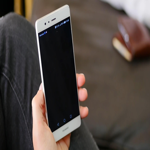

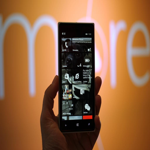

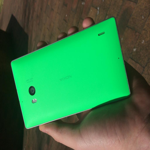

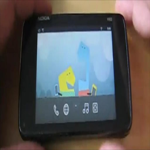

In [51]:
# Searching images by keywords
def search_images(query):
    """Score every image against the query and sort by similarity."""
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True,
    )[0]

    similarities = caption_embeddings @ query_embedding

    results = captions_df[["index", "original_caption", "vlm_caption"]].copy()
    results["score"] = similarities
    return results.sort_values("score", ascending=False)


# Test one query
query = "a black phone held in a hand"
results = search_images(query)
display(results.head(8))

for idx in results["index"].head(4):
    display(images[int(idx)]["image"].resize((150, 150)))

**Choose a threshold**

The 4 image groups (35 in each) act as ground truth. We test simple category queries at different thresholds and measure precision and recall.

In [52]:
# Evaluate thresholds with the 4 groups (35 images in each group)
captions_df["group"] = captions_df["index"] // 35   # 0 = phone photo, 1 = avatar, 2 = phone icon, 3 = speech bubble

test_queries = {
    # similar words to the original captions
    "a real mobile phone": 0,
    "a person avatar icon": 1,
    "a phone call icon": 2,
    "a speech bubble icon": 3,
    # paraphrased words, same meaning
    "someone holding a smartphone": 0,
    "a user profile picture": 1,
    "calling or dialing symbol": 2,
    "chat or messaging symbol": 3,
}

rows = []
for threshold in [0.3, 0.4, 0.5, 0.6]:
    for query, true_group in test_queries.items():
        results = search_images(query)
        matched = results[results["score"] >= threshold]
        correct = (captions_df.loc[matched.index, "group"] == true_group).sum()

        precision = correct / len(matched) if len(matched) > 0 else 0
        recall = correct / 35
        rows.append({"threshold": threshold, "query": query, "matched": len(matched),
                     "precision": round(precision, 2), "recall": round(recall, 2)})

threshold_table = pd.DataFrame(rows)
display(threshold_table.groupby("threshold")[["precision", "recall"]].mean().round(2))

,precision,recall
threshold,,
0.3,0.35,1.00
0.4,0.58,0.96
0.5,0.78,0.71
0.6,0.60,0.51


**Per-query results at threshold 0.45**

Threshold 0.45 balances high recall (find all matching images) with reasonable precision, based on the results above.

In [53]:
# Per-query results at threshold 0.45
MATCH_THRESHOLD = 0.45

rows = []
for query, true_group in test_queries.items():
    results = search_images(query)
    matched = results[results["score"] >= MATCH_THRESHOLD]
    correct = (captions_df.loc[matched.index, "group"] == true_group).sum()

    precision = correct / len(matched) if len(matched) > 0 else 0
    recall = correct / 35
    rows.append({"query": query, "matched": len(matched),
                 "precision": round(precision, 2), "recall": round(recall, 2)})

display(pd.DataFrame(rows))

,query,matched,precision,recall
0,a real mobile phone,71,0.49,1.00
1,a person avatar icon,35,1.00,1.00
2,a phone call icon,119,0.29,1.00
3,a speech bubble icon,44,0.80,1.00
4,someone holding a smartphone,109,0.32,1.00
5,a user profile picture,34,1.00,0.97
6,calling or dialing symbol,22,1.00,0.63
7,chat or messaging symbol,13,0.77,0.29


**Clean the captions**

Every icon caption says "the smartphone", so phone queries matched almost everything. We replace each caption with a short label plus purpose words (e.g. "speech bubble (chat, messaging)").

In [54]:
# Clean captions adding purposes, re-embed, and re-test
clean_labels = {
    "A photo of a real mobile phone.": "Photo of a real mobile phone.",
    "An app icon of the smartphone representing the person avatar.": "App icon: person avatar (user profile, account).",
    "An app icon of the smartphone representing the phone.": "App icon: phone handset (call, dialing).",
    "An app icon of the smartphone representing the speech bubble.": "App icon: speech bubble (chat, messaging).",
}

captions_df["clean_label"] = captions_df["original_caption"].map(clean_labels)
captions_df["full_caption"] = captions_df["clean_label"] + " " + captions_df["vlm_caption"]

caption_embeddings = embedding_model.encode(
    captions_df["full_caption"].tolist(),
    convert_to_numpy=True,
    normalize_embeddings=True,
)

rows = []
for query, true_group in test_queries.items():
    results = search_images(query)
    matched = results[results["score"] >= MATCH_THRESHOLD]
    correct = (captions_df.loc[matched.index, "group"] == true_group).sum()

    precision = correct / len(matched) if len(matched) > 0 else 0
    recall = correct / 35
    rows.append({"query": query, "matched": len(matched),
                 "precision": round(precision, 2), "recall": round(recall, 2)})

display(pd.DataFrame(rows))

,query,matched,precision,recall
0,a real mobile phone,62,0.56,1.0
1,a person avatar icon,35,1.00,1.0
2,a phone call icon,82,0.43,1.0
3,a speech bubble icon,37,0.95,1.0
4,someone holding a smartphone,58,0.60,1.0
5,a user profile picture,35,1.00,1.0
6,calling or dialing symbol,35,1.00,1.0
7,chat or messaging symbol,38,0.92,1.0


**Double-check with the VLM (VQA)**

Embedding search finds candidates; the VLM then looks at each candidate image and answers yes/no to remove wrong matches.

In [55]:
# VQA double check on candidates
def vlm_says_yes(image, query):
    """Ask the VLM whether the image matches the query. Returns True or False."""
    question = f"Does this image show {query}? Answer only yes or no."
    answer = generate_caption_from_image(image, text_prompt=question, max_new_tokens=5)
    return answer.lower().startswith("yes")


def find_matching_images(query, threshold=MATCH_THRESHOLD, use_vqa=True):
    """Step 1: embedding search. Step 2 (optional): VQA check on each candidate."""
    results = search_images(query)
    candidates = results[results["score"] >= threshold].copy()

    if use_vqa:
        candidates["vqa_yes"] = [vlm_says_yes(images[int(idx)]["image"], query)
                                 for idx in candidates["index"]]
        candidates = candidates[candidates["vqa_yes"]]
    return candidates


# Test on the weakest query
query = "a phone call icon"
matches = find_matching_images(query)
correct = (captions_df.loc[matches.index, "group"] == test_queries[query]).sum()
print("Matched:", len(matches), "| precision:", round(correct / len(matches), 2), "| recall:", round(correct / 35, 2))

Matched: 27 | precision: 0.93 | recall: 0.71


**Investigate VQA rejections**

VQA raised precision (0.43 -> 0.93) but lowered recall (1.00 -> 0.71), so we check which correct images it wrongly rejected.

Correct images rejected by VQA: 10


,index,vlm_caption,score
103,103,A purple rotary telephone with a matching hand...,0.812528
102,102,A vintage rotary telephone with a cream-colore...,0.810702
100,100,A vintage-style pink telephone with a coiled c...,0.807102
95,95,A glossy red rotary telephone with a coiled re...,0.803934
104,104,A glossy black rotary telephone with an orange...,0.798272
86,86,A light blue mobile phone with a yellow screen...,0.794475
77,77,A white smartphone icon is centered within a c...,0.794135
101,101,A glossy orange rotary telephone with a matchi...,0.792851
97,97,A light blue rotary telephone with a matching ...,0.782165
81,81,A black smartphone with a light blue screen di...,0.733388


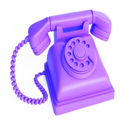

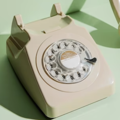

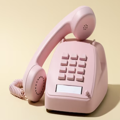

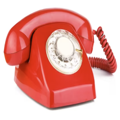

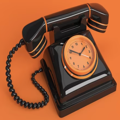

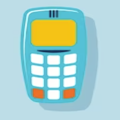

In [56]:
# Which correct images did VQA reject?
candidates = find_matching_images(query, use_vqa=False)       # before VQA
true_group = test_queries[query]

rejected = candidates[
    (captions_df.loc[candidates.index, "group"] == true_group)  # correct group
    & (~candidates["index"].isin(matches["index"]))             # but removed by VQA
]

print("Correct images rejected by VQA:", len(rejected))
display(rejected[["index", "vlm_caption", "score"]])

for idx in rejected["index"].head(6):
    display(images[int(idx)]["image"].resize((120, 120)))

**VQA only for borderline scores**

Rejected correct images were rotary telephones with high scores (0.73–0.81). So the VLM was too strict. Now we keep high scores and only ask the VLM about borderline ones.

In [57]:
# Using VQA only for borderline scores, tested on all queries
def find_matching_images(query, threshold=MATCH_THRESHOLD, confident_score=0.7):
    """Keep high scores, VQA-check borderline scores, reject low scores."""
    results = search_images(query)
    candidates = results[results["score"] >= threshold].copy()

    keep = []
    for idx, score in zip(candidates["index"], candidates["score"]):
        if score >= confident_score:
            keep.append(True)                                    # confident: keep
        else:
            keep.append(vlm_says_yes(images[int(idx)]["image"], query))  # borderline: ask VLM
    return candidates[keep]


rows = []
for confident_score in [0.65, 0.70, 0.75]:
    for query, true_group in test_queries.items():
        matches = find_matching_images(query, confident_score=confident_score)
        correct = (captions_df.loc[matches.index, "group"] == true_group).sum()

        precision = correct / len(matches) if len(matches) > 0 else 0
        recall = correct / 35
        rows.append({"confident_score": confident_score, "query": query,
                     "precision": round(precision, 2), "recall": round(recall, 2)})

vqa_table = pd.DataFrame(rows)
display(vqa_table.groupby("confident_score")[["precision", "recall"]].mean().round(2))

,precision,recall
confident_score,,
0.65,0.98,0.86
0.70,0.98,0.82
0.75,0.98,0.82


**Checking Lower confident levels**

Lower confident levels gave better recall with the same precision, so we also test 0.55 and 0.60 and check results per query.

In [58]:
#Checking lower confident levels and show per-query results
rows = []
for confident_score in [0.55, 0.60]:
    for query, true_group in test_queries.items():
        matches = find_matching_images(query, confident_score=confident_score)
        correct = (captions_df.loc[matches.index, "group"] == true_group).sum()

        precision = correct / len(matches) if len(matches) > 0 else 0
        recall = correct / 35
        rows.append({"confident_score": confident_score, "query": query,
                     "precision": round(precision, 2), "recall": round(recall, 2)})

vqa_table_low = pd.DataFrame(rows)
display(vqa_table_low.groupby("confident_score")[["precision", "recall"]].mean().round(2))
display(vqa_table_low)

,precision,recall
confident_score,,
0.55,0.98,0.96
0.60,0.98,0.91


,confident_score,query,precision,recall
0,0.55,a real mobile phone,0.97,1.00
1,0.55,a person avatar icon,1.00,1.00
2,0.55,a phone call icon,0.90,1.00
3,0.55,a speech bubble icon,0.95,1.00
4,0.55,someone holding a smartphone,1.00,0.71
5,0.55,a user profile picture,1.00,0.97
6,0.55,calling or dialing symbol,1.00,0.97
7,0.55,chat or messaging symbol,1.00,1.00
8,0.60,a real mobile phone,0.97,1.00
9,0.60,a person avatar icon,1.00,1.00


**Final matcher settings**

Best result: similarity threshold 0.45, VQA for scores 0.45–0.55, keep scores greater or equal 0.55. Precision 0.98, recall 0.96. Lower recall on "someone holding a smartphone" is partly due to ground truth: not every phone photo shows a hand.

In [59]:
# Save final settings and evaluation results
CONFIDENT_SCORE = 0.55

final_results = vqa_table_low[vqa_table_low["confident_score"] == CONFIDENT_SCORE]
final_results.to_csv(OUTPUT_DIR / "image_matching_results.csv", index=False)
captions_df.to_csv(CAPTIONS_FILE, index=False)   # now also includes clean_label and group

print("Final threshold:", MATCH_THRESHOLD, "| confident score:", CONFIDENT_SCORE)
print("Saved evaluation results and updated captions.")

Final threshold: 0.45 | confident score: 0.55
Saved evaluation results and updated captions.


**Extra evaluation: attribute queries**

The 4 groups only test categories. To test a wider range of requests, we hand-label the 35 phone photos (colour, held in a hand) and test new queries not used for tuning.

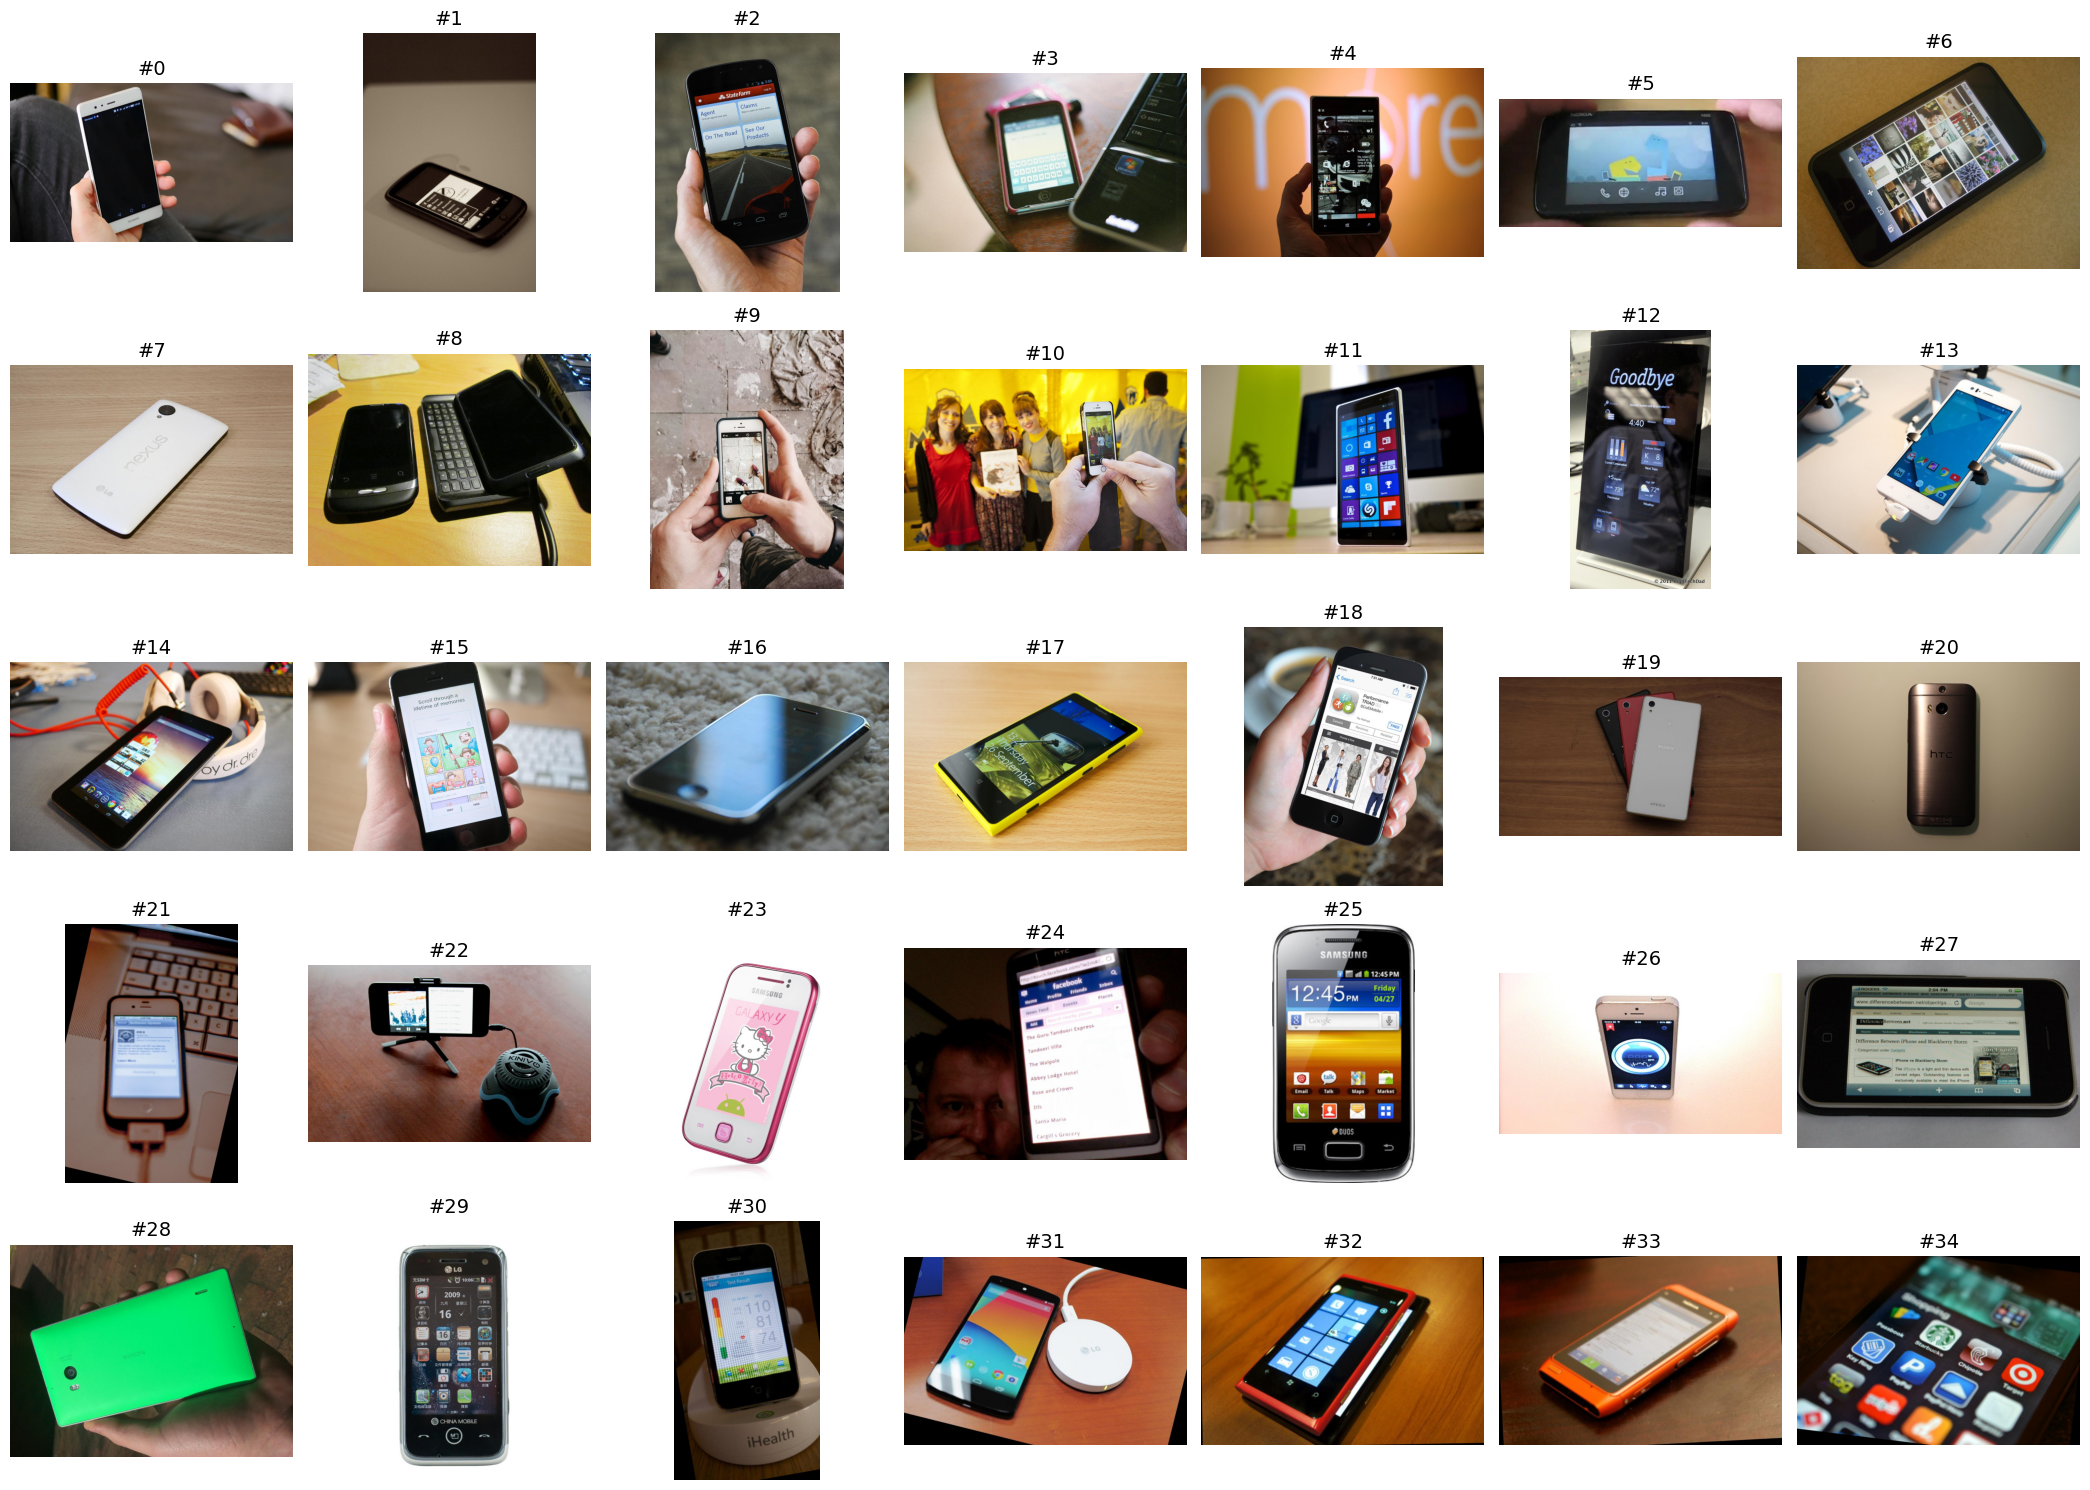

In [61]:
# Show the 35 phone photos for hand labelling
fig, axes = plt.subplots(5, 7, figsize=(21, 15))
for ax, idx in zip(axes.ravel(), range(35)):
    ax.imshow(images[idx]["image"])
    ax.set_title(f"#{idx}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [62]:
# Hand labels for the 35 phone photos
#hand label format img_index: color, held in hand (yes/no)
hand_labels_text = """
0: white, yes
1: black, no
2: black, yes
3: black, no
4: black, yes
5: black, yes
6: black, no
7: white, no
8: black, no
9: white, yes
10: white, yes
11: black, no
12: black, no
13: white, no
14: black, no
15: black, yes
16: black, no
17: yellow, no
18: black, yes
19: black/red/white, no
20: unsure, no
21: white, no
22: black, no
23: pink, no
24: unsure, yes
25: black, no
26: white, no
27: black, no
28: green, yes
29: black, no
30: black, no
31: black, no
32: red, no
33: red, no
34: black, no
"""

rows = []
for line in hand_labels_text.strip().split("\n"):
    idx, values = line.split(":")
    colour, held = values.split(",")
    rows.append({"index": int(idx), "colour": colour.strip(), "held": held.strip()})

hand_labels = pd.DataFrame(rows)
hand_labels.to_csv(OUTPUT_DIR / "phone_hand_labels.csv", index=False)

print(hand_labels["colour"].value_counts())
print(hand_labels["held"].value_counts())

colour
black              20
white               7
red                 2
unsure              2
black/red/white     1
yellow              1
pink                1
green               1
Name: count, dtype: int64
held
no     25
yes    10
Name: count, dtype: int64


**Attribute queries: group labels only vs full method**

New queries on colour and hand-holding, checked against our hand labels, show whether image details improve matching beyond the group labels.

In [63]:
# Attribute queries — group labels only vs full method
# Ground truth for each new query: which phone photos are correct (from hand labels)
attribute_queries = {
    "a black phone": hand_labels["colour"].str.contains("black"),
    "a white phone": hand_labels["colour"].str.contains("white"),
    "a red phone": hand_labels["colour"].str.contains("red"),
    "a phone held in a hand": hand_labels["held"] == "yes",
    "a white phone held in a hand": hand_labels["colour"].str.contains("white") & (hand_labels["held"] == "yes"),
}
unsure_colour = hand_labels.loc[hand_labels["colour"] == "unsure", "index"].tolist()

# Group-labels-only embeddings (no VLM details)
group_embeddings = embedding_model.encode(
    captions_df["clean_label"].tolist(), convert_to_numpy=True, normalize_embeddings=True)

rows = []
for query, is_correct in attribute_queries.items():
    true_indices = set(hand_labels.loc[is_correct, "index"])
    skip = set(unsure_colour) if "held" not in query or "white" in query else set()

    #  group labels only
    query_embedding = embedding_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)[0]
    group_scores = group_embeddings @ query_embedding
    group_matches = set(captions_df.loc[group_scores >= MATCH_THRESHOLD, "index"]) - skip

    # full method (clean label + VLM caption + VQA)
    full_matches = set(find_matching_images(query, confident_score=CONFIDENT_SCORE)["index"]) - skip

    for method, matched in [("group labels only", group_matches), ("full method", full_matches)]:
        correct = len(matched & true_indices)
        precision = correct / len(matched) if len(matched) > 0 else 0
        recall = correct / len(true_indices - skip)
        rows.append({"query": query, "method": method, "matched": len(matched),
                     "precision": round(precision, 2), "recall": round(recall, 2)})

attribute_results = pd.DataFrame(rows)
attribute_results.to_csv(OUTPUT_DIR / "attribute_query_results.csv", index=False)
display(attribute_results)
display(attribute_results.groupby("method")[["precision", "recall"]].mean().round(2))

,query,method,matched,precision,recall
0,a black phone,group labels only,68,0.31,1.00
1,a black phone,full method,39,0.46,0.86
2,a white phone,group labels only,68,0.12,1.00
3,a white phone,full method,47,0.17,1.00
4,a red phone,group labels only,68,0.04,1.00
5,a red phone,full method,14,0.21,1.00
6,a phone held in a hand,group labels only,70,0.14,1.00
7,a phone held in a hand,full method,44,0.20,0.90
8,a white phone held in a hand,group labels only,68,0.04,1.00
9,a white phone held in a hand,full method,42,0.07,1.00


,precision,recall
method,,
full method,0.22,0.95
group labels only,0.13,1.00


**VQA on all candidates for attribute queries**

High-score candidates skipped VQA, so colour was never checked. We test VQA on every candidate for attribute queries.

In [64]:
# Attribute queries with VQA on every candidate
rows = []
for query, is_correct in attribute_queries.items():
    true_indices = set(hand_labels.loc[is_correct, "index"])
    skip = set(unsure_colour) if "held" not in query or "white" in query else set()

    # confident_score above 1 means every candidate is checked by VQA
    matches = set(find_matching_images(query, confident_score=1.01)["index"]) - skip

    correct = len(matches & true_indices)
    precision = correct / len(matches) if len(matches) > 0 else 0
    recall = correct / len(true_indices - skip)
    rows.append({"query": query, "matched": len(matches),
                 "precision": round(precision, 2), "recall": round(recall, 2)})

attribute_vqa_all = pd.DataFrame(rows)
display(attribute_vqa_all)
print(attribute_vqa_all[["precision", "recall"]].mean().round(2))

,query,matched,precision,recall
0,a black phone,21,0.71,0.71
1,a white phone,20,0.40,1.00
2,a red phone,11,0.27,1.00
3,a phone held in a hand,9,1.00,0.90
4,a white phone held in a hand,3,1.00,1.00


precision    0.68
recall       0.92
dtype: float64


Why are some "red phone" picks wrong? Let's look at them.

Wrong picks: 8


,index,original_caption,vlm_caption,score
87,87,An app icon of the smartphone representing the...,A red rotary telephone with a white dial and e...,0.608284
95,95,An app icon of the smartphone representing the...,A glossy red rotary telephone with a coiled re...,0.595662
89,89,An app icon of the smartphone representing the...,A brown rotary telephone with a white base and...,0.570759
23,23,A photo of a real mobile phone.,A pink Samsung Galaxy Y smartphone with a Hell...,0.558685
85,85,An app icon of the smartphone representing the...,A retro-style orange rotary telephone with a y...,0.552280
3,3,A photo of a real mobile phone.,A pink smartphone with a visible keyboard inte...,0.540481
101,101,An app icon of the smartphone representing the...,A glossy orange rotary telephone with a matchi...,0.537288
94,94,An app icon of the smartphone representing the...,A vintage-style rotary telephone with a pinkis...,0.506066


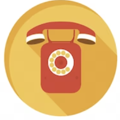

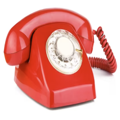

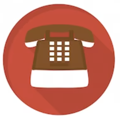

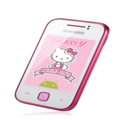

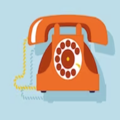

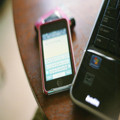

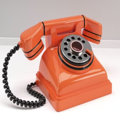

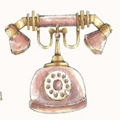

In [65]:
#Show the wrong picks for "a red phone"
query = "a red phone"
true_indices = set(hand_labels.loc[attribute_queries[query], "index"])
matches = find_matching_images(query, confident_score=1.01)

wrong = matches[~matches["index"].isin(true_indices)]
print("Wrong picks:", len(wrong))
display(wrong[["index", "original_caption", "vlm_caption", "score"]])

for idx in wrong["index"]:
    display(images[int(idx)]["image"].resize((120, 120)))

**Final matcher: route by query type**

Attribute queries (colour or hand) use VQA on every candidate. Category queries use VQA only for borderline scores.
The wrong picks were red rotary telephones (they are red phones, so the query is unclear), close colours (orange, pink, brown) and one wrong caption.


In [67]:
#Final matcher that chooses the VQA rule by query type
ATTRIBUTE_WORDS = ["black", "white", "red", "pink", "blue", "green", "yellow", "gold",
                   "silver", "grey", "gray", "orange", "purple", "brown",
                   "hand", "held", "holding"]

def match_images(query):
    """Final image matcher used by the app."""
    is_attribute_query = any(word in query.lower() for word in ATTRIBUTE_WORDS)
    if is_attribute_query:
        return find_matching_images(query, confident_score=1.01)          # VQA on all candidates
    return find_matching_images(query, confident_score=CONFIDENT_SCORE)   # VQA on borderline only


# Quick check of the routing
for query in ["a phone call icon", "a red smartphone", "someone holding a smartphone"]:
    rule = "VQA on all" if any(w in query.lower() for w in ATTRIBUTE_WORDS) else "borderline VQA"
    print(f"{query!r} -> {rule}")

'a phone call icon' -> borderline VQA
'a red smartphone' -> VQA on all
'someone holding a smartphone' -> VQA on all


## 1.2 Slogan generation
The VLM looks at the chosen image and writes a short slogan for the audience. Facts must come only from what is visible in the image.

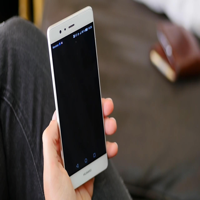

young tech-savvy users: Meet the Huawei Mate 9 — sleek, smart, and ready for your next big move.
busy professionals: Stay connected, work smarter—your Huawei phone, ready for the hustle.
senior citizens: Easy to use, big screen, long battery life.


In [68]:
# Generate a slogan from the image
def generate_slogan(image, audience):
    """Ask the VLM for a short slogan for this product and audience."""
    prompt = (
        f"You are an advertising copywriter for a phone shop. "
        f"Write one catchy sales slogan for the product in this image, aimed at {audience}. "
        f"Only mention features you can see in the image. Do not invent specifications. "
        f"Maximum 10 words. Output only the slogan."
    )
    slogan = generate_caption_from_image(image, text_prompt=prompt, max_new_tokens=30)
    return slogan.strip().strip('"')


# Test: one image, three audiences
idx = 0
display(images[idx]["image"].resize((200, 200)))
for audience in ["young tech-savvy users", "busy professionals", "senior citizens"]:
    print(f"{audience}: {generate_slogan(images[idx]['image'], audience)}")

**Updating the Slogan generation prompt**

Version 1 prompt made up facts ("Mate 9", "long battery life") and went over 10 words. Version 2 prompt forbids unseen claims, asks for one visible detail, and checks the word count and risky words.

In [69]:
#Slogan prompt update with rule checks
RISKY_WORDS = ["battery", "camera", "mp", "gb", "storage", "fast", "speed",
               "processor", "mate", "galaxy", "iphone", "pixel", "5g"]

def generate_slogan(image, audience):
    """Slogan using only visible features, aimed at the audience."""
    prompt = (
        f"You are an advertising copywriter for a phone shop.\n"
        f"Write one sales slogan for the product in this image, aimed at {audience}.\n"
        f"Rules:\n"
        f"- Use only what you can see: colour, design, shape, how it is used.\n"
        f"- Mention at least one visible detail, such as the colour.\n"
        f"- Do not mention brand or model names, battery, camera, storage, or speed.\n"
        f"- Focus on a feeling or benefit that matters to {audience}.\n"
        f"- Maximum 10 words. Output only the slogan.\n"
        f"Examples:\n"
        f"- Sleek white style that fits right in your hand.\n"
        f"- Bold colour, clear screen, made for everyday moments."
    )
    slogan = generate_caption_from_image(image, text_prompt=prompt, max_new_tokens=30)
    return slogan.strip().strip('"')


def check_slogan(slogan):
    """Return word count and any risky claim words found."""
    words = slogan.lower().replace(",", " ").replace(".", " ").split()
    risky = [w for w in RISKY_WORDS if w in words]
    return len(words), risky


idx = 0
for audience in ["young tech-savvy users", "busy professionals", "senior citizens"]:
    slogan = generate_slogan(images[idx]["image"], audience)
    n_words, risky = check_slogan(slogan)
    print(f"{audience}: {slogan}")
    print(f"   words: {n_words} | risky words: {risky}\n")

young tech-savvy users: Bold white design, sleek touch, ready for your next big idea.
   words: 11 | risky words: []

busy professionals: Clean white design, perfect for your busy day.
   words: 8 | risky words: []

senior citizens: Soft touch, clear screen, easy to hold and use.
   words: 9 | risky words: []



**Overlay the slogan on the image**

Tests overlaying working on an image

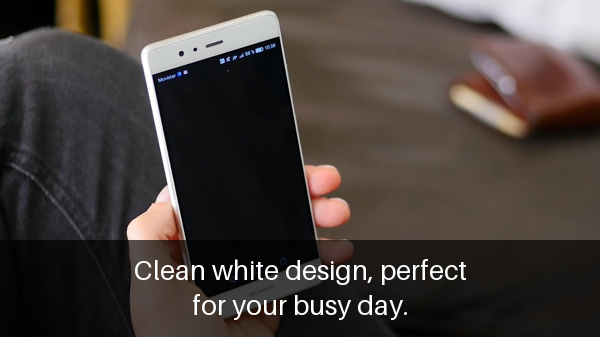

In [70]:
#Overlaying the slogan on the image
import textwrap
from PIL import Image, ImageDraw, ImageFont

FONT_PATH = "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"   # font included in Colab

def add_slogan_to_image(image, slogan, width=600):
    """Return a new image with the slogan on a dark band at the bottom."""
    # Resize to a fixed width so every ad looks consistent
    slogan = slogan.replace("—", " - ").replace("–", " - ")   # characters the font may not draw
    image = image.convert("RGB")
    height = int(image.height * width / image.width)
    ad = image.resize((width, height)).convert("RGBA")

    # Font size based on image width
    font_size = max(width, height) // 22   # bigger text for tall images too
    try:
        font = ImageFont.truetype(FONT_PATH, font_size)
    except OSError:
        font = ImageFont.load_default(size=font_size)

    # Wrap the slogan into lines that fit the width
    lines = textwrap.wrap(slogan, width=28)
    line_height = int(font_size * 1.3)
    band_height = line_height * len(lines) + font_size

    # Semi-transparent dark band at the bottom
    band = Image.new("RGBA", ad.size, (0, 0, 0, 0))
    draw_band = ImageDraw.Draw(band)
    draw_band.rectangle([(0, height - band_height), (width, height)], fill=(0, 0, 0, 170))
    ad = Image.alpha_composite(ad, band)

    # White text, centred on each line
    draw = ImageDraw.Draw(ad)
    y = height - band_height + font_size // 2
    for line in lines:
        text_width = draw.textlength(line, font=font)
        draw.text(((width - text_width) / 2, y), line, font=font, fill="white")
        y += line_height

    return ad.convert("RGB")


slogan = "Clean white design, perfect for your busy day."
display(add_slogan_to_image(images[0]["image"], slogan))

**Full advertisement test: slogan + overlay**

- Each audience gets a short note on what it cares about, so slogans differ more.
- If a slogan has a risky word, we try once more with a stricter rule.
- We removed the Few-shot example slogans because the model copied them (e.g. "fits right in your hand" for a speech bubble).

Tested on 3 images × 3 audiences.

`generate_slogan` function is rewritten to add audience interests (with a fallback for any new audience) so slogans differ more between audiences. Earlier versions are kept above as a record of the prompt changes.

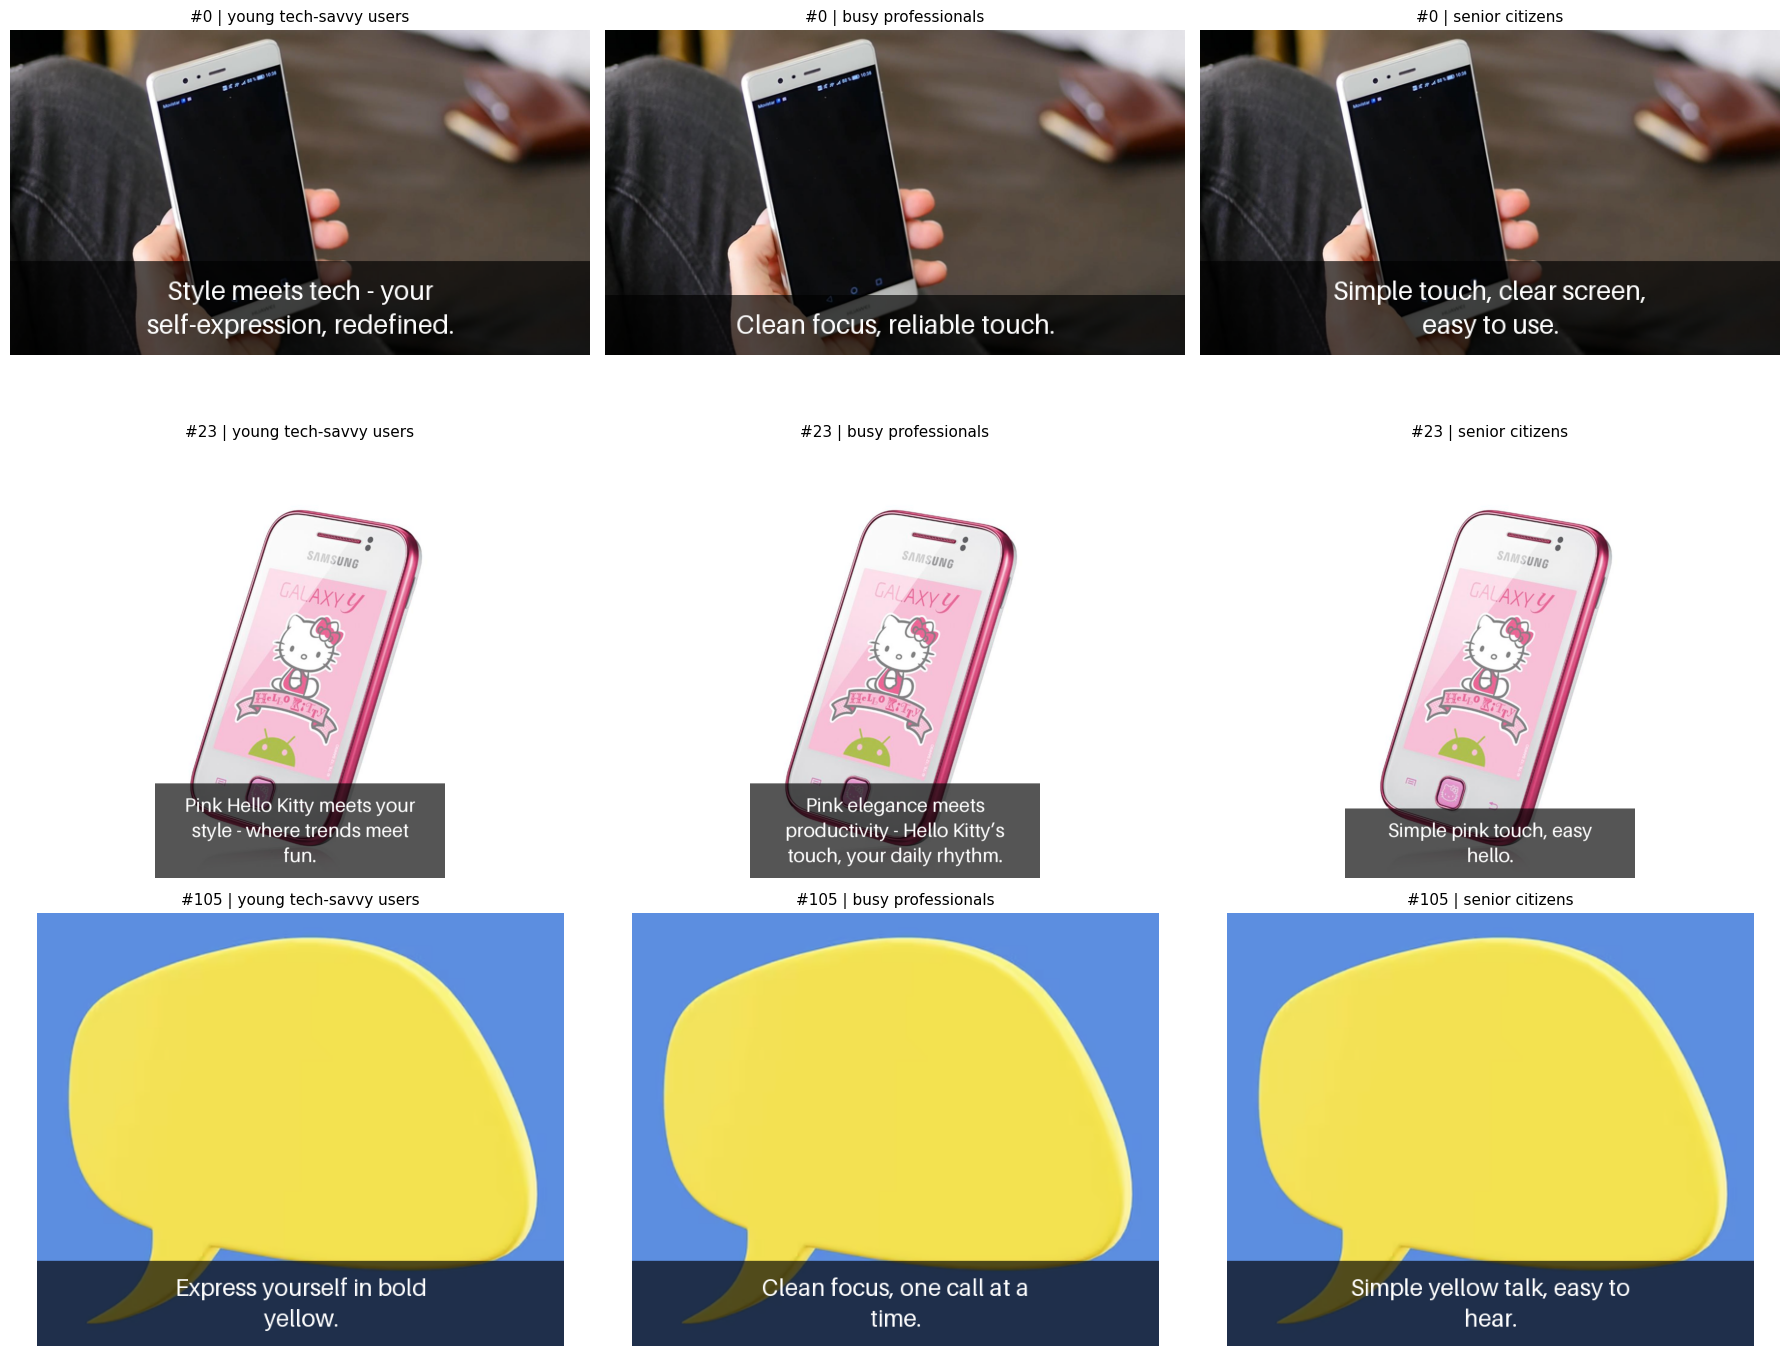

,index,audience,slogan,words,risky_words
0,0,young tech-savvy users,"Style meets tech—your self-expression, redefined.",5,[]
1,0,busy professionals,"Clean focus, reliable touch.",4,[]
2,0,senior citizens,"Simple touch, clear screen, easy to use.",7,[]
3,23,young tech-savvy users,Pink Hello Kitty meets your style—where trends meet fun.,9,[]
4,23,busy professionals,"Pink elegance meets productivity—Hello Kitty’s touch, your daily rhythm.",9,[]
5,23,senior citizens,"Simple pink touch, easy hello.",5,[]
6,105,young tech-savvy users,Express yourself in bold yellow.,5,[]
7,105,busy professionals,"Clean focus, one call at a time.",7,[]
8,105,senior citizens,"Simple yellow talk, easy to hear.",6,[]


In [71]:
# Full advertisement with audience descriptions, tested on 3 images and audiences
AUDIENCE_INTERESTS = {
    "young tech-savvy users": "they care about style, trends and self-expression",
    "busy professionals": "they care about productivity, reliability and a clean look",
    "senior citizens": "they care about simplicity, comfort and ease of use",
}

RISKY_WORDS = ["battery", "camera", "mp", "gb", "storage", "fast", "speed",
               "processor", "mate", "galaxy", "iphone", "pixel", "5g", "voice", "sound"]


def generate_slogan(image, audience, extra_rule=""):
    """Slogan using only visible features, aimed at the audience and its interests."""
    interests = AUDIENCE_INTERESTS.get(audience, "think about what this audience cares about")
    prompt = (
        f"You are an advertising copywriter for a phone shop.\n"
        f"Write one sales slogan for the product in this image, aimed at {audience} ({interests}).\n"
        f"Rules:\n"
        f"- Use only what you can see: colour, design, shape, how it is used.\n"
        f"- Mention at least one visible detail, such as the colour.\n"
        f"- Do not mention brand or model names, battery, camera, storage, speed, or sound.\n"
        f"- Focus on a feeling or benefit that matters to this audience.\n"
        f"- About 10 words. Output only the slogan.\n"
        f"{extra_rule}"
        f"- Write an original slogan for this specific image."
    )
    slogan = generate_caption_from_image(image, text_prompt=prompt, max_new_tokens=30)
    return slogan.strip().strip('"')


def make_advertisement(image, audience):
    """Generate a checked slogan and put it on the image."""
    slogan = generate_slogan(image, audience)
    n_words, risky = check_slogan(slogan)
    if risky:   # retry once with a stricter rule naming the risky words
        extra_rule = f"- Important: do not use these words: {', '.join(risky)}.\n"
        slogan = generate_slogan(image, audience, extra_rule=extra_rule)
        n_words, risky = check_slogan(slogan)
    return add_slogan_to_image(image, slogan), slogan, n_words, risky


test_images = [0, 23, 105]      # white phone in hand, pink phone, speech bubble icon
test_audiences = list(AUDIENCE_INTERESTS.keys())

ad_rows = []
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for row, idx in enumerate(test_images):
    for col, audience in enumerate(test_audiences):
        ad, slogan, n_words, risky = make_advertisement(images[idx]["image"], audience)
        axes[row, col].imshow(ad)
        axes[row, col].set_title(f"#{idx} | {audience}", fontsize=11)
        axes[row, col].axis("off")
        ad_rows.append({"index": idx, "audience": audience, "slogan": slogan,
                        "words": n_words, "risky_words": risky})
plt.tight_layout()
plt.show()

ad_results = pd.DataFrame(ad_rows)
ad_results.to_csv(OUTPUT_DIR / "slogan_results.csv", index=False)
pd.set_option("display.max_colwidth", None)   # show full slogans
display(ad_results)

**Test a new audience (fallback)**
"Gamers" is not in AUDIENCE_INTERESTS, so the model must work out what they care about by itself.

In AUDIENCE_INTERESTS? False


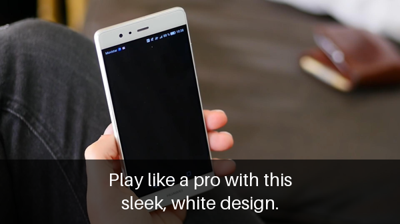

#0 | Play like a pro with this sleek, white design. | words: 9 | risky: []



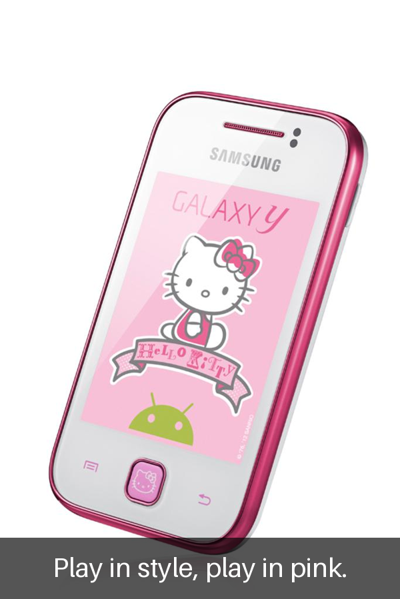

#23 | Play in style, play in pink. | words: 6 | risky: []



In [72]:
# Testing a fallback audience not in the dictionary
audience = "gamers"
print("In AUDIENCE_INTERESTS?", audience in AUDIENCE_INTERESTS)

for idx in [0, 23]:
    ad, slogan, n_words, risky = make_advertisement(images[idx]["image"], audience)
    display(ad.resize((400, int(ad.height * 400 / ad.width))))
    print(f"#{idx} | {slogan} | words: {n_words} | risky: {risky}\n")

## 1.3 Advanced feature: auto-layout
The fixed bottom band often covers the product. Auto-layout puts the text where it covers the least of the product.

**Try 1:** put text in the area with the fewest edges.

In [73]:
#Measure how busy each area of an image is
from PIL import ImageFilter

def area_busyness(image, position, band_fraction=0.25):
    """Average edge strength in the top, middle or bottom band of the image."""
    gray = image.convert("L")                         # black-and-white copy
    edges = np.array(gray.filter(ImageFilter.FIND_EDGES))
    height = edges.shape[0]
    band = int(height * band_fraction)

    if position == "top":
        area = edges[:band]
    elif position == "middle":
        area = edges[(height - band) // 2 : (height + band) // 2]
    else:  # bottom
        area = edges[height - band:]
    return area.mean()


for idx in [0, 23, 105]:
    scores = {pos: round(area_busyness(images[idx]["image"], pos), 1) for pos in ["top", "middle", "bottom"]}
    print(f"#{idx}: {scores} -> calmest: {min(scores, key=scores.get)}")

#0: {'top': np.float64(3.3), 'middle': np.float64(1.7), 'bottom': np.float64(2.1)} -> calmest: middle
#23: {'top': np.float64(6.1), 'middle': np.float64(9.3), 'bottom': np.float64(7.3)} -> calmest: top
#105: {'top': np.float64(1.6), 'middle': np.float64(0.6), 'bottom': np.float64(1.5)} -> calmest: middle


**Find a free area with the VLM**

Try 1 failed: plain products (a black screen, a yellow bubble) have few edges, so they looked "empty".

**Try 2:** crop the top and bottom bands and ask the VLM if the product is there.

In [74]:
# Choose the text position with the VLM
def crop_band(image, position, band_fraction=0.25):
    """Return the top or bottom band of the image."""
    band = int(image.height * band_fraction)
    if position == "top":
        return image.crop((0, 0, image.width, band))
    return image.crop((0, image.height - band, image.width, image.height))


def band_has_product(image, position):
    """Ask the VLM if this band shows part of the main object."""
    question = "Does this image show any part of a phone, a hand, or the main object? Answer only yes or no."
    answer = generate_caption_from_image(crop_band(image, position), text_prompt=question, max_new_tokens=5)
    return answer.lower().startswith("yes")


def choose_text_position(image):
    """Pick top or bottom: prefer a band without the product, then the calmer band."""
    has_product = {pos: band_has_product(image, pos) for pos in ["top", "bottom"]}
    free = [pos for pos in ["top", "bottom"] if not has_product[pos]]

    if len(free) == 1:
        return free[0], has_product
    # both free or both covered: choose the calmer band
    calmer = min(["top", "bottom"], key=lambda pos: area_busyness(image, pos))
    return calmer, has_product


for idx in [0, 23, 105]:
    position, has_product = choose_text_position(images[idx]["image"])
    print(f"#{idx}: product in band -> {has_product} | text goes: {position}")

#0: product in band -> {'top': True, 'bottom': True} | text goes: bottom
#23: product in band -> {'top': True, 'bottom': True} | text goes: top
#105: product in band -> {'top': False, 'bottom': False} | text goes: bottom


**Find the product's exact position**

Try 2 was too rough: the product usually reaches both bands.

**Try 3:** ask the VLM for a box around the product.

#0: VLM answer -> [233, 34, 537, 942]


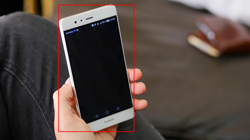

#23: VLM answer -> [122, 150, 922, 927]


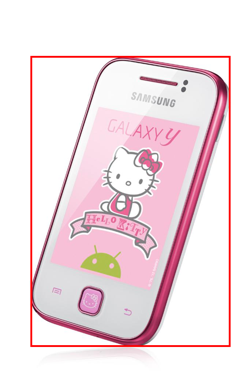

#105: VLM answer -> [68, 46, 959, 946]


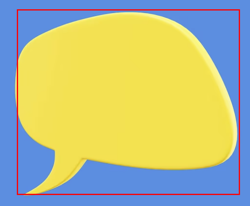

In [75]:
# Ask the VLM for the product's bounding box
import re

def find_product_box(image):
    """Ask the VLM for the main object's box. Returns (x1, y1, x2, y2) in pixels, or None."""
    question = ("Find the main object in this image. Give its bounding box as "
                "[x1, y1, x2, y2] using coordinates from 0 to 1000. Output only the four numbers.")
    answer = generate_caption_from_image(image, text_prompt=question, max_new_tokens=30)
    numbers = [int(n) for n in re.findall(r"\d+", answer)][:4]
    if len(numbers) < 4:
        return None, answer
    x1, y1, x2, y2 = numbers
    box = (x1 * image.width / 1000, y1 * image.height / 1000,
           x2 * image.width / 1000, y2 * image.height / 1000)
    return box, answer


for idx in [0, 23, 105]:
    image = images[idx]["image"].convert("RGB")
    box, answer = find_product_box(image)
    print(f"#{idx}: VLM answer -> {answer}")
    if box:
        preview = image.copy()
        ImageDraw.Draw(preview).rectangle(box, outline="red", width=5)
        display(preview.resize((250, int(250 * image.height / image.width))))

**Auto-layout overlay test**

The boxes are accurate. Now we try 4 text positions (top, bottom, left, right) and pick the one that covers the least of the product box.

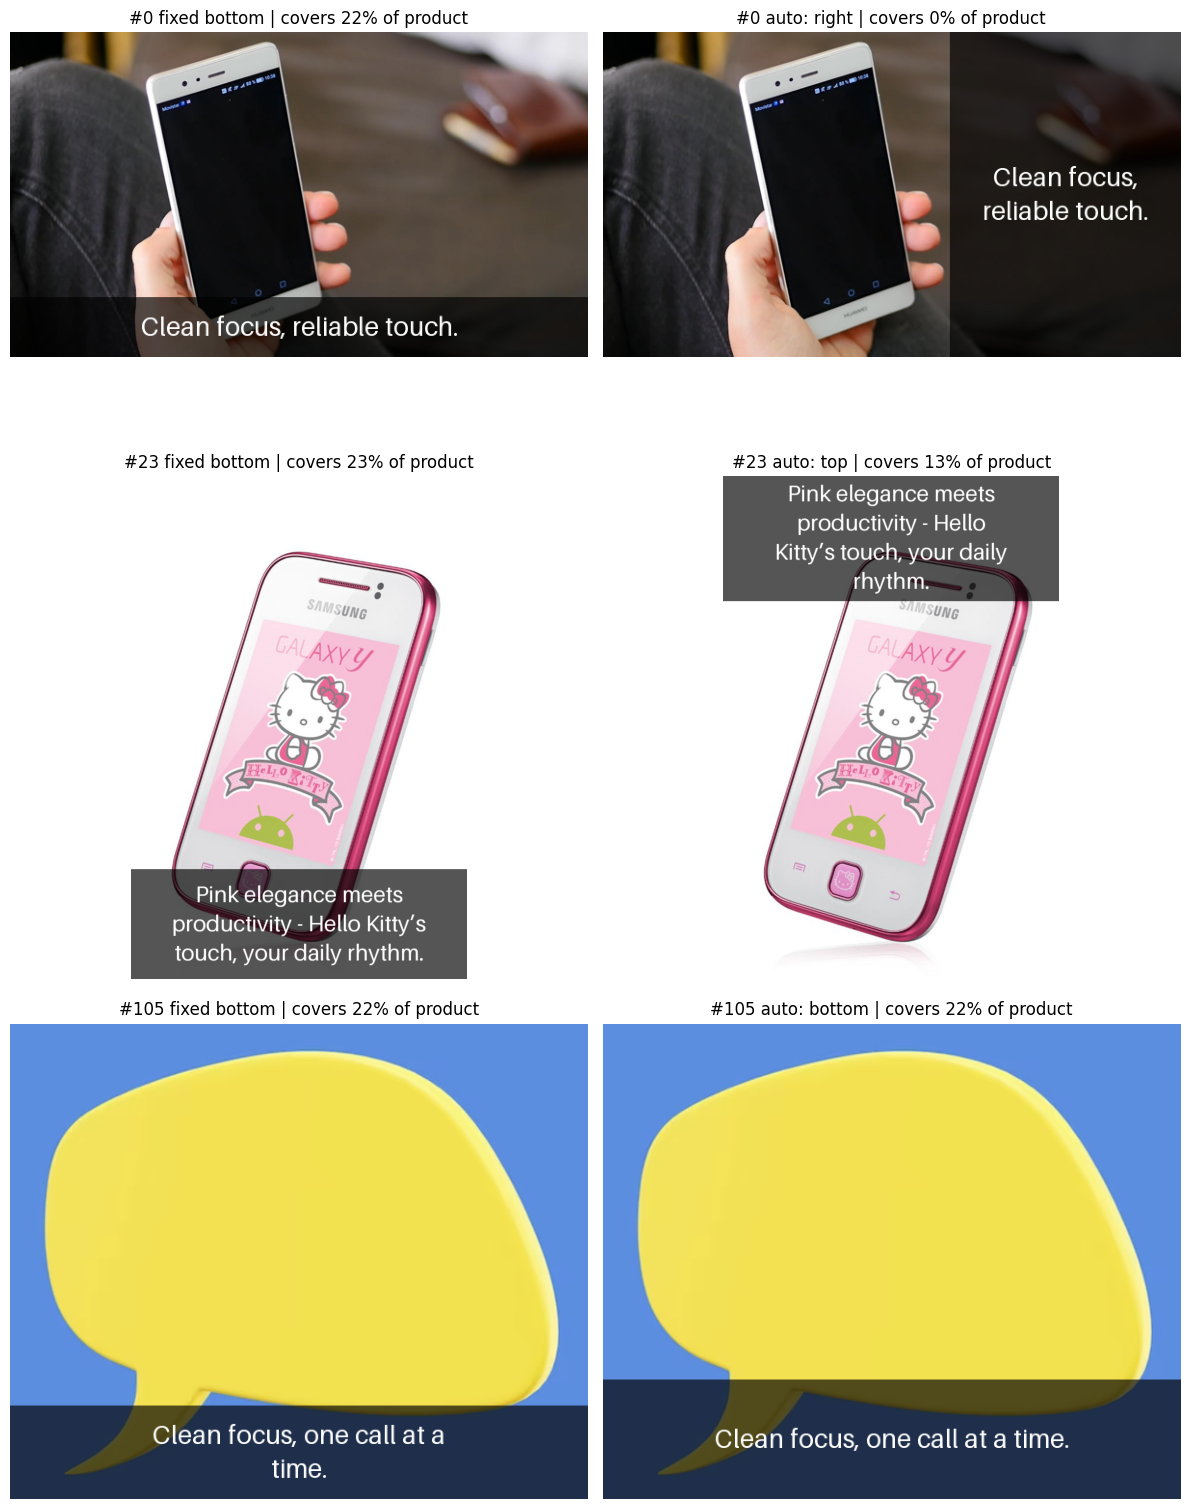

In [76]:
#Auto-layout: choose the position that covers the least product
def panel_box(width, height, position):
    """Rectangle for the text panel: top/bottom bands (25% height) or left/right columns (40% width)."""
    if position == "top":
        return (0, 0, width, int(height * 0.25))
    if position == "bottom":
        return (0, int(height * 0.75), width, height)
    if position == "left":
        return (0, 0, int(width * 0.4), height)
    return (int(width * 0.6), 0, width, height)   # right


def overlap_fraction(product_box, panel):
    """Share of the product box covered by the text panel (0 = none, 1 = all)."""
    x1 = max(product_box[0], panel[0])
    y1 = max(product_box[1], panel[1])
    x2 = min(product_box[2], panel[2])
    y2 = min(product_box[3], panel[3])
    if x2 <= x1 or y2 <= y1:
        return 0.0
    covered = (x2 - x1) * (y2 - y1)
    product_area = (product_box[2] - product_box[0]) * (product_box[3] - product_box[1])
    return covered / product_area


def draw_slogan_in_panel(image, slogan, panel):
    """Draw a dark see-through panel and white wrapped text inside it."""
    slogan = slogan.replace("—", " - ").replace("–", " - ")
    ad = image.convert("RGBA")
    font_size = max(ad.width, ad.height) // 22
    try:
        font = ImageFont.truetype(FONT_PATH, font_size)
    except OSError:
        font = ImageFont.load_default(size=font_size)

    panel_width = panel[2] - panel[0]
    chars_per_line = max(8, int(panel_width / (font_size * 0.55)))
    lines = textwrap.wrap(slogan, width=chars_per_line)
    line_height = int(font_size * 1.3)

    layer = Image.new("RGBA", ad.size, (0, 0, 0, 0))
    ImageDraw.Draw(layer).rectangle(panel, fill=(0, 0, 0, 170))
    ad = Image.alpha_composite(ad, layer)

    draw = ImageDraw.Draw(ad)
    y = panel[1] + ((panel[3] - panel[1]) - line_height * len(lines)) / 2   # centre vertically
    for line in lines:
        text_width = draw.textlength(line, font=font)
        x = panel[0] + (panel_width - text_width) / 2                     # centre horizontally
        draw.text((x, y), line, font=font, fill="white")
        y += line_height
    return ad.convert("RGB")


def auto_layout_ad(image, slogan, width=600):
    """Find the product, test 4 positions, and use the one that covers the least product."""
    image = image.convert("RGB")
    image = image.resize((width, int(image.height * width / image.width)))
    product_box, _ = find_product_box(image)
    if product_box is None:                       # VLM gave no box: use the old bottom band
        return draw_slogan_in_panel(image, slogan, panel_box(image.width, image.height, "bottom")), "bottom", {}

    overlaps = {pos: overlap_fraction(product_box, panel_box(image.width, image.height, pos))
                for pos in ["top", "bottom", "left", "right"]}
    best = min(overlaps, key=overlaps.get)
    ad = draw_slogan_in_panel(image, slogan, panel_box(image.width, image.height, best))
    return ad, best, overlaps


# Compare fixed bottom vs auto-layout on 3 images (busy professionals slogans)
fig, axes = plt.subplots(3, 2, figsize=(12, 16))
for row, idx in enumerate([0, 23, 105]):
    slogan = ad_results[(ad_results["index"] == idx) &
                        (ad_results["audience"] == "busy professionals")]["slogan"].iloc[0]
    fixed_ad = add_slogan_to_image(images[idx]["image"], slogan)
    auto_ad, position, overlaps = auto_layout_ad(images[idx]["image"], slogan)

    axes[row, 0].imshow(fixed_ad)
    axes[row, 0].set_title(f"#{idx} fixed bottom | covers {overlaps.get('bottom', 0):.0%} of product")
    axes[row, 1].imshow(auto_ad)
    axes[row, 1].set_title(f"#{idx} auto: {position} | covers {overlaps.get(position, 0):.0%} of product")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

**Panel sized to the text**

Fix: a fixed 25% band was too tall for image #23 and covered the phone. Top and bottom panels now match the text height.

Position: top | overlaps: {'top': '9%', 'bottom': '19%', 'left': '35%', 'right': '40%'}


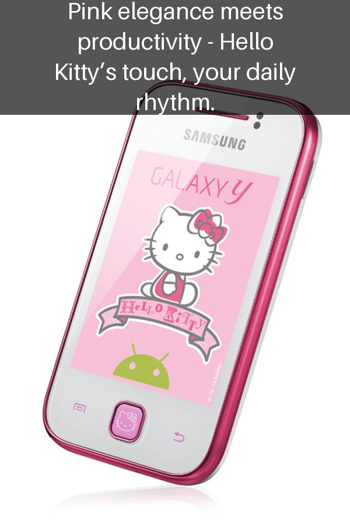

In [77]:
# Top/bottom panels sized to the text
def text_band_height(slogan, width, height):
    """Height needed for the slogan when written across the full width."""
    font_size = max(width, height) // 22
    chars_per_line = max(8, int(width / (font_size * 0.55)))
    n_lines = len(textwrap.wrap(slogan, width=chars_per_line))
    return int(n_lines * font_size * 1.3 + font_size)     # lines + padding


def panel_box(width, height, position, band_height=None):
    """Top/bottom bands use the text height; left/right columns use 40% width."""
    if band_height is None:
        band_height = int(height * 0.25)
    if position == "top":
        return (0, 0, width, band_height)
    if position == "bottom":
        return (0, height - band_height, width, height)
    if position == "left":
        return (0, 0, int(width * 0.4), height)
    return (int(width * 0.6), 0, width, height)   # right


def auto_layout_ad(image, slogan, width=600):
    """Find the product, test 4 positions, and use the one that covers the least product."""
    image = image.convert("RGB")
    image = image.resize((width, int(image.height * width / image.width)))
    band_height = text_band_height(slogan, image.width, image.height)
    product_box, _ = find_product_box(image)

    if product_box is None:   # VLM gave no box: use the bottom band
        panel = panel_box(image.width, image.height, "bottom", band_height)
        return draw_slogan_in_panel(image, slogan, panel), "bottom", {}

    overlaps = {pos: overlap_fraction(product_box, panel_box(image.width, image.height, pos, band_height))
                for pos in ["top", "bottom", "left", "right"]}
    best = min(overlaps, key=overlaps.get)
    panel = panel_box(image.width, image.height, best, band_height)
    return draw_slogan_in_panel(image, slogan, panel), best, overlaps


# Re-test #23 (the problem case)
idx = 23
slogan = ad_results[(ad_results["index"] == idx) &
                    (ad_results["audience"] == "busy professionals")]["slogan"].iloc[0]
auto_ad, position, overlaps = auto_layout_ad(images[idx]["image"], slogan)
print("Position:", position, "| overlaps:", {k: f"{v:.0%}" for k, v in overlaps.items()})
display(auto_ad.resize((350, int(auto_ad.height * 350 / auto_ad.width))))

**Fixed font size and text measurement**

Fix: the font was too big on tall images and text spilled out. Font size now uses the width, and line breaks are measured in pixels.

Position: top | overlaps: {'top': '4%', 'bottom': '14%', 'left': '35%', 'right': '40%'}


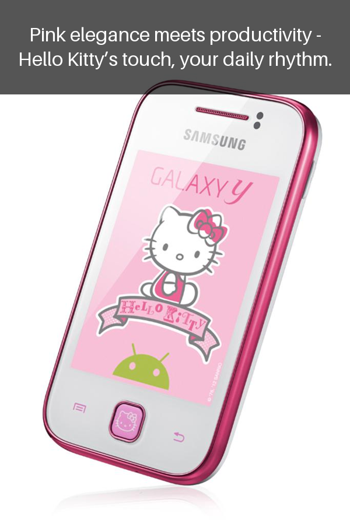

In [78]:
#Fixed font size and measuring real text height
def get_font(width):
    """Same font size for measuring and drawing: based on image width."""
    font_size = width // 18
    try:
        return ImageFont.truetype(FONT_PATH, font_size), font_size
    except OSError:
        return ImageFont.load_default(size=font_size), font_size


def wrap_slogan(slogan, panel_width, font):
    """Split the slogan into lines that really fit the panel width (measured in pixels)."""
    draw = ImageDraw.Draw(Image.new("RGB", (1, 1)))
    lines, current = [], ""
    for word in slogan.split():
        test = (current + " " + word).strip()
        if draw.textlength(test, font=font) <= panel_width * 0.9:
            current = test
        else:
            lines.append(current)
            current = word
    lines.append(current)
    return lines


def text_band_height(slogan, width, height):
    """Height needed for the slogan across the full width (real measurement)."""
    font, font_size = get_font(width)
    lines = wrap_slogan(slogan, width, font)
    return int(len(lines) * font_size * 1.3 + font_size)


def draw_slogan_in_panel(image, slogan, panel):
    """Dark see-through panel with white wrapped text, centred inside it."""
    slogan = slogan.replace("—", " - ").replace("–", " - ")
    ad = image.convert("RGBA")
    font, font_size = get_font(ad.width)
    lines = wrap_slogan(slogan, panel[2] - panel[0], font)
    line_height = int(font_size * 1.3)

    layer = Image.new("RGBA", ad.size, (0, 0, 0, 0))
    ImageDraw.Draw(layer).rectangle(panel, fill=(0, 0, 0, 170))
    ad = Image.alpha_composite(ad, layer)

    draw = ImageDraw.Draw(ad)
    y = panel[1] + ((panel[3] - panel[1]) - line_height * len(lines)) / 2
    for line in lines:
        x = panel[0] + ((panel[2] - panel[0]) - draw.textlength(line, font=font)) / 2
        draw.text((x, y), line, font=font, fill="white")
        y += line_height
    return ad.convert("RGB")


# Re-test #23
idx = 23
slogan = ad_results[(ad_results["index"] == idx) &
                    (ad_results["audience"] == "busy professionals")]["slogan"].iloc[0]
auto_ad, position, overlaps = auto_layout_ad(images[idx]["image"], slogan)
print("Position:", position, "| overlaps:", {k: f"{v:.0%}" for k, v in overlaps.items()})
display(auto_ad.resize((350, int(auto_ad.height * 350 / auto_ad.width))))

**Evaluate auto-layout on all images**

For all 140 images we compare how much of the product is covered: fixed bottom band vs auto-layout. Product boxes are saved to a CSV.

In [79]:
#Fixed bottom vs auto-layout on all 140 images
BOXES_FILE = OUTPUT_DIR / "product_boxes.csv"
test_slogan = "Clean white design, reliable for your busy day."   # same slogan for a fair comparison
width = 600

if BOXES_FILE.exists():
    boxes_df = pd.read_csv(BOXES_FILE)
    print("Loaded saved product boxes:", len(boxes_df))
else:
    rows = []
    for idx in range(len(images)):
        image = images[idx]["image"].convert("RGB")
        image = image.resize((width, int(image.height * width / image.width)))
        box, _ = find_product_box(image)
        rows.append({"index": idx, "img_height": image.height,
                     "x1": box[0] if box else None, "y1": box[1] if box else None,
                     "x2": box[2] if box else None, "y2": box[3] if box else None})
        if (idx + 1) % 20 == 0:
            print(f"Boxes found {idx + 1} / {len(images)}")
    boxes_df = pd.DataFrame(rows)
    boxes_df.to_csv(BOXES_FILE, index=False)

layout_rows = []
for _, row in boxes_df.dropna().iterrows():
    product_box = (row["x1"], row["y1"], row["x2"], row["y2"])
    height = int(row["img_height"])
    band_height = text_band_height(test_slogan, width, height)

    overlaps = {pos: overlap_fraction(product_box, panel_box(width, height, pos, band_height))
                for pos in ["top", "bottom", "left", "right"]}
    best = min(overlaps, key=overlaps.get)
    layout_rows.append({"index": int(row["index"]),
                        "fixed_bottom_overlap": overlaps["bottom"],
                        "auto_position": best,
                        "auto_overlap": overlaps[best]})

layout_results = pd.DataFrame(layout_rows)
layout_results["group"] = layout_results["index"] // 35
layout_results.to_csv(OUTPUT_DIR / "auto_layout_results.csv", index=False)

print("Images with a product box:", len(layout_results), "of", len(images))
print("\nAverage share of product covered by text:")
print(f"  Fixed bottom: {layout_results['fixed_bottom_overlap'].mean():.0%}")
print(f"  Auto-layout:  {layout_results['auto_overlap'].mean():.0%}")
print("\nImages where text covers none of the product:")
print(f"  Fixed bottom: {(layout_results['fixed_bottom_overlap'] == 0).sum()}")
print(f"  Auto-layout:  {(layout_results['auto_overlap'] == 0).sum()}")
print("\nPositions chosen by auto-layout:")
print(layout_results["auto_position"].value_counts())

Boxes found 20 / 140
Boxes found 40 / 140
Boxes found 60 / 140
Boxes found 80 / 140
Boxes found 100 / 140
Boxes found 120 / 140
Boxes found 140 / 140
Images with a product box: 140 of 140

Average share of product covered by text:
  Fixed bottom: 16%
  Auto-layout:  13%

Images where text covers none of the product:
  Fixed bottom: 25
  Auto-layout:  34

Positions chosen by auto-layout:
auto_position
bottom    75
top       55
left       6
right      4
Name: count, dtype: int64


In [80]:
#Auto-layout results by image group
group_names = {0: "phone photo", 1: "avatar icon", 2: "phone icon", 3: "speech bubble icon"}
layout_results["group_name"] = layout_results["group"].map(group_names)

summary = layout_results.groupby("group_name").agg(
    fixed_bottom_overlap=("fixed_bottom_overlap", "mean"),
    auto_overlap=("auto_overlap", "mean"),
    fixed_zero=("fixed_bottom_overlap", lambda s: (s == 0).sum()),
    auto_zero=("auto_overlap", lambda s: (s == 0).sum()),
)
summary["fixed_bottom_overlap"] = (summary["fixed_bottom_overlap"] * 100).round(0)
summary["auto_overlap"] = (summary["auto_overlap"] * 100).round(0)
display(summary)

,fixed_bottom_overlap,auto_overlap,fixed_zero,auto_zero
group_name,,,,
avatar icon,17.0,14.0,2,3
phone icon,15.0,14.0,8,8
phone photo,19.0,9.0,7,15
speech bubble icon,13.0,13.0,8,8


**Result:** on phone photos, auto-layout cut the share of the product covered by text from 19% to 9%, and fully visible adverts went from 7 to 15. Over all 140 images: 16% -> 13% covered, and 25 -> 34 adverts with nothing covered. Icons fill most of the image, so there is little free space and the gain is small.

**Fixes found while testing the app**

Two problems: "black phone" matched a white phone with a black screen, and a slogan copied text from the phone screen. We changed the VQA question and added a slogan rule. Results barely changed, so we record this as a limit of the small 2B model.

In [81]:
#Improved VQA question and slogan rule
def vlm_says_yes(image, query):
    """Ask the VLM whether the image matches the query. Colours refer to the phone body, not the screen."""
    question = (f"Does this image show {query}? "
                f"Judge a phone's colour by its body or case, not its screen. Answer only yes or no.")
    answer = generate_caption_from_image(image, text_prompt=question, max_new_tokens=5)
    return answer.lower().startswith("yes")


def generate_slogan(image, audience, extra_rule=""):
    """Slogan using only visible features of the product, aimed at the audience."""
    interests = AUDIENCE_INTERESTS.get(audience, "think about what this audience cares about")
    prompt = (
        f"You are an advertising copywriter for a phone shop.\n"
        f"Write one sales slogan for the product in this image, aimed at {audience} ({interests}).\n"
        f"Rules:\n"
        f"- Use only what you can see of the product: colour, design, shape, how it is used.\n"
        f"- Do not copy or reuse any text shown on the screen. Describe the product itself.\n"
        f"- Mention at least one visible detail, such as the colour.\n"
        f"- Do not mention brand or model names, battery, camera, storage, speed, or sound.\n"
        f"- Focus on a feeling or benefit that matters to this audience.\n"
        f"- About 10 words. Output only the slogan.\n"
        f"{extra_rule}"
        f"- Write an original slogan for this specific image."
    )
    slogan = generate_caption_from_image(image, text_prompt=prompt, max_new_tokens=30)
    return slogan.strip().strip('"')


# Re-check the two colour queries with the new VQA question
for query in ["a black phone", "a white phone"]:
    true_indices = set(hand_labels.loc[attribute_queries[query], "index"])
    matches = set(match_images(query)["index"]) - set(unsure_colour)
    correct = len(matches & true_indices)
    print(f"{query}: matched {len(matches)} | precision {correct / len(matches):.2f} | "
          f"recall {correct / len(true_indices - set(unsure_colour)):.2f}")

# Re-test the slogan for #15
print("\n#15 students:", generate_slogan(images[15]["image"], "students"))

a black phone: matched 20 | precision 0.70 | recall 0.67
a white phone: matched 20 | precision 0.40 | recall 1.00

#15 students: Hold your memories, one scroll at a time.


# Task 1 Gradio app
Type a description to find all matching images, choose one, enter an audience, and generate an advertisement (auto-layout optional).

In [82]:
# Gradio app for Task 1
import gradio as gr

def app_find_images(query):
    """Return matching images for the gallery and the dropdown of choices."""
    if not query.strip():
        return [], gr.Dropdown(choices=[], value=None), "Please type a description."

    matches = match_images(query)
    if len(matches) == 0:
        return [], gr.Dropdown(choices=[], value=None), "No matching images found. Try different words."

    gallery = [(images[int(idx)]["image"], f"#{int(idx)}") for idx in matches["index"]]
    choices = [int(idx) for idx in matches["index"]]
    message = f"Found {len(matches)} matching image(s)."
    return gallery, gr.Dropdown(choices=choices, value=choices[0]), message


def app_make_ad(image_index, audience, use_auto_layout):
    """Generate a slogan for the chosen image and audience, and put it on the image."""
    if image_index is None:
        return None, "Please find and choose an image first."
    if not audience.strip():
        return None, "Please type an audience."

    image = images[int(image_index)]["image"]
    slogan = generate_slogan(image, audience)
    n_words, risky = check_slogan(slogan)
    if risky:   # retry once with a stricter rule
        extra_rule = f"- Important: do not use these words: {', '.join(risky)}.\n"
        slogan = generate_slogan(image, audience, extra_rule=extra_rule)

    if use_auto_layout:
        ad, position, _ = auto_layout_ad(image, slogan)
    else:
        ad, position = add_slogan_to_image(image, slogan), "bottom (fixed)"
    return ad, f"Slogan: {slogan}\nText position: {position}"


with gr.Blocks(title="Advertisement Generator") as task1_app:
    gr.Markdown("# Advertisement Generator\nFind product images, then create an advert with an AI-written slogan.")

    with gr.Row():
        query_box = gr.Textbox(label="1. Describe the image you want", placeholder="e.g. a white phone held in a hand")
        find_button = gr.Button("Find images", variant="primary")
    status = gr.Markdown()
    gallery = gr.Gallery(label="Matching images", columns=6, height=300)

    with gr.Row():
        image_choice = gr.Dropdown(label="2. Choose an image (#number)", choices=[])
        audience_box = gr.Textbox(label="3. Target audience", placeholder="e.g. busy professionals, gamers")
        auto_layout_box = gr.Checkbox(label="Auto-layout (avoid covering the product)", value=True)
    ad_button = gr.Button("Make advertisement", variant="primary")

    with gr.Row():
        ad_output = gr.Image(label="Advertisement")
        ad_info = gr.Textbox(label="Details", lines=3)

    find_button.click(app_find_images, inputs=query_box, outputs=[gallery, image_choice, status])
    ad_button.click(app_make_ad, inputs=[image_choice, audience_box, auto_layout_box], outputs=[ad_output, ad_info])

task1_app.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://58b17dd409fa7532c0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Task 2 - Product Recommendation

# Phone specifications from GSMArena
LLM-only specifications are not reliable, so we use a public dataset scraped from GSMArena (Kaggle: msainani/gsmarena-mobile-devices, 10,000+ phones, updated June 2020) as the source of specifications.

In [83]:
#Download the GSMArena dataset and inspect its columns
gsmarena_path = Path(kagglehub.dataset_download("msainani/gsmarena-mobile-devices"))
print("Downloaded to:", gsmarena_path)

for file in gsmarena_path.rglob("*.csv"):
    print(file.name)

100%|██████████| 1.28M/1.28M [00:01<00:00, 1.01MB/s]

Extracting files...
Downloaded to: /root/.cache/kagglehub/datasets/msainani/gsmarena-mobile-devices/versions/2
gsm.csv


In [84]:
# Read the GSMArena dataset and list its columns
gsm = pd.read_csv(gsmarena_path / "gsm.csv")

print("Shape:", gsm.shape)
print("\nColumns:")
print(list(gsm.columns))

Shape: (10679, 86)

Columns:
['oem', 'model', 'network_technology', 'network_2g_bands', 'network_gprs', 'network_edge', 'launch_announced', 'launch_status', 'body_dimensions', 'body_weight', 'body_sim', 'display_type', 'display_size', 'display_resolution', 'display', 'memory_card_slot', 'memory_phonebook', 'memory_call_records', 'sound_loudspeaker', 'sound_alert_types', 'sound_3.5mm_jack', 'comms_wlan', 'comms_bluetooth', 'comms_gps', 'comms_radio', 'comms_usb', 'features_sensors', 'features_messaging', 'features_browser', 'features_clock', 'features_alarm', 'features_games', 'features_java', 'features', 'misc_colors', 'network_3g_bands', 'network_speed', 'platform_os', 'platform_chipset', 'platform_cpu', 'platform_gpu', 'memory_internal', 'main_camera_single', 'main_camera_video', 'misc_price', 'main_camera_features', 'body', 'network_4g_bands', 'body_build', 'display_protection', 'memory', 'main_camera_dual', 'selfie_camera_dual', 'selfie_camera_features', 'selfie_camera_video', 'com

/tmp/ipykernel_1391/3345811357.py:2: DtypeWarning: Columns (66,67,71,76,78,82) have mixed types. Specify dtype option on import or set low_memory=False.
  gsm = pd.read_csv(gsmarena_path / "gsm.csv")


In [85]:
# First rows of the GSMArena data
gsm.head(3)

,oem,model,network_technology,network_2g_bands,network_gprs,network_edge,launch_announced,launch_status,body_dimensions,body_weight,...,main_camera_dual_or_triple,battery_music_play,selfie_camera_triple,main_camera_v1,selfie_camera,camera,main_camera,network,battery_talk_time,battery_stand.by
0,Benefon,Vega,GSM,GSM 900,No,No,1999,Discontinued,145 x 56 x 23 mm (5.71 x 2.20 x 0.91 in),190 g (6.70 oz),...,NaN,NaN,NaN,NaN,NaN,No,NaN,NaN,4 - 10 h,3 - 6 days
1,Garmin-Asus,nuvifone M10,GSM / HSPA,GSM 900 / 1800 / 1900,NaN,NaN,"2010, January. Released 2010, March",Discontinued,-,-,...,NaN,NaN,NaN,NaN,V2,NaN,NaN,GSM 850 / 1800 / 1900 - US version,Up to 8 h,Up to 600 h (2G) / Up to 600 h (3G)
2,Gigabyte,GSmart G1305 Boston,GSM / HSPA,GSM 850 / 900 / 1800 / 1900,NaN,NaN,"2010, April. Released 2010, April",Discontinued,116 x 56.8 x 12.4 mm (4.57 x 2.24 x 0.49 in),118 g (4.16 oz),...,NaN,NaN,NaN,NaN,V2,NaN,NaN,NaN,Up to 7 h 10 min,Up to 410 h


**One example phone (Galaxy S8) to see how specs are written:**

In [86]:
#inspecting the values for one example phone
spec_columns = ["oem", "model", "display_type", "display_size", "memory_internal",
                "main_camera_single", "main_camera_dual", "main_camera_triple", "main_camera_quad",
                "selfie_camera_single", "selfie_camera_dual", "battery"]

example = gsm[gsm["model"] == "Galaxy S8"][spec_columns]
pd.set_option("display.max_colwidth", None)
display(example.T)

,7903
oem,Samsung
model,Galaxy S8
display_type,"Super AMOLED capacitive touchscreen, 16M colors"
display_size,"5.8 inches, 84.8 cm (~83.6% screen-to-body ratio)"
memory_internal,"64 GB, 4 GB RAM"
main_camera_single,"12 MP, f/1.7, 26mm (wide), 1/2.55"", 1.4µm, OIS, dual pixel PDAF"
main_camera_dual,NaN
main_camera_triple,NaN
main_camera_quad,NaN
selfie_camera_single,"8 MP, f/1.7, 25mm (wide), 1/3.6"", 1.22µm, AF"


#Data Cleaning
**Turn GSMArena text into numbers**

Specs are long text (e.g. "5.8 inches, 84.8 cm..."). We take out the numbers so pandas can compare them.
- Cameras sit in several columns (single, dual, triple...), so we take the first one with a value. "VGA" = 0.3 MP, "No" = 0.
- Storage often lists options ("16/32/64 GB"), so we keep all options plus the smallest and largest.
- RAM accepts "2 GB RAM", "2 RAM" (a typo in the source) and MB values.

In [87]:
# Extract clean numbers from the GSMArena text
import re

def find_number(text, unit):
    """Return the first number written before the given unit, e.g. '5.8 inches' -> 5.8."""
    if pd.isna(text):
        return None
    match = re.search(r"([\d.]+)\s*" + unit, str(text))
    return float(match.group(1)) if match else None


def first_filled(row, columns):
    """Return the first column value that is not empty."""
    for col in columns:
        if col in row and pd.notna(row[col]):
            return row[col]
    return None
def storage_options(text):
    """All storage options in GB, e.g. '16/32/64/128 GB, 2 GB RAM' -> [16, 32, 64, 128]."""
    if pd.isna(text):
        return []
    sizes = []
    for numbers, unit in re.findall(r"([\d/.]+)\s*(GB|MB)(?!\s*RAM)", str(text)):
        for n in numbers.split("/"):
            if n:
                sizes.append(float(n) / 1024 if unit == "MB" else float(n))
    return sorted(set(sizes))


def ram_gb(text):
    """Largest RAM in GB; accepts '2 GB RAM', '2 RAM' and '512 MB RAM'."""
    if pd.isna(text):
        return None
    values = []
    for number, unit in re.findall(r"([\d.]+)\s*(GB|MB)?\s*RAM", str(text)):
        values.append(float(number) / 1024 if unit == "MB" else float(number))
    return max(values) if values else None
def camera_mp(text):
    """Megapixels from camera text: 'VGA' = 0.3 MP, 'No'/'None' = 0 (no camera)."""
    if pd.isna(text):
        return None
    text = str(text).strip()
    if text.lower() in ["no", "none"]:
        return 0.0
    mp = find_number(text, "MP")
    if mp is None and "vga" in text.lower():
        return 0.3
    return mp
def storage_text(sizes):
    """Readable storage options with units, e.g. '16/32/64 GB' or '2 MB'."""
    if not sizes:
        return None
    if max(sizes) < 1:                                         # very old phones: show MB
        return "/".join(f"{x * 1024:g}" for x in sizes) + " MB"
    return "/".join(f"{x:g}" for x in sizes) + " GB"


MAIN_CAMERA_COLUMNS = ["main_camera_single", "main_camera_dual", "main_camera_triple",
                       "main_camera_quad", "main_camera_five", "main_camera_dual_or_triple",
                       "main_camera_v1", "main_camera", "camera"]
SELFIE_CAMERA_COLUMNS = ["selfie_camera_single", "selfie_camera_dual",
                         "selfie_camera_triple", "selfie_camera"]

gsm["main_camera_text"] = gsm.apply(lambda row: first_filled(row, MAIN_CAMERA_COLUMNS), axis=1)
gsm["selfie_camera_text"] = gsm.apply(lambda row: first_filled(row, SELFIE_CAMERA_COLUMNS), axis=1)

gsm["display_type_clean"] = (gsm["display_type"].astype(str).str.split(",").str[0]
                             .str.replace(" capacitive touchscreen", "", regex=False))
gsm["screen_size_inch"] = gsm["display_size"].apply(lambda t: find_number(t, "inches"))
gsm["storage_list"] = gsm["memory_internal"].apply(storage_options)
gsm["storage_options"] = gsm["storage_list"].apply(storage_text)
gsm["storage_min_gb"] = gsm["storage_list"].apply(lambda s: min(s) if s else None)
gsm["storage_max_gb"] = gsm["storage_list"].apply(lambda s: max(s) if s else None)
gsm["ram_gb"] = gsm["memory_internal"].apply(ram_gb)
gsm["main_camera_mp"] = gsm["main_camera_text"].apply(camera_mp)
gsm["selfie_camera_mp"] = gsm["selfie_camera_text"].apply(camera_mp)
gsm["battery_mah"] = gsm["battery"].apply(lambda t: find_number(t, "mAh"))

clean_columns = ["oem", "model", "display_type_clean", "screen_size_inch", "storage_options",
                 "storage_min_gb", "storage_max_gb", "ram_gb", "main_camera_mp",
                 "selfie_camera_mp", "battery_mah"]
display(gsm[gsm["model"] == "Galaxy S8"][clean_columns])

,oem,model,display_type_clean,screen_size_inch,storage_options,storage_min_gb,storage_max_gb,ram_gb,main_camera_mp,selfie_camera_mp,battery_mah
7903,Samsung,Galaxy S8,Super AMOLED,5.8,64 GB,64.0,64.0,4.0,12.0,8.0,3000.0


**Look at the Amazon product titles**

Amazon titles are long and mix the model with colour, storage and carrier. We look at examples before deciding how to identify each phone model.

In [88]:
# Example Amazon titles
#items are from "grikomsn/amazon-cell-phones-reviews" datasets' 20191226-items.csv file
for brand in ["Samsung", "Apple", "Motorola", "Google"]:
    print(f"--- {brand} ---")
    for title in items[items["brand"] == brand]["title"].head(5):
        print("  ", title)
    print()

print("Unique titles:", items["title"].nunique(), "of", len(items))

--- Samsung ---
   Samsung Alias2 U750 Phone, Black (Verizon Wireless)
   Samsung a167 Prepaid GoPhone (AT&T)
   Verizon or PagePlus Samsung Smooth U350 Great Condition Blue CDMA Cell Phone
   Samsung Smooth Verizon Wireless Prepaid Mobile Cell Camera Phone CDMA
   Samsung Rugby II, Black (AT&T)

--- Apple ---
   Apple iPad Air MF529LL/A (32GB, Wi-Fi + at&T, White with Silver) (Renewed)
   Apple iPod Touch 16GB (5th Generation) - Space Gray (Renewed)
   Apple iPhone 6S Plus, 128GB, Rose Gold - For AT&T / T-Mobile (Renewed)
   Apple iPhone 6S, 64GB, Rose Gold - For AT&T / T-Mobile (Renewed)
   Apple iPhone SE, 16GB, Rose Gold - For AT&T / T-Mobile (Renewed)

--- Motorola ---
   Motorola I265 phone
   MOTOROLA C168i AT&T CINGULAR PREPAID GOPHONE CELL PHONE
   Motorola i335 Cell Phone Boost Mobile
   Motorola V365 no contract cellular phone AT&T
   Verizon Wireless Motorola RAZR V3m - Silver

--- Google ---
   Google Pixel XL Phone 32GB - 5.5 inch display ( Factory Unlocked US Version ) (

**Identify each phone model**

**Try 1:** For each Amazon product, we look for GSMArena model names (same brand) inside the title and pick the longest match, so "iPhone 6s Plus" wins over "iPhone 6s". Titles and model names are lowercased and punctuation is removed first.

In [89]:
#Match each Amazon title to a GSMArena model
def clean_text(text):
    """Lowercase, replace punctuation with spaces, and add spaces at both ends."""
    text = re.sub(r"[^a-z0-9]+", " ", str(text).lower())
    return " " + text.strip() + " "


gsm["brand_clean"] = gsm["oem"].str.lower()
gsm["model_clean"] = gsm["model"].apply(clean_text)


def match_gsm_model(title, brand):
    """Return the GSMArena row index of the longest model name found in the title."""
    title_clean = clean_text(title)
    if pd.notna(brand):
        candidates = gsm[gsm["brand_clean"] == brand.lower()]
    else:
        candidates = gsm                       # brand missing: search all brands

    best_index, best_length = None, 0
    for index, model_name in zip(candidates.index, candidates["model_clean"]):
        if model_name in title_clean and len(model_name) > best_length:
            best_index, best_length = index, len(model_name)
    return best_index


items["gsm_index"] = [match_gsm_model(t, b) for t, b in zip(items["title"], items["brand"])]
items["gsm_model"] = items["gsm_index"].map(gsm["model"])

matched = items["gsm_index"].notna().sum()
print(f"Matched: {matched} of {len(items)} ({matched / len(items):.0%})")
display(items[["brand", "title", "gsm_model"]].sample(10, random_state=42))

Matched: 562 of 720 (78%)


,brand,title,gsm_model
340,Google,Google Pixel 2 64GB Unlocked GSM/CDMA 4G LTE Octa-Core Phone w/ 12.2MP Camera - Kinda Blue,Pixel 2
290,Samsung,Samsung Galaxy Note 8 SM-N950U 64GB Gray Verizon Unlocked -Excellent,NaN
54,Nokia,"Nokia Lumia 925, Black 16GB (AT&T)",Lumia 925
198,Samsung,Samsung Galaxy Note 5 32GB N920P Gold Platinum - Sprint (Certified Refurbished),NaN
453,Nokia,"Nokia 7.1 - Android 9.0 Pie - 64 GB - Dual Camera - Dual SIM Unlocked Smartphone (Verizon/AT&T/T-Mobile/MetroPCS/Cricket/H2O) - 5.84"" FHD+ HDR Screen - Steel - U.S. Warranty",7.1
65,Samsung,"Samsung ATIV SE, Silver 16GB (Verizon Wireless)",ATIV SE
63,Samsung,Samsung Galaxy S4 16GB SPH-L720 4G LTE Android - Sprint (Blue),NaN
145,Samsung,"Samsung Galaxy J3, Verizon LTE Prepaid (Black)",NaN
292,Samsung,Samsung Galaxy S8+ G955U 64GB Unlocked GSM U.S. Version Smartphone w/ 12MP Camera - Orchid Gray,Galaxy S8
390,Motorola,"Motorola Moto G6 (32GB, 3GB RAM) Dual SIM 5.7"" 4G LTE (GSM Only) Factory Unlocked Smartphone International Model XT1925-2 (Deep Indigo)",Moto G6


**Improve model matching**

Try 1 matched 78%, with mistakes: "+" was removed (S8+ matched S8), spacing differed ("Note 8" vs "Note8"), and GSMArena adds years or codes ("I9500 Galaxy S4"). Try 2 fixes these.

In [90]:
#Improved model matching
def compact_text(text):
    """Lowercase, '+' becomes 'plus', then remove everything except letters and numbers."""
    text = str(text).lower().replace("+", "plus")
    return re.sub(r"[^a-z0-9]", "", text)


def model_alias(model_name):
    """Simpler version of a GSMArena name: no '(2016)' years, nothing before 'Galaxy'."""
    name = re.sub(r"\(.*?\)", "", str(model_name))          # remove text in brackets
    if "galaxy" in name.lower():
        name = name[name.lower().index("galaxy"):]          # start from "Galaxy"
    return compact_text(name)


gsm["model_compact"] = gsm["model"].apply(model_alias)


def match_gsm_model(title, brand):
    """Return the GSMArena row index of the longest model name found in the title."""
    title_compact = compact_text(title)
    if pd.notna(brand):
        candidates = gsm[gsm["brand_clean"] == brand.lower()]
    else:
        candidates = gsm

    best_index, best_length = None, 0
    for index, model_name in zip(candidates.index, candidates["model_compact"]):
        if len(model_name) >= 3 and model_name in title_compact and len(model_name) > best_length:
            best_index, best_length = index, len(model_name)
    return best_index


items["gsm_index"] = [match_gsm_model(t, b) for t, b in zip(items["title"], items["brand"])]
items["gsm_model"] = items["gsm_index"].map(gsm["model"])

matched = items["gsm_index"].notna().sum()
print(f"Matched: {matched} of {len(items)} ({matched / len(items):.0%})")

check_rows = [290, 198, 63, 145, 292, 453]          # the problem titles from before
display(items.loc[check_rows, ["title", "gsm_model"]])

Matched: 650 of 720 (90%)


,title,gsm_model
290,Samsung Galaxy Note 8 SM-N950U 64GB Gray Verizon Unlocked -Excellent,Galaxy Note8
198,Samsung Galaxy Note 5 32GB N920P Gold Platinum - Sprint (Certified Refurbished),Galaxy Note5 (USA)
63,Samsung Galaxy S4 16GB SPH-L720 4G LTE Android - Sprint (Blue),I9506 Galaxy S4
145,"Samsung Galaxy J3, Verizon LTE Prepaid (Black)",Galaxy J3 (2018)
292,Samsung Galaxy S8+ G955U 64GB Unlocked GSM U.S. Version Smartphone w/ 12MP Camera - Orchid Gray,Galaxy S8+
453,"Nokia 7.1 - Android 9.0 Pie - 64 GB - Dual Camera - Dual SIM Unlocked Smartphone (Verizon/AT&T/T-Mobile/MetroPCS/Cricket/H2O) - 5.84"" FHD+ HDR Screen - Steel - U.S. Warranty",NaN


### Final matching rules
Each rule was added after a check found a mistake:
- "+" becomes "plus", so "Galaxy S8+" and "Galaxy S8" stay different.
- Two match types: whole words (keeps names like Nokia "7.1") and no spaces ("Note 8" = "Note8").
- The no-space match is only used when the name has a digit, because "One" hides inside "ph**one**" and "**One**Plus".
- Text in brackets is removed ("Galaxy J3 (2016)" → "Galaxy J3").
- A leading code is removed ("I9506 Galaxy S4" → "Galaxy S4") only if the rest has a digit and a word made of letters. So "230 Dual SIM" (Nokia 230) and "X6 16GB" stay as they are; otherwise "Dual SIM" and "16GB" would match many unrelated titles.
- Very short names (Nokia "5") must come right after the brand, because single numbers appear elsewhere in titles.
- "Moto G6" is also tried as "G6", because titles often say "Motorola G6".

A looser rule reached 95% but made wrong matches (e.g. "Dual SIM" and "16GB" matching unrelated phones). Correct matches matter more than a high match rate.


In [91]:
#Final model matching (all fixes)
def clean_text(text):
    """Lowercase, '+' becomes 'plus', punctuation becomes spaces, spaces at both ends."""
    text = str(text).lower().replace("+", " plus ")
    text = re.sub(r"[^a-z0-9]+", " ", text)
    return " " + text.strip() + " "


def compact_text(text):
    """Lowercase, '+' becomes 'plus', then keep only letters and numbers (no spaces)."""
    text = str(text).lower().replace("+", "plus")
    return re.sub(r"[^a-z0-9]", "", text)


def model_alias(model_name):
    """Remove text in brackets; remove a leading code only if the rest still looks like a model name."""
    name = re.sub(r"\(.*?\)", "", str(model_name)).strip()
    words = name.split()
    if len(words) > 1 and any(ch.isdigit() for ch in words[0]):
        rest_words = words[1:]
        has_digit = any(ch.isdigit() for ch in " ".join(rest_words))
        has_letter_word = any(word.isalpha() for word in rest_words)
        if has_digit and has_letter_word:
            name = " ".join(rest_words)
    return name


def short_alias(alias, brand):
    """If the name starts with a short form of the brand (e.g. 'Moto' for 'Motorola'), drop it."""
    words = alias.split()
    if len(words) > 1 and len(words[0]) >= 3 and brand.startswith(words[0].lower()) \
            and any(ch.isdigit() for ch in " ".join(words[1:])):
        return " ".join(words[1:])
    return None


gsm["brand_clean"] = gsm["oem"].str.lower()
gsm["alias"] = gsm["model"].apply(model_alias)
gsm["alias_short"] = [short_alias(a, b) for a, b in zip(gsm["alias"], gsm["brand_clean"])]


def name_found(name, oem, title_words, title_compact):
    """Is this model name in the title? Rules: short names follow the brand; compact only with a digit."""
    words, compact = clean_text(name), compact_text(name)
    if len(compact) <= 2:
        return (" " + oem + words) in title_words
    has_digit = any(ch.isdigit() for ch in compact)
    return (words in title_words) or (has_digit and compact in title_compact)


def match_gsm_model(title, brand):
    """Return the GSMArena row index of the longest model name found in the title."""
    title_words, title_compact = clean_text(title), compact_text(title)
    candidates = gsm[gsm["brand_clean"] == brand.lower()] if pd.notna(brand) else gsm

    best_index, best_length = None, 0
    for index, oem, alias, alias_short in zip(candidates.index, candidates["brand_clean"],
                                              candidates["alias"], candidates["alias_short"]):
        for name in [alias, alias_short]:
            if name and name_found(name, oem, title_words, title_compact):
                length = len(compact_text(name))
                if length > best_length:
                    best_index, best_length = index, length
    return best_index


items["gsm_index"] = [match_gsm_model(t, b) for t, b in zip(items["title"], items["brand"])]
items["gsm_model"] = items["gsm_index"].map(gsm["model"])

matched = items["gsm_index"].notna().sum()
print(f"Matched: {matched} of {len(items)} ({matched / len(items):.0%})")
display(items.loc[[1, 160, 421, 506, 518, 260, 401, 487, 597, 257, 292, 453, 456],
                  ["title", "gsm_model"]])


Matched: 647 of 720 (90%)


,title,gsm_model
1,Motorola I265 phone,NaN
160,motorola G4 16GB Smartphone,Moto G4
421,"Motorola e5 Play 16GB Smartphone , Black",Moto E5 Play
506,Motorola G6 (XT1925) 32GB GSM Unlocked Android Smartphone (AT&T/T-Mobile/Mint) - Black (Renewed),Moto G6
518,Motorola G7 Play 32GB GSM Nano-SIM Phone w/ 13MP Camera - Deep Indigo,Moto G7 Play
260,Motorola Moto Z2 4G LTE XT1710-09 Dual Sim Unlocked 64GB 4GB RAM Octa Core Fingerprint 5.5 International Version,NaN
401,"OnePlus 6 A6000 64GB/6GB Mirror Black - Dual Back Cameras, Face & Fingerprint Identification, 6.28"", Android 8.1 - International Version - No Warranty in The USA - GSM ONLY, NO CDMA",6
487,OnePlus 6T A6013 128GB Storage + 8GB Memory Factory Unlocked 6.41 inch AMOLED Display Android 9 - Mirror Black US Version,6T
597,"OnePlus 7 Pro Dual Sim Factory Unlocked GM1917 8GB+256GB Mirror Gray (ATT, Verizon, Tmobile) - US Warranty",NaN
257,Samsung Galaxy S8 64GB SM-G950U Midnight Black - Sprint (Renewed),Galaxy S8


In [92]:
#Show one matched example from both datasets
row = 453

print("=== Amazon (items) ===")
display(items.loc[[row], ["asin", "brand", "title", "gsm_model"]])

print("=== GSMArena (gsm) — the matched phone ===")
gsm_row = items.loc[row, "gsm_index"]
display(gsm.loc[[gsm_row], ["oem", "model", "model_compact", "display_type_clean",
                            "screen_size_inch", "storage_options", "ram_gb",
                            "main_camera_mp", "selfie_camera_mp", "battery_mah"]])

=== Amazon (items) ===


,asin,brand,title,gsm_model
453,B07HD3QC65,Nokia,"Nokia 7.1 - Android 9.0 Pie - 64 GB - Dual Camera - Dual SIM Unlocked Smartphone (Verizon/AT&T/T-Mobile/MetroPCS/Cricket/H2O) - 5.84"" FHD+ HDR Screen - Steel - U.S. Warranty",7.1


=== GSMArena (gsm) — the matched phone ===


,oem,model,model_compact,display_type_clean,screen_size_inch,storage_options,ram_gb,main_camera_mp,selfie_camera_mp,battery_mah
6443,Nokia,7.1,71,IPS LCD,5.84,32/64 GB,4.0,12.0,8.0,3060.0


**Check the matches by hand**

30 random matches, checked by reading the title and the matched model.

In [93]:
#Random sample of 30 matches to check by hand
check_sample = items[items["gsm_index"].notna()].sample(30, random_state=7)

for i, (idx, row) in enumerate(check_sample.iterrows(), start=1):
    print(f"{i:2d}. [#{idx}] {row['title'][:90]}")
    print(f"     -> {row['gsm_model']}\n")

 1. [#683] Moto G7 Play - Unlocked - 32 GB - Deep Indigo (US Warranty) for AT&T, T-Mobile, Sprint, Bo
     -> Moto G7 Play

 2. [#296] Samsung Galaxy S8+ G955U 64GB Unlocked GSM U.S. Version Phone w/ 12MP Camera - Midnight Bl
     -> Galaxy S8+

 3. [#701] Xiaomi Redmi Note 8 64GB + 4GB RAM, 6.3" LTE 48MP Factory Unlocked GSM Smartphone - Intern
     -> Redmi Note 8

 4. [#523] Google Pixel 3-64GB - Verizon Unlocked - Just Black (Renewed)
     -> Pixel 3

 5. [#660] Xiaomi Redmi Note 7 (64GB, 4GB RAM) 6.3" Display, 48MP + 5MP AI Dual Rear Camera, Dual SIM
     -> Redmi Note 7

 6. [#685] Motorola One Zoom 128GB, 4GB RAM XT2010-1, 48MP Sensor Quad Pixel, 6.4" Full HD+ LTE Facto
     -> One Zoom

 7. [#703] Samsung Galaxy A30S w/On-Screen Fingerprint (64GB, 4GB) 6.4", Triple Camera, Dual SIM GSM 
     -> Galaxy A30s

 8. [#91] Samsung Galaxy S6 Edge, White Pearl 32GB (Verizon Wireless)
     -> Galaxy S6 edge (USA)

 9. [#286] Nokia 2 - Android - 8GB - Dual SIM Unlocked Smartphone (AT&T/T

**Result (final rules):** 27 exact, 2 close variants (Huawei Y6 2018 -> Y6 (2019), Nokia 3.1 -> 3.1 A), 1 wrong (Moto E6 → Moto E6s (2020)). The last two come from the no-space match finding a name across two words ("Moto **E6 S**martphone" contains "e6s", "Nokia **3.1 A**ndroid" contains "31a"). A future fix is to check that the match ends where a word ends.

An earlier, wider check found about 25 wrong matches that an earlier sample missed (e.g. 10 old Motorola phones matched "One (P30 Play)"), because the errors were all in two brands. The final rules fix these.

### Products with no match
Every phone must be in the CSV, so we look at why these failed.

In [94]:
# List all unmatched products
unmatched = items[items["gsm_index"].isna()][["brand", "title"]]
print("Unmatched products:", len(unmatched))

pd.set_option("display.max_rows", 100)
display(unmatched)

Unmatched products: 73


,brand,title
1,Motorola,Motorola I265 phone
3,Motorola,Motorola i335 Cell Phone Boost Mobile
4,Motorola,Motorola V365 no contract cellular phone AT&T
5,Nokia,Nokia 1680 Black Phone (T-Mobile)
6,Samsung,"Samsung Alias2 U750 Phone, Black (Verizon Wireless)"
9,Motorola,Motorola Barrage V860 Phone (Verizon Wireless)
10,Samsung,Verizon or PagePlus Samsung Smooth U350 Great Condition Blue CDMA Cell Phone
11,Samsung,Samsung Smooth Verizon Wireless Prepaid Mobile Cell Camera Phone CDMA
12,Samsung,"Samsung Rugby II, Black (AT&T)"
13,Motorola,Motorola i570 Nextel iDen PTT rugged black cell phone


**Reading the list, the unmatched products fall into three groups:**

| Group | What | Examples | What we do |
|---|---|---|---|
| A. Not a phone (11) | Tablets, iPod, modems, routers, charging pad | iPod Touch, iPad 2, Galaxy Tab 4 | Mark as not a phone |
| B. In GSMArena, written differently | Missing "Moto" or "Galaxy", shorthand "GS7", split names | Z3 Play, GS7 Edge, Honor 8 | Match by hand |
| C. Not in GSMArena | Older US carrier phones | Alias 2, Gusto, Convoy | Keep, with specs marked missing |

We search GSMArena for the group B and C phones:

In [95]:
#Search GSMArena names for the Group B phones (see table above)
def search_gsm(brand, words):
    """List GSMArena models of a brand whose name contains the given words."""
    found = gsm[(gsm["oem"].str.lower() == brand.lower()) &
                (gsm["model"].str.lower().str.contains(words.lower(), regex=False))]
    return found["model"].tolist()


searches = [
    ("Motorola", "z3 play"), ("Motorola", "z2 force"), ("Motorola", "moto g6"),
    ("Motorola", "turbo 2"), ("Samsung", "s7 edge"), ("Samsung", "galaxy s6"),
    ("Samsung", "galaxy s10"), ("Samsung", "galaxy a6"), ("Samsung", "a2 core"),
    ("Samsung", "galaxy j3"), ("Samsung", "mega 6.3"), ("Samsung", "express"),
    ("Samsung", "rugby"), ("Samsung", "centura"), ("Samsung", "on5"),
    ("Honor", "8"), ("Huawei", "ascend xt"), ("Asus", "zenfone v"),
]

for brand, words in searches:
    print(f"{brand} '{words}': {search_gsm(brand, words)}")

Motorola 'z3 play': ['Moto Z3 Play']
Motorola 'z2 force': ['Moto Z2 Force']
Motorola 'moto g6': ['Moto G6 Play', 'Moto G6 Plus', 'Moto G6']
Motorola 'turbo 2': ['Droid Turbo 2']
Samsung 's7 edge': ['Galaxy S7 edge', 'Galaxy S7 edge (USA)']
Samsung 'galaxy s6': ['Galaxy S6 edge+ (USA)', 'Galaxy S6 edge+', 'Galaxy S6 edge+ Duos', 'Galaxy S6 active', 'Galaxy S6 edge (USA)', 'Galaxy S6 (USA)', 'Galaxy S6 edge', 'Galaxy S6 Plus', 'Galaxy S6 Duos', 'Galaxy S6']
Samsung 'galaxy s10': ['Galaxy S10 Lite', 'Galaxy S10 5G', 'Galaxy S10+', 'Galaxy S10', 'Galaxy S10e']
Samsung 'galaxy a6': ['Galaxy A60', 'Galaxy A6s', 'Galaxy A6+ (2018)', 'Galaxy A6 (2018)']
Samsung 'a2 core': ['Galaxy A2 Core']
Samsung 'galaxy j3': ['Galaxy J3 (2018)', 'Galaxy J3 (2017)', 'Galaxy J3 Emerge', 'Galaxy J3 Pro', 'Galaxy J3 (2016)']
Samsung 'mega 6.3': ['Galaxy Mega 6.3 I9200']
Samsung 'express': ['Galaxy Express Prime', 'Galaxy Express 2', 'Galaxy Express I8730', 'Galaxy Express I437']
Samsung 'rugby': ['A997 Rugby II

In [96]:
#Search GSMArena names for the Group C phones
searches_c = [
    ("Samsung", "alias"), ("Samsung", "smooth"), ("Samsung", "gusto"),
    ("Samsung", "convoy"), ("Samsung", "replenish"), ("Samsung", "freeform"),
    ("Samsung", "solstice"), ("Samsung", "a157"), ("Samsung", "t201"),
    ("Samsung", "r355"), ("Samsung", "s5260"), ("Samsung", "eclipse"),
    ("Motorola", "brute"), ("Motorola", "i686"), ("Nokia", "1680"),
    ("Huawei", "glory"), ("Huawei", "ascend"),
]

for brand, words in searches_c:
    print(f"{brand} '{words}': {search_gsm(brand, words)}")

Samsung 'alias': []
Samsung 'smooth': []
Samsung 'gusto': ['U360 Gusto']
Samsung 'convoy': ['Convoy 2']
Samsung 'replenish': ['M580 Replenish']
Samsung 'freeform': ['R380 Freeform III', 'R360 Freeform II', 'R351 Freeform']
Samsung 'solstice': ['A817 Solstice II', 'A887 Solstice']
Samsung 'a157': []
Samsung 't201': []
Samsung 'r355': []
Samsung 's5260': ['S5260 Star II']
Samsung 'eclipse': []
Motorola 'brute': []
Motorola 'i686': []
Nokia '1680': ['1680 classic']
Huawei 'glory': []
Huawei 'ascend': ['Ascend Plus', 'Ascend Plus', 'Ascend Y540', 'Ascend G628', 'Ascend Y520', 'Ascend Y221', 'Ascend GX1', 'Ascend Mate7 Monarch', 'Ascend G620s', 'Ascend Y550', 'Ascend G7', 'Ascend P7 Sapphire Edition', 'Ascend Mate7', 'Ascend G535', 'Ascend G630', 'Ascend Y330', 'Ascend P7', 'Ascend P7 mini', 'Ascend G730', 'Ascend Y600', 'Ascend G6 4G', 'Ascend G6', 'Ascend Y530', 'Ascend P6 S', 'Ascend Mate2 4G', 'Ascend Y320', 'Ascend Y220', 'Ascend G740', 'Ascend Y511', 'Ascend W2', 'Ascend G700', 'Ascen

**Manual matches and match status**
29 phones were matched by hand using their exact GSMArena names. Each has a reason, saved to `manual_matches.csv`. Unclear J3 models are not guessed.

Two products had no brand, so the rules searched all brands and matched the generic GSMArena names "Phone" and "Smartphone". #471 is the ASUS ROG Phone (matched by hand). #0 names no brand or model, so it is recorded as not identifiable.

Every product now gets a status: **auto**, **manual**, **not_in_gsmarena** or **not_a_phone**.

In [97]:
#Manual matches (documented) and match status
manual_matches = pd.DataFrame([
    # row, GSMArena brand, GSMArena model,        reason
    (114, "Motorola", "Droid Turbo 2",        "title omits 'Droid'"),
    (379, "Motorola", "Moto Z3 Play",         "title omits 'Moto'"),
    (607, "Motorola", "Moto Z3 Play",         "title omits 'Moto'"),
    (469, "Motorola", "Moto Z2 Force",        "title omits 'Moto'"),
    (667, "Motorola", "Moto G6",              "title omits 'Moto'"),
    (125, "Samsung",  "Galaxy S7 edge",       "shorthand 'GS7'"),
    (127, "Samsung",  "Galaxy S7 edge",       "shorthand 'GS7'"),
    (161, "Samsung",  "Galaxy S6",            "shorthand 'GS6'"),
    (536, "Samsung",  "Galaxy S10",           "name split: 'Galaxy Cellphone - S10'"),
    (540, "Samsung",  "Galaxy S10+",          "name split: 'Galaxy Cellphone - S10+'"),
    (641, "Samsung",  "Galaxy S10+",          "name split: 'Galaxy Cellphone S10+'"),
    (495, "Samsung",  "Galaxy A6 (2018)",     "title omits 'Galaxy'"),
    (553, "Samsung",  "Galaxy A2 Core",       "title omits 'Galaxy'"),
    (108, "Samsung",  "Galaxy Mega 6.3 I9200","code after name (I527 = US version)"),
    (35,  "Samsung",  "Galaxy Express I437",  "code after name (AT&T version)"),
    (43,  "Samsung",  "Galaxy Rugby Pro I547","code after name"),
    (327, "Samsung",  "Galaxy On5",           "title has code G550T before 'On5'"),
    (12,  "Samsung",  "A847 Rugby II",        "code before name, 'II' has no digit"),
    (14,  "Samsung",  "U360 Gusto",           "code before name"),
    (23,  "Samsung",  "M580 Replenish",       "code before name"),
    (25,  "Samsung",  "M580 Replenish",       "code before name"),
    (21,  "Samsung",  "R380 Freeform III",    "code before name"),
    (85,  "Samsung",  "A817 Solstice II",     "code before name"),
    (20,  "Samsung",  "S5260 Star II",        "title only has code S5260"),
    (5,   "Nokia",    "1680 classic",         "GSMArena adds 'classic'"),
    (177, "Honor",    "8",                    "GSMArena lists Honor as its own brand"),
    (440, "Asus",     "Zenfone V V520KL",     "GSMArena adds model code"),
    (471, "Asus",     "ROG Phone",            "brand missing; title has 'ROG Phone' and code ZS600KL"),
    (260, "Motorola", "Moto Z2 Play",         "title says 'Moto Z2'; code XT1710 is the Z2 Play"),
], columns=["row", "gsm_brand", "gsm_model_name", "reason"])

manual_matches["title"] = manual_matches["row"].map(items["title"]).str[:60]
display(manual_matches[["row", "title", "gsm_model_name", "reason"]])

NOT_A_PHONE = [94, 338, 268, 282, 30, 238, 555, 319, 365, 387, 467]

# Every product starts as auto-matched or not found
items["match_status"] = np.where(items["gsm_index"].notna(), "auto", "not_in_gsmarena")

for _, m in manual_matches.iterrows():
    found = gsm[(gsm["oem"].str.lower() == m["gsm_brand"].lower()) & (gsm["model"] == m["gsm_model_name"])]
    if len(found) == 0:
        print("Not found in GSMArena:", m["row"], m["gsm_model_name"])
        continue
    items.loc[m["row"], "gsm_index"] = found.index[0]
    items.loc[m["row"], "match_status"] = "manual"

items.loc[NOT_A_PHONE, "match_status"] = "not_a_phone"
items.loc[NOT_A_PHONE, "gsm_index"] = None
# Phones whose title names no brand or model: cannot be identified
NOT_IDENTIFIED = [0]
items.loc[NOT_IDENTIFIED, "match_status"] = "not_in_gsmarena"
items.loc[NOT_IDENTIFIED, "gsm_index"] = None

items["gsm_model"] = items["gsm_index"].map(gsm["model"])
manual_matches.to_csv(OUTPUT_DIR / "manual_matches.csv", index=False)
print(items["match_status"].value_counts())

,row,title,gsm_model_name,reason
0,114,"Motorola XT1585 Turbo 2, (32GB) 5.4'' (White, Verizon)",Droid Turbo 2,title omits 'Droid'
1,379,Motorola Z3 Play & Moto Power Pack - Unlocked (AT&T/Sprint/T,Moto Z3 Play,title omits 'Moto'
2,607,Motorola Z3 Play - 32GB - Unlocked (AT&T/Sprint/T-Mobile/Ver,Moto Z3 Play,title omits 'Moto'
3,469,"Motorola Z2 Force (Super Black, ATT GSM Unlocked)",Moto Z2 Force,title omits 'Moto'
4,667,Motorola G6 – 32 GB – Unlocked (AT&T/Sprint/T-Mobile/Verizon,Moto G6,title omits 'Moto'
5,125,"Samsung Galaxy GS7 Edge, Gold 32GB (Verizon Wireless)",Galaxy S7 edge,shorthand 'GS7'
6,127,"Samsung Galaxy GS7 Edge, Gold 32GB (Sprint)",Galaxy S7 edge,shorthand 'GS7'
7,161,"Samsung GS6 5.1"" Certified Pre-Owned Carrier Locked Phone -",Galaxy S6,shorthand 'GS6'
8,536,"Samsung Galaxy Cellphone - S10 AT&T Factory Unlock (Black, 1",Galaxy S10,name split: 'Galaxy Cellphone - S10'
9,540,Samsung Galaxy Cellphone - S10+ Plus AT&T Factory Unlock (Wh,Galaxy S10+,name split: 'Galaxy Cellphone - S10+'


match_status
auto               641
not_in_gsmarena     39
manual              29
not_a_phone         11
Name: count, dtype: int64


**Check matched products for non-phones**

GSMArena also lists tablets, so a tablet could be matched like a phone. We search all titles for non-phone words (iPad, Tab, tablet, iPod, modem, router, hotspot, watch, charger).

In [98]:
# Look for non-phones among the matched products
NON_PHONE_WORDS = ["ipad", "tablet", "galaxy tab", "ipod", "modem", "router",
                   "hotspot", "watch", "charger", "charging pad", "wingle"]

title_lower = items["title"].str.lower()
has_non_phone_word = title_lower.apply(lambda t: any(word in t for word in NON_PHONE_WORDS))

suspects = items[has_non_phone_word & items["match_status"].isin(["auto", "manual"])]
print("Matched products with non-phone words:", len(suspects))
display(suspects[["title", "gsm_model", "match_status"]])

Matched products with non-phone words: 10


,title,gsm_model,match_status
92,"Apple iPad Air MF529LL/A (32GB, Wi-Fi + at&T, White with Silver) (Renewed)",iPad Air (2019),auto
252,Samsung Galaxy Tab S2 8.0 inch - 32 GB Tablet (Black) SM-T713 WiFi - (Certified Refurbished),Galaxy Tab S2 8.0,auto
322,"Apple MGLW2LL/A iPad Air 2 9.7-Inch Retina Display, 16GB, Wi-Fi (Silver) (Renewed)",iPad Air 2,auto
342,"Apple iPad Air MF003LL/A (32GB, Wi-Fi + AT&T, Black with Space Gray) OLD VERSION (Renewed)",iPad Air (2019),auto
398,Apple iPad Pro 9.7in 256GB Gold WiFi + 4G Cellular ( )(Renewed),iPad Pro 9.7 (2016),auto
411,"Apple iPad mini 4 (32GB, Wi-Fi + Cellular, Space Gray) (Renewed)",iPad mini 4 (2015),auto
515,"Xiaomi MI Mix 3 (128GB, 6GB) 6.39"" Display, Dual SIM 4G LTE GSM Unlocked Multi-Functional Magnetic Slider Smartphone w/Wireless Charging Pad (Black)",Mi Mix 3,auto
653,"Samsung Galaxy A70 (128GB, 6GB RAM) 6.7"" in-Screen Fingerprint, 25W Super-Fast Charger, US + Global 4G LTE GSM Unlocked International Model A705MN/DS (Black, 128GB + 128GB SD + Case Bundle)",Galaxy A70,auto
678,"Motorola Moto E6 Plus (32GB, 2GB RAM) 6.1"" Max Vision Screen, 3000mAh Removable Battery, Hotspot, FM Radio, US + Global 4G LTE Dual SIM GSM Factory Unlocked XT2025-1 - International Model (Graphite)",Moto E6 Plus,auto
700,"Samsung Original Galaxy Watch Active2 w/; auto Workout Tracking, and pace Coaching Enhanced Sleep Tracking Analysis Stainless Steel CASE and Leather Band (International Model) (Black, 44mm) No LTE",Galaxy Watch Active2,auto


7 of the 10 are tablets or a smartwatch. The other 3 are phones that only mention a charger or hotspot, so they stay. #335 is a charging dock (found later during the price check).

In [99]:
#Mark the matched tablets and smartwatch as not phones
MORE_NOT_A_PHONE = [92, 252, 322, 342, 398, 411, 700, 335] # 335 = charging dock

items.loc[MORE_NOT_A_PHONE, "match_status"] = "not_a_phone"
items.loc[MORE_NOT_A_PHONE, "gsm_index"] = None
items["gsm_model"] = items["gsm_index"].map(gsm["model"])

print(items["match_status"].value_counts())

match_status
auto               633
not_in_gsmarena     39
manual              29
not_a_phone         19
Name: count, dtype: int64


**Final phone specifications CSV**

- One row per phone model. Repeated listings of the same model share a row, with the number of listings and their IDs.
- Specs come from GSMArena. Phones not in GSMArena keep their title as the name and empty specs.
- Prices under $10 (e.g. a Galaxy S10+ at $1.00) are placeholders, so they count as missing.

In [100]:
# Build the final specifications CSV
SPEC_COLUMNS = ["display_type_clean", "screen_size_inch", "storage_options", "storage_min_gb",
                "storage_max_gb", "ram_gb", "main_camera_mp", "selfie_camera_mp", "battery_mah"]

phones = items[items["match_status"] != "not_a_phone"].copy()
phones["brand"] = phones["brand"].fillna(phones["gsm_index"].map(gsm["oem"]))   # e.g. ROG Phone -> Asus
# Copy the clean specs from GSMArena using the matched row number
for col in SPEC_COLUMNS:
    phones[col] = phones["gsm_index"].map(gsm[col])

# Model name: GSMArena name, or the Amazon title if not in GSMArena
phones["model"] = phones["gsm_model"].fillna(phones["title"].str[:60])
phones.loc[phones["price"] < 10, "price"] = np.nan    # 0 or placeholder prices (e.g. $1.00) mean missing
phones["source"] = np.where(phones["gsm_index"].notna(),
                            "GSMArena (Kaggle: msainani/gsmarena-mobile-devices)",
                            "Not found in GSMArena")

# One row per model: repeated listings are combined
phone_specs = phones.groupby(["brand", "model"], dropna=False).agg(
    display_type=("display_type_clean", "first"),
    screen_size_inch=("screen_size_inch", "first"),
    storage_options=("storage_options", "first"),
    storage_min_gb=("storage_min_gb", "first"),
    storage_max_gb=("storage_max_gb", "first"),
    ram_gb=("ram_gb", "first"),
    main_camera_mp=("main_camera_mp", "first"),
    selfie_camera_mp=("selfie_camera_mp", "first"),
    battery_mah=("battery_mah", "first"),
    n_listings=("asin", "count"),
    asins=("asin", lambda a: ", ".join(a)),
    lowest_price=("price", "min"),
    avg_rating=("rating", "mean"),
    total_reviews=("totalReviews", "sum"),
    match_status=("match_status", "first"),
    source=("source", "first"),
).reset_index()

phone_specs["avg_rating"] = phone_specs["avg_rating"].round(1)
phone_specs.to_csv(OUTPUT_DIR / "phone_specs.csv", index=False)

print("Amazon phone listings:", len(phones))
print("Unique phone models in the CSV:", len(phone_specs))
display(phone_specs.head(10))

Amazon phone listings: 701
Unique phone models in the CSV: 280


,brand,model,display_type,screen_size_inch,storage_options,storage_min_gb,storage_max_gb,ram_gb,main_camera_mp,selfie_camera_mp,battery_mah,n_listings,asins,lowest_price,avg_rating,total_reviews,match_status,source
0,ASUS,ROG Phone,AMOLED,6.0,128/512 GB,128.0,512.0,8.0,12.0,8.0,4000.0,1,B07YBVZ2PW,629.00,3.7,6,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
1,ASUS,ZenFone Live (L2),IPS LCD,5.5,16/32 GB,16.0,32.0,2.0,8.0,5.0,3000.0,1,B07GVLKNB4,94.45,5.0,1,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
2,ASUS,Zenfone 5z ZS620KL,IPS LCD,6.2,64/128/256 GB,64.0,256.0,8.0,12.0,8.0,3300.0,1,B07CLT3BDN,499.00,4.3,97,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
3,ASUS,Zenfone Max Plus (M1) ZB570TL,IPS LCD,5.7,16/32/64 GB,16.0,64.0,4.0,16.0,8.0,4130.0,1,B079142R7Y,229.00,3.5,155,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
4,ASUS,Zenfone V V520KL,AMOLED,5.2,32 GB,32.0,32.0,4.0,23.0,8.0,3000.0,1,B07GX1DBD9,96.98,2.8,4,manual,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
5,Apple,iPhone 11,Liquid Retina IPS LCD,6.1,64/128/256 GB,64.0,256.0,4.0,12.0,12.0,3110.0,1,B07ZPKBL9V,659.99,5.0,1,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
6,Apple,iPhone 11 Pro,Super Retina XDR OLED,5.8,64/256/512 GB,64.0,512.0,4.0,12.0,12.0,3046.0,1,B07ZPKZSSC,949.00,1.0,1,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
7,Apple,iPhone 6s,IPS LCD,4.7,16/32/64/128 GB,16.0,128.0,2.0,12.0,5.0,1715.0,10,"B01CR1FQMG, B01LYHIUQ7, B01N4IHGHI, B01N9I0RWL, B06XR8G1TX, B06XRG6S73, B06XRJQX91, B071W9WQ8M, B0732NTJ2M, B07SVPKTYK",138.00,3.6,1406,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
8,Apple,iPhone 6s Plus,IPS LCD,5.5,16/32/64/128 GB,16.0,128.0,2.0,12.0,5.0,2750.0,4,"B01AUOS8BI, B01JAWWVXW, B06XR1K6HR, B077XM1GZM",198.90,3.6,270,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)
9,Apple,iPhone 7,IPS LCD,4.7,32/128/256 GB,32.0,256.0,2.0,12.0,7.0,1960.0,9,"B01N4R20RS, B01N9YO1DS, B0731HBTZ7, B0743HD6MS, B077NJQPGB, B077NK4TZ7, B078WZ86Y9, B079HB518K, B07Q6VQ147",199.00,3.5,1028,auto,GSMArena (Kaggle: msainani/gsmarena-mobile-devices)


**Missing values in the CSV**

We count missing values separately for phones found and not found in GSMArena.

In [101]:
# Missing values in the specs CSV
spec_cols = ["display_type", "screen_size_inch", "storage_options", "ram_gb",
             "main_camera_mp", "selfie_camera_mp", "battery_mah", "lowest_price"]

found = phone_specs[phone_specs["match_status"].isin(["auto", "manual"])]
not_found = phone_specs[phone_specs["match_status"] == "not_in_gsmarena"]

missing_table = pd.DataFrame({
    "missing (in GSMArena)": found[spec_cols].isna().sum(),
    "missing (not in GSMArena)": not_found[spec_cols].isna().sum(),
})
print("Models in GSMArena:", len(found), "| not in GSMArena:", len(not_found))
display(missing_table)

Models in GSMArena: 243 | not in GSMArena: 37


,missing (in GSMArena),missing (not in GSMArena)
display_type,0,37
screen_size_inch,3,37
storage_options,3,37
ram_gb,14,37
main_camera_mp,0,37
selfie_camera_mp,8,37
battery_mah,3,37
lowest_price,21,10


In [102]:
# Original GSMArena text for missing values
found_rows = phones[phones["gsm_index"].notna()].drop_duplicates("model")

checks = [("main_camera_mp", "main_camera_text"), ("selfie_camera_mp", "selfie_camera_text"),
          ("screen_size_inch", "display_size"), ("battery_mah", "battery")]

for clean_col, raw_col in checks:
    missing = found_rows[found_rows[clean_col].isna()]
    raw_values = missing["gsm_index"].map(gsm[raw_col])
    print(f"--- {clean_col}: {len(missing)} missing ---")
    print(pd.Series(raw_values.values, index=missing["model"].values).head(12))
    print()

--- main_camera_mp: 0 missing ---
Series([], dtype: object)

--- selfie_camera_mp: 8 missing ---
C168                                                        None
Focus                                                         V2
Focus Flash I677                                             Yes
105 (2019)                                                  None
T180                                                        None
8110                                                        None
Galaxy A80          Motorized pop-up rotating main camera module
106 (2018)                                                  None
dtype: object

--- screen_size_inch: 3 missing ---
C168    NaN
T180    NaN
8110    NaN
dtype: object

--- battery_mah: 3 missing ---
3310 3G        NaN
3310 (2017)    NaN
8110           NaN
dtype: object



In [103]:
#Which listings matched the generic names "Phone" and "Smartphone"?
generic = phones[phones["model"].isin(["Phone", "Smartphone"])]
print("Listings matched to a generic name:", len(generic))
display(generic[["brand", "title", "model", "match_status"]])

print("\nGSMArena rows with these names:")
display(gsm[gsm["model"].isin(["Phone", "Smartphone"])][["oem", "model"]])

Listings matched to a generic name: 0


,brand,title,model,match_status



GSMArena rows with these names:


,oem,model
122,i-mate,Smartphone
1005,i-mate,Smartphone
5940,Modu,Phone
7767,Razer,Phone


**Check specs against the GSMArena website**

The specs come from a Kaggle copy of GSMArena. We check 5 random models against the live gsmarena.com pages to confirm the copy and our number extraction are correct.

In [104]:
#Pick 5 random models to check on gsmarena.com
check_specs = phone_specs[phone_specs["match_status"].isin(["auto", "manual"])].sample(5, random_state=3)
display(check_specs[["brand", "model", "display_type", "screen_size_inch", "storage_options",
                     "ram_gb", "main_camera_mp", "selfie_camera_mp", "battery_mah"]])

,brand,model,display_type,screen_size_inch,storage_options,ram_gb,main_camera_mp,selfie_camera_mp,battery_mah
14,Apple,iPhone X,OLED,5.80,64/256 GB,3.0,12.0,7.0,2716.0
148,Samsung,Galaxy A10,IPS LCD,6.20,32 GB,2.0,13.0,5.0,3400.0
136,OnePlus,7T,Fluid AMOLED,6.55,128/256 GB,8.0,48.0,16.0,3800.0
6,Apple,iPhone 11 Pro,Super Retina XDR OLED,5.80,64/256/512 GB,4.0,12.0,12.0,3046.0
64,Motorola,Moto E6,IPS LCD,5.50,16 GB,2.0,13.0,5.0,3000.0


**Spec check against gsmarena.com (5 random models):**

**Result:** all 5 (iPhone X, Galaxy A10, OnePlus 7T, iPhone 11 Pro, Moto E6) matched the website for every field. An earlier check also confirmed the Samsung A167; very old phones like it now show storage in MB ("2 MB").

## 2.1 List all matching phones
### Load the text LLM
Qwen3-4B in 4-bit, but with its chat template and thinking turned off, so it follows instructions better.

In [105]:
#Load Qwen3-4B in 4-bit and a helper to ask it questions
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

TEXT_MODEL_ID = "Qwen/Qwen3-4B"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

text_tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_ID)
text_model = AutoModelForCausalLM.from_pretrained(
    TEXT_MODEL_ID,
    dtype=torch.float16,
    device_map="auto",
    quantization_config=quantization_config,
)
text_model.eval()
print("Text LLM loaded:", TEXT_MODEL_ID)


def ask_llm(prompt, max_new_tokens=200):
    """Send one prompt to Qwen3 using its chat template and return only the reply."""
    messages = [{"role": "user", "content": prompt}]
    text = text_tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,          # no hidden "thinking" text, just the answer
    )
    inputs = text_tokenizer(text, return_tensors="pt").to(text_model.device)
    input_length = inputs["input_ids"].shape[-1]

    with torch.no_grad():
        output_ids = text_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)

    return text_tokenizer.decode(output_ids[0][input_length:], skip_special_tokens=True).strip()


# Quick test
print(ask_llm("In one sentence, what is a smartphone?"))

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Text LLM loaded: Qwen/Qwen3-4B
A smartphone is a portable, internet-connected device that combines the functionality of a phone with that of a computer, allowing users to make calls, send messages, browse the internet, and run various applications.


**Buyer request -> filter**

The LLM turns the buyer's request into a JSON filter using only our CSV columns. pandas then applies the filter, so every matching phone is listed. If the request needs information we do not have, the LLM returns "understood": false.

In [106]:
# Turn a buyer request into a JSON filter
import json

FILTER_PROMPT = """You convert a phone buyer's request into a JSON filter for a table.

Columns you may use:
- brand (text, e.g. Samsung, Apple, Google, Motorola, Nokia, Xiaomi, Huawei, Sony, OnePlus, ASUS)
- display_type (text, e.g. AMOLED, OLED, IPS LCD)
- screen_size_inch (number, inches)
- storage_max_gb (number, largest storage option in GB)
- ram_gb (number, GB)
- main_camera_mp (number, megapixels)
- selfie_camera_mp (number, megapixels)
- battery_mah (number, mAh)
- lowest_price (number, US dollars)
- avg_rating (number, 1 to 5 stars)

Operators: ">", ">=", "<", "<=", "==", "contains" (contains is only for text).

Rules:
- Use only the columns above. Use only numbers the buyer gives.
- If the request needs information not in the columns (e.g. waterproof, 5G, colour), or is unclear, set "understood" to false.
- Output only JSON, nothing else.
- "at least", "or more", "minimum" mean ">=". "more than", "bigger than", "over" mean ">".
- "at most", "or less", "maximum", "no more than" mean "<=". "less than", "under", "below" mean "<".
- If the buyer names a brand, always include a brand filter.
- Product names mean brands: iPhone = Apple, Galaxy = Samsung, Pixel = Google, Moto = Motorola, Redmi or Mi = Xiaomi.

Examples:
Request: "Samsung phones with at least 4 GB RAM"
{{"filters": [{{"field": "brand", "op": "==", "value": "Samsung"}}, {{"field": "ram_gb", "op": ">=", "value": 4}}], "understood": true}}
Request: "Xiaomi phones with 5000 mAh battery or more"
{{"filters": [{{"field": "brand", "op": "==", "value": "Xiaomi"}}, {{"field": "battery_mah", "op": ">=", "value": 5000}}], "understood": true}}
Request: "a waterproof phone"
{{"filters": [], "understood": false}}

Request: "{request}"
"""

def request_to_filter(request):
    """Ask the LLM for a JSON filter. Returns a dict, or None if the reply is not valid JSON."""
    reply = ask_llm(FILTER_PROMPT.format(request=request), max_new_tokens=150)
    reply = reply.replace("```json", "").replace("```", "").strip()   # remove code fences if added
    try:
        return json.loads(reply)
    except json.JSONDecodeError:
        return None


for request in ["I want a phone with a screen bigger than 6 inches",
                "An Apple phone under 300 dollars",
                "Iphone with storage more than 64GB",
                "A phone with good water resistance"]:
    print(request, "->", request_to_filter(request))

I want a phone with a screen bigger than 6 inches -> {'filters': [{'field': 'screen_size_inch', 'op': '>', 'value': 6}], 'understood': True}
An Apple phone under 300 dollars -> {'filters': [{'field': 'brand', 'op': '==', 'value': 'Apple'}, {'field': 'lowest_price', 'op': '<', 'value': 300}], 'understood': True}
Iphone with storage more than 64GB -> {'filters': [{'field': 'brand', 'op': '==', 'value': 'Apple'}, {'field': 'storage_max_gb', 'op': '>', 'value': 64}], 'understood': True}
A phone with good water resistance -> {'filters': [], 'understood': False}


**Apply the filter with pandas**

pandas applies each condition. An unknown column or operator means "can't understand".

The app test "iPhone with storage more than 64GB" first returned nothing, because the LLM used "iPhone" as the brand. Brand filters now also search the model name, and the prompt maps product names to brands (iPhone = Apple, Galaxy = Samsung).

In [107]:
#Apply the filter and list all matching phones
ALLOWED_FIELDS = ["brand", "display_type", "screen_size_inch", "storage_max_gb", "ram_gb",
                  "main_camera_mp", "selfie_camera_mp", "battery_mah", "lowest_price", "avg_rating"]
TEXT_FIELDS = ["brand", "display_type"]
SHOW_COLUMNS = ["brand", "model", "screen_size_inch", "storage_options", "ram_gb", "main_camera_mp",
                "selfie_camera_mp", "battery_mah", "lowest_price", "avg_rating"]


def apply_filter(filter_json):
    """Return (matching phones, message). Invalid filters are treated as not understood."""
    if filter_json is None or not filter_json.get("understood", False) or not filter_json.get("filters"):
        return None, "Sorry, I can't understand this request reliably with the data available."

    result = phone_specs.copy()
    for cond in filter_json["filters"]:
        field, op, value = cond.get("field"), cond.get("op"), cond.get("value")

        if field not in ALLOWED_FIELDS:
            return None, f"Sorry, I can't filter by '{field}' with the data available."

        if field in TEXT_FIELDS:
            column = result[field].fillna("").str.lower()
            if field == "brand":                     # "iPhone" or "Galaxy" can match the model name
                column = column + " " + result["model"].fillna("").str.lower()
            if op in ["==", "contains"]:
                result = result[column.str.contains(str(value).lower(), regex=False)]
            else:
                return None, "Sorry, I can't understand this request reliably."
        else:
            column = result[field]
            if op == ">":    result = result[column > value]
            elif op == ">=": result = result[column >= value]
            elif op == "<":  result = result[column < value]
            elif op == "<=": result = result[column <= value]
            elif op == "==": result = result[column == value]
            else:
                return None, "Sorry, I can't understand this request reliably."

    return result[SHOW_COLUMNS], f"Found {len(result)} matching phone model(s)."


def find_phones(request):
    """Full step: request -> LLM filter -> pandas -> all matching phones."""
    filter_json = request_to_filter(request)
    phones_found, message = apply_filter(filter_json)
    return filter_json, phones_found, message


for request in ["I want a phone with a screen bigger than 6 inches",
                "An Apple phone under 300 dollars",
                "Iphone with storage more than 64GB",
                "A phone with good water resistance"]:
    filter_json, phones_found, message = find_phones(request)
    print(f"\n{request}\n  {message}")
    if phones_found is not None:
        display(phones_found.head(5))


I want a phone with a screen bigger than 6 inches
  Found 77 matching phone model(s).


,brand,model,screen_size_inch,storage_options,ram_gb,main_camera_mp,selfie_camera_mp,battery_mah,lowest_price,avg_rating
2,ASUS,Zenfone 5z ZS620KL,6.2,64/128/256 GB,8.0,12.0,8.0,3300.0,499.00,4.3
5,Apple,iPhone 11,6.1,64/128/256 GB,4.0,12.0,12.0,3110.0,659.99,5.0
15,Apple,iPhone XR,6.1,64/128/256 GB,3.0,12.0,7.0,2942.0,499.99,4.4
17,Apple,iPhone XS Max,6.5,64/256/512 GB,4.0,12.0,7.0,3174.0,619.99,4.1
23,Google,Pixel 3 XL,6.3,64/128 GB,4.0,12.2,8.0,3430.0,319.97,4.2



An Apple phone under 300 dollars
  Found 6 matching phone model(s).


,brand,model,screen_size_inch,storage_options,ram_gb,main_camera_mp,selfie_camera_mp,battery_mah,lowest_price,avg_rating
7,Apple,iPhone 6s,4.7,16/32/64/128 GB,2.0,12.0,5.0,1715.0,138.00,3.6
8,Apple,iPhone 6s Plus,5.5,16/32/64/128 GB,2.0,12.0,5.0,2750.0,198.90,3.6
9,Apple,iPhone 7,4.7,32/128/256 GB,2.0,12.0,7.0,1960.0,199.00,3.5
10,Apple,iPhone 7 Plus,5.5,32/128/256 GB,3.0,12.0,7.0,2900.0,284.99,3.8
11,Apple,iPhone 8,4.7,64/256 GB,2.0,12.0,7.0,1821.0,299.00,4.0



Iphone with storage more than 64GB
  Found 13 matching phone model(s).


,brand,model,screen_size_inch,storage_options,ram_gb,main_camera_mp,selfie_camera_mp,battery_mah,lowest_price,avg_rating
5,Apple,iPhone 11,6.1,64/128/256 GB,4.0,12.0,12.0,3110.0,659.99,5.0
6,Apple,iPhone 11 Pro,5.8,64/256/512 GB,4.0,12.0,12.0,3046.0,949.00,1.0
7,Apple,iPhone 6s,4.7,16/32/64/128 GB,2.0,12.0,5.0,1715.0,138.00,3.6
8,Apple,iPhone 6s Plus,5.5,16/32/64/128 GB,2.0,12.0,5.0,2750.0,198.90,3.6
9,Apple,iPhone 7,4.7,32/128/256 GB,2.0,12.0,7.0,1960.0,199.00,3.5



A phone with good water resistance
  Sorry, I can't understand this request reliably with the data available.


### Test on 12 requests
For each request we wrote the correct pandas filter by hand (the answer key) and count missed and wrong phones. Two requests ask for data we don't have and should be refused.
- Run 1: 9/10. "20 MP or more" became "> 20", so 12 phones with exactly 20 MP were missed. Fix: rules for "at least" (>=) vs "more than" (>), plus two new requests with different wording.
- Run 2: 11/12. "A Google phone under 400 dollars" lost its brand filter (211 phones returned), because the new example had no brand. Fix: always keep a named brand.
- Run 3: 12/12. The full test is rerun after every prompt change.

In [108]:
# Test 10 + 2 requests against hand-written answer keys
ps = phone_specs   # short name for the answer keys

test_requests = [
    ("A phone with a screen bigger than 6 inches",          ps["screen_size_inch"] > 6),
    ("Samsung phones with at least 6 GB of RAM",            (ps["brand"] == "Samsung") & (ps["ram_gb"] >= 6)),
    ("Phones with a battery of 4000 mAh or more",           ps["battery_mah"] >= 4000),
    ("A Google phone under 400 dollars",                    (ps["brand"] == "Google") & (ps["lowest_price"] < 400)),
    ("Phones with a selfie camera of 20 megapixels or more", ps["selfie_camera_mp"] >= 20),
    ("An AMOLED phone with at least 128 GB storage",        ps["display_type"].fillna("").str.contains("AMOLED") & (ps["storage_max_gb"] >= 128)),
    ("Phones rated 4.5 stars or higher",                    ps["avg_rating"] >= 4.5),
    ("A small phone, screen under 5 inches, main camera at least 12 MP",
                                                            (ps["screen_size_inch"] < 5) & (ps["main_camera_mp"] >= 12)),
    ("Phones that cost no more than 200 dollars",           ps["lowest_price"] <= 200),
    ("Phones with more than 6 GB of RAM",                   ps["ram_gb"] > 6),
    ("A phone that supports 5G",                            None),   # not in our data -> should refuse
    ("A phone in rose gold colour",                         None),   # not in our data -> should refuse
]

rows = []
for request, expected_mask in test_requests:
    filter_json, phones_found, message = find_phones(request)

    if expected_mask is None:                       # should be refused
        correct = phones_found is None
        rows.append({"request": request, "expected": "refuse", "returned": "refused" if correct else len(phones_found),
                     "missed": "-", "wrong": "-", "correct": correct})
        continue

    expected = set(ps[expected_mask]["model"])
    returned = set(phones_found["model"]) if phones_found is not None else set()
    missed, wrong = expected - returned, returned - expected
    rows.append({"request": request, "expected": len(expected), "returned": len(returned),
                 "missed": len(missed), "wrong": len(wrong), "correct": not missed and not wrong})

request_results = pd.DataFrame(rows)
request_results.to_csv(OUTPUT_DIR / "task2_request_results.csv", index=False)
display(request_results)
print("Fully correct:", request_results["correct"].sum(), "of", len(request_results))
print(request_to_filter("A Google phone under 400 dollars"))

,request,expected,returned,missed,wrong,correct
0,A phone with a screen bigger than 6 inches,77,77,0,0,True
1,Samsung phones with at least 6 GB of RAM,15,15,0,0,True
2,Phones with a battery of 4000 mAh or more,46,46,0,0,True
3,A Google phone under 400 dollars,8,8,0,0,True
4,Phones with a selfie camera of 20 megapixels or more,31,31,0,0,True
5,An AMOLED phone with at least 128 GB storage,41,41,0,0,True
6,Phones rated 4.5 stars or higher,26,26,0,0,True
7,"A small phone, screen under 5 inches, main camera at least 12 MP",5,5,0,0,True
8,Phones that cost no more than 200 dollars,144,144,0,0,True
9,Phones with more than 6 GB of RAM,24,24,0,0,True


Fully correct: 12 of 12
{'filters': [{'field': 'brand', 'op': '==', 'value': 'Google'}, {'field': 'lowest_price', 'op': '<', 'value': 400}], 'understood': True}


## 2.2 Cell phone Recommendations
- Step 1: the LLM reads the buyer's needs and returns their intended use, which spec columns matter most (priorities), and any hard limits (filters, e.g. a price limit).
- Step 2: pandas ranks phones by the priorities.
- Step 3: the LLM explains the top picks using only their CSV rows.

In [109]:
#Buyer needs -> intended use, priorities and filters
NEEDS_PROMPT = """A phone buyer describes their needs. Decide which table columns matter most.

Columns you may use as priorities (higher is better, except lowest_price where lower is better):
screen_size_inch, storage_max_gb, ram_gb, main_camera_mp, selfie_camera_mp, battery_mah, avg_rating, lowest_price

Filters use the same format as before, with fields: brand, display_type, screen_size_inch, storage_max_gb,
ram_gb, main_camera_mp, selfie_camera_mp, battery_mah, lowest_price, avg_rating
and operators ">", ">=", "<", "<=", "==", "contains".

Rules:
- "use": a few words describing what the buyer will use the phone for.
- "priorities": 1 to 3 columns, most important first.
- "filters": only hard limits the buyer states (e.g. a price limit or a brand). Otherwise an empty list.
- If the needs cannot be linked to these columns, set "understood" to false.
- Output only JSON.

Example:
Needs: "A phone for taking photos on holiday, under 500 dollars"
{{"use": "holiday photos", "priorities": ["main_camera_mp", "battery_mah"], "filters": [{{"field": "lowest_price", "op": "<", "value": 500}}], "understood": true}}

Needs: "{needs}"
"""

def needs_to_plan(needs):
    """Ask the LLM for the buyer's use, priorities and filters as a dict (None if not valid JSON)."""
    reply = ask_llm(NEEDS_PROMPT.format(needs=needs), max_new_tokens=200)
    reply = reply.replace("```json", "").replace("```", "").strip()
    try:
        return json.loads(reply)
    except json.JSONDecodeError:
        return None


for needs in ["I need a phone with a great front camera and long battery life for video calls.",
              "A phone for mobile gaming",
              "A cheap and simple phone for my grandmother, under 150 dollars"]:
    print(needs, "\n ->", needs_to_plan(needs), "\n")

I need a phone with a great front camera and long battery life for video calls. 
 -> {'use': 'video calls', 'priorities': ['selfie_camera_mp', 'battery_mah'], 'filters': [], 'understood': True} 

A phone for mobile gaming 
 -> {'use': 'mobile gaming', 'priorities': ['ram_gb', 'battery_mah', 'screen_size_inch'], 'filters': [], 'understood': True} 

A cheap and simple phone for my grandmother, under 150 dollars 
 -> {'use': 'grandmother, simple phone', 'priorities': ['lowest_price', 'screen_size_inch'], 'filters': [{'field': 'lowest_price', 'op': '<', 'value': 150}], 'understood': True} 



### Rank phones with pandas
Each priority becomes a 0–1 score (cheaper is better for price), weighted 3/2/1. We pick the top 3, plus the cheapest of the next 7 as a budget option.

In [110]:
#Rank phones by the buyer's priorities
WEIGHTS = [3, 2, 1]          # 1st, 2nd, 3rd priority
RANK_COLUMNS = ["screen_size_inch", "storage_max_gb", "ram_gb", "main_camera_mp",
                "selfie_camera_mp", "battery_mah", "avg_rating", "lowest_price"]


def rank_phones(plan):
    """Return (top 3 phones, budget alternative, message) for a needs plan."""
    if plan is None or not plan.get("understood", False):
        return None, None, "Sorry, I can't understand these needs reliably with the data available."

    priorities = [p for p in plan.get("priorities", []) if p in RANK_COLUMNS][:3]
    if not priorities:
        return None, None, "Sorry, I can't link these needs to the phone specifications."

    # 1. Hard filters
    candidates = phone_specs
    if plan.get("filters"):
        filtered, message = apply_filter({"filters": plan["filters"], "understood": True})
        if filtered is None:
            return None, None, message
        candidates = phone_specs.loc[filtered.index]

    # 2. Keep phones with values for every priority
    candidates = candidates.dropna(subset=priorities).copy()
    if len(candidates) == 0:
        return None, None, "No phones meet these requirements."

    # 3-4. Weighted percentile score
    candidates["score"] = 0.0
    for weight, col in zip(WEIGHTS, priorities):
        percentile = candidates[col].rank(pct=True)
        if col == "lowest_price":
            percentile = 1 - percentile + 1 / len(candidates)   # cheaper is better
        candidates["score"] += weight * percentile

    ranked = candidates.sort_values("score", ascending=False)
    top3 = ranked.head(3)

    # 5. Budget alternative: the cheapest of the next 7 phones
    next_best = ranked.iloc[3:10].dropna(subset=["lowest_price"])
    alternative = next_best.nsmallest(1, "lowest_price") if len(next_best) else None
    return top3, alternative, f"Ranked {len(candidates)} phones by: {', '.join(priorities)}"


plan = needs_to_plan("I need a phone with a great front camera and long battery life for video calls.")
top3, alternative, message = rank_phones(plan)
print(message)
display(top3[["brand", "model", "selfie_camera_mp", "battery_mah", "lowest_price", "score"]])
print("Budget alternative:")
display(alternative[["brand", "model", "selfie_camera_mp", "battery_mah", "lowest_price", "score"]])

Ranked 233 phones by: selfie_camera_mp, battery_mah


,brand,model,selfie_camera_mp,battery_mah,lowest_price,score
268,Xiaomi,Mi Note 10,32.0,5260.0,486.57,4.948498
162,Samsung,Galaxy A70s,32.0,4500.0,350.00,4.896996
161,Samsung,Galaxy A70,32.0,4500.0,329.99,4.896996


Budget alternative:


,brand,model,selfie_camera_mp,battery_mah,lowest_price,score
266,Xiaomi,Mi A3,32.0,4030.0,163.0,4.824034


### Explain the recommendation with the LLM
The LLM gets only the rows of the chosen phones. It explains why each suits the use, gives one disadvantage, and describes the budget option.

In [111]:
# LLM explanation using only the ranked rows
EXPLAIN_COLUMNS = ["brand", "model", "display_type", "screen_size_inch", "storage_options", "ram_gb",
                   "main_camera_mp", "selfie_camera_mp", "battery_mah", "lowest_price", "avg_rating"]

EXPLAIN_PROMPT = """You are a helpful phone shop assistant.

Buyer's needs: "{needs}"
Intended use: {use}

Recommended phones (ranked best first):
{top_table}

Budget alternative:
{alt_table}

Write a short recommendation (about 150 words):
- For each recommended phone, explain why it suits the intended use, quoting its numbers from the table.
- Give one disadvantage for each phone (for example a smaller battery, higher price or lower rating than the others).
- Then mention the budget alternative and what the buyer gives up for the lower price.
Use only the facts in the tables. Do not add any specifications that are not in the tables."""


def explain_recommendation(needs, plan, top3, alternative):
    """Ask the LLM to explain the ranked phones using only their table rows."""
    alt_table = alternative[EXPLAIN_COLUMNS].to_csv(index=False) if alternative is not None else "None"
    prompt = EXPLAIN_PROMPT.format(
        needs=needs,
        use=plan.get("use", "general use"),
        top_table=top3[EXPLAIN_COLUMNS].to_csv(index=False),
        alt_table=alt_table,
    )
    return ask_llm(prompt, max_new_tokens=350)


def recommend_phones(needs):
    """Full Task 2.2: needs -> plan -> ranking -> explanation."""
    plan = needs_to_plan(needs)
    top3, alternative, message = rank_phones(plan)
    if top3 is None:
        return plan, None, None, message
    return plan, top3, alternative, explain_recommendation(needs, plan, top3, alternative)


needs = "I need a phone with a great front camera and long battery life for video calls."
plan, top3, alternative, explanation = recommend_phones(needs)
print(explanation)

For video calls, the Xiaomi Mi Note 10 stands out with a 32MP front camera and a large 5260mAh battery, ensuring long usage and clear self-views. However, it’s more expensive than other options. The Samsung Galaxy A70s offers a 32MP front camera and a 4500mAh battery, making it reliable for video calls, but it has a lower average rating. The Samsung Galaxy A70 is more affordable with a 32MP front camera and 4500mAh battery, though it has a lower rating. The budget alternative, Xiaomi Mi A3, provides a 32MP front camera and a 4030mAh battery, but its battery is slightly smaller, which may affect call duration. All phones are suitable for video calls, but the Xiaomi Mi Note 10 offers the best battery life and highest rating, while the Mi A3 is the most affordable option, albeit with a smaller battery.


### Fact-check
Every number with a unit (MP, mAh, GB, inches, $) in the answer must appear in the phones' rows. Comparison claims (e.g. "highest rating") are checked against the table by eye.

In [112]:
#Check the numbers in the explanation against the table
def fact_check(explanation, top3, alternative):
    """Return numbers from the explanation that do not appear in the recommended rows."""
    rows = pd.concat([top3, alternative]) if alternative is not None else top3
    table_numbers = set()
    for value in rows[EXPLAIN_COLUMNS].values.ravel():
        for n in re.findall(r"\d+\.?\d*", str(value)):
            table_numbers.add(float(n))

    pattern = r"\$?\s*(\d+\.?\d*)\s*(?:MP|mAh|GB|inch|inches|\"|stars?)|\$\s*(\d+\.?\d*)"
    claimed = []
    for a, b in re.findall(pattern, explanation, flags=re.IGNORECASE):
        claimed.append(float(a or b))

    unsupported = [n for n in claimed if n not in table_numbers]
    return claimed, unsupported


claimed, unsupported = fact_check(explanation, top3, alternative)
print("Numbers in the explanation:", claimed)
print("Numbers NOT found in the table:", unsupported if unsupported else "none")

print("\nRatings and prices, to check comparison claims:")
rows = pd.concat([top3, alternative])
display(rows[["model", "avg_rating", "lowest_price", "battery_mah", "selfie_camera_mp"]])

Numbers in the explanation: [32.0, 5260.0, 32.0, 4500.0, 32.0, 4500.0, 32.0, 4030.0]
Numbers NOT found in the table: none

Ratings and prices, to check comparison claims:


,model,avg_rating,lowest_price,battery_mah,selfie_camera_mp
268,Mi Note 10,5.0,486.57,5260.0,32.0
162,Galaxy A70s,4.4,350.00,4500.0,32.0
161,Galaxy A70,3.3,329.99,4500.0,32.0
266,Mi A3,4.6,163.00,4030.0,32.0


### Check suspicious prices
Testing showed flagship phones "under $150" (a Galaxy S10+ was listed at $1.00). Prices under $10 are now treated as missing in the specs CSV. The cheapest remaining listings look realistic:

In [113]:
# Look at the cheapest phone listings
cheap = phones[phones["price"].notna()].sort_values("price")[["brand", "model", "title", "price"]]

print("Listings under $50:", (cheap["price"] < 50).sum(), "of", len(cheap))
pd.set_option("display.max_colwidth", 80)
display(cheap.head(25))

Listings under $50: 7 of 578


,brand,model,title,price
23,Samsung,M580 Replenish,Samsung Replenish Prepaid Android Phone (Boost Mobile),14.99
651,Nokia,106 (2018),Nokia 106 Single Sim (2018) TA-1190 Dual-Band (850/1900) Factory GSM Unlocke...,27.72
46,HUAWEI,Huawei Glory Android Prepaid Phone (Net10),Huawei Glory Android Prepaid Phone (Net10),27.90
283,Nokia,105 (2019),Nokia 105 [2017] TA-1037 Only 2G Dual-Band (850/1900) Factory Unlocked Mobil...,34.99
111,Nokia,105 (2019),"Nokia 105 RM-1135 Dual-Band (850/1900 MHz) Factory Unlocked Mobile Phone, Bl...",46.83
1,Motorola,Motorola I265 phone,Motorola I265 phone,49.95
266,Samsung,Samsung Convoy 4 B690 Rugged Water-Resistant Verizon Flip Ph,Samsung Convoy 4 B690 Rugged Water-Resistant Verizon Flip Phone w/ 5MP Camer...,49.99
510,Motorola,Moto E5 Play,AT&T Moto E5 Play with 16GB Memory Prepaid Cell Phone - Black - Carrier Lock...,53.92
285,Nokia,3310 3G,Nokia 3310 3G - Unlocked Single SIM Feature Phone (AT&T/T-Mobile/MetroPCS/Cr...,54.99
54,Nokia,Lumia 925,"Nokia Lumia 925, Black 16GB (AT&T)",54.99


### Improved recommendations
Testing 5 buyers with the first version showed 4 problems: prices in euros, wrong comparisons ("4300 mAh is smaller than 4100"), no warning for features we don't have (stylus), and a fact-check bug with "3,500".

Fixes, in three rounds:
1. Prices in $. pandas works out each phone's strong and weak points, and the LLM must use them instead of comparing numbers itself. Commas are removed before the fact-check.
2. Strong and weak points are written with values (e.g. "highest battery (5260)"). Only specific hardware the buyer names (stylus, 5G) counts as a missing feature and triggers a warning.
3. Vague wishes ("simple", "good for gaming") become priorities, with two new examples (movies, an elderly buyer) that differ from the test buyers.

In [114]:
#Improved recommendations (all four fixes)
NEEDS_PROMPT = """A phone buyer describes their needs. Decide which table columns matter most.

Columns you may use as priorities (higher is better, except lowest_price where lower is better):
screen_size_inch, storage_max_gb, ram_gb, main_camera_mp, selfie_camera_mp, battery_mah, avg_rating, lowest_price

Filters use fields: brand, display_type, screen_size_inch, storage_max_gb, ram_gb, main_camera_mp,
selfie_camera_mp, battery_mah, lowest_price, avg_rating and operators ">", ">=", "<", "<=", "==", "contains".

Rules:
- "use": a few words describing what the buyer will use the phone for.
- "priorities": 1 to 3 columns, most important first.
- "filters": only hard limits the buyer states (e.g. a price limit or a brand). Otherwise an empty list.
- "missing_features": specific hardware features the buyer explicitly names that are NOT in the columns (e.g. stylus, 5G, waterproof, wireless charging). Do not list general wishes like "simple", "fast" or "good for gaming". Otherwise an empty list.
- General wishes (e.g. "simple", "easy to use", "good for gaming", "fast") are not missing features. Turn them into priorities using the columns, and still set "understood" to true.
- If none of the needs can be linked to the columns, set "understood" to false.
- Output only JSON.

Examples:
Needs: "A waterproof phone for taking photos on holiday, under 500 dollars"
{{"use": "holiday photos", "priorities": ["main_camera_mp", "battery_mah"], "filters": [{{"field": "lowest_price", "op": "<", "value": 500}}], "missing_features": ["waterproof"], "understood": true}}

Needs: "A phone for watching movies"
{{"use": "watching movies", "priorities": ["screen_size_inch", "battery_mah", "storage_max_gb"], "filters": [], "missing_features": [], "understood": true}}

Needs: "An easy phone for an elderly person, under 200 dollars"
{{"use": "easy everyday use for an elderly person", "priorities": ["screen_size_inch", "avg_rating", "lowest_price"], "filters": [{{"field": "lowest_price", "op": "<", "value": 200}}], "missing_features": [], "understood": true}}
Needs: "{needs}"
"""

NICE_NAMES = {"screen_size_inch": "screen", "storage_max_gb": "storage", "ram_gb": "RAM",
              "main_camera_mp": "main camera", "selfie_camera_mp": "selfie camera",
              "battery_mah": "battery", "avg_rating": "rating", "lowest_price": "price"}


def comparison_facts(rows, columns):
    """Advantages and disadvantages of each phone compared with the others, with values."""
    lines = []
    for _, row in rows.iterrows():
        good, bad = [], []
        for col in columns:
            values = rows[col].dropna()
            if pd.isna(row[col]) or values.nunique() < 2:
                continue
            name, value = NICE_NAMES.get(col, col), row[col]
            shown = f"${value:.2f}" if col == "lowest_price" else f"{value:g}"
            if col == "lowest_price":
                if value == values.min(): good.append(f"cheapest ({shown})")
                elif value == values.max(): bad.append(f"most expensive ({shown})")
            else:
                if value == values.max(): good.append(f"highest {name} ({shown})")
                elif value == values.min(): bad.append(f"lowest {name} ({shown})")
        lines.append(f"- {row['model']}: advantages: {', '.join(good) or 'none'}; "
                     f"disadvantages: {', '.join(bad) or 'none'}")
    return "\n".join(lines)

EXPLAIN_PROMPT = """You are a helpful phone shop assistant. Prices are in US dollars ($).

Buyer's needs: "{needs}"
Intended use: {use}

Recommended phones (ranked best first):
{top_table}

Budget alternative:
{alt_table}

Comparison facts (already checked by the shop; use these instead of comparing numbers yourself):
{facts}

Write a short recommendation (about 150 words):
- For each recommended phone, explain why it suits the intended use, quoting its numbers from the table.
- Give one disadvantage for each phone, copied from its "disadvantages" in the comparison facts. If it has none, say it has no clear weakness among these phones.
- Then mention the budget alternative and what the buyer gives up for the lower price.
Use only the facts above. Do not add any specifications that are not in the tables."""


def explain_recommendation(needs, plan, top3, alternative):
    """Ask the LLM to explain the ranked phones using only their rows and pre-computed comparisons."""
    rows = pd.concat([top3, alternative]) if alternative is not None else top3
    compare_cols = list(dict.fromkeys(plan.get("priorities", []) + ["lowest_price", "avg_rating"]))

    def as_table(df):
        shown = df[EXPLAIN_COLUMNS].copy()
        shown["lowest_price"] = shown["lowest_price"].apply(lambda p: f"${p:.2f}" if pd.notna(p) else "unknown")
        return shown.to_csv(index=False)

    prompt = EXPLAIN_PROMPT.format(
        needs=needs, use=plan.get("use", "general use"),
        top_table=as_table(top3),
        alt_table=as_table(alternative) if alternative is not None else "None",
        facts=comparison_facts(rows, compare_cols),
    )
    return ask_llm(prompt, max_new_tokens=350)


def recommend_phones(needs):
    """Full Task 2.2: needs -> plan -> ranking -> explanation (with a warning for unsupported features)."""
    plan = needs_to_plan(needs)
    top3, alternative, message = rank_phones(plan)
    if top3 is None:
        return plan, None, None, message
    explanation = explain_recommendation(needs, plan, top3, alternative)
    missing = plan.get("missing_features", [])
    if missing:
        explanation = (f"Note: our data cannot check {', '.join(missing)}, "
                       f"so these phones are ranked only on the other needs.\n\n" + explanation)
    return plan, top3, alternative, explanation


def fact_check(explanation, top3, alternative):
    """Return numbers from the explanation that do not appear in the recommended rows."""
    explanation = re.sub(r"(\d),(\d)", r"\1\2", explanation)        # "3,500" -> "3500"
    rows = pd.concat([top3, alternative]) if alternative is not None else top3
    table_numbers = set()
    for value in rows[EXPLAIN_COLUMNS].values.ravel():
        for n in re.findall(r"\d+\.?\d*", str(value)):
            table_numbers.add(float(n))
    pattern = r"\$?\s*(\d+\.?\d*)\s*(?:MP|mAh|GB|inch|inches|\"|stars?)|\$\s*(\d+\.?\d*)"
    claimed = [float(a or b) for a, b in re.findall(pattern, explanation, flags=re.IGNORECASE)]
    return claimed, [n for n in claimed if n not in table_numbers]


# Show the comparison facts for the gaming example
plan = needs_to_plan("A phone for mobile gaming")
top3, alternative, message = rank_phones(plan)
print(comparison_facts(pd.concat([top3, alternative]), plan["priorities"] + ["lowest_price", "avg_rating"]))

- Galaxy A70s: advantages: highest main camera (64), highest battery (4500); disadvantages: none
- Redmi Note 8 Pro: advantages: highest main camera (64), highest battery (4500), cheapest ($214.75), highest rating (4.5); disadvantages: none
- Mate 20 Pro: advantages: highest rating (4.5); disadvantages: lowest battery (4200), most expensive ($459.99)
- Galaxy A70: advantages: highest battery (4500); disadvantages: lowest main camera (32), lowest rating (3.3)


### Test with 5 buyers
Five different buyers, including one asking for a stylus (not in our data). Each answer is fact-checked automatically.

In [115]:
#Recommendations for several different buyers
test_needs = [
    "I need a phone with a great front camera and long battery life for video calls.",
    "A phone for mobile gaming",
    "A cheap and simple phone for my grandmother, under 150 dollars",
    "A Samsung phone for taking lots of photos and storing them",
    "A phone with a stylus for drawing",          # not in our data -> should be refused
]

rows = []
for needs in test_needs:
    plan, top3, alternative, explanation = recommend_phones(needs)
    print("=" * 80)
    print("NEEDS:", needs)
    if top3 is None:
        print("RESULT:", explanation)
        rows.append({"needs": needs, "use": None, "priorities": None, "top_3": None, "unsupported_numbers": None})
        continue

    print("PLAN:", plan)
    print("TOP 3:", ", ".join(top3["model"]), "| ALTERNATIVE:", ", ".join(alternative["model"]) if alternative is not None else "-")
    print("\n" + explanation)
    claimed, unsupported = fact_check(explanation, top3, alternative)
    rows.append({"needs": needs, "use": plan.get("use"), "priorities": ", ".join(plan.get("priorities", [])),
                 "top_3": ", ".join(top3["model"]), "unsupported_numbers": len(unsupported)})

recommendation_results = pd.DataFrame(rows)
recommendation_results.to_csv(OUTPUT_DIR / "task2_recommendation_results.csv", index=False)
print("=" * 80)
display(recommendation_results)

NEEDS: I need a phone with a great front camera and long battery life for video calls.
PLAN: {'use': 'video calls', 'priorities': ['selfie_camera_mp', 'battery_mah'], 'filters': [], 'missing_features': [], 'understood': True}
TOP 3: Mi Note 10, Galaxy A70s, Galaxy A70 | ALTERNATIVE: Mi A3

For video calls, the Xiaomi Mi Note 10 is the best choice. It has the highest battery capacity (5260 mAh) for long usage and the highest rating (5.0), ensuring a reliable experience. However, it is the most expensive at $486.57. The Samsung Galaxy A70s offers a balanced option with a 4500 mAh battery and good performance, though it has no clear weaknesses among the options. The Galaxy A70, while having a 4500 mAh battery, has the lowest rating (3.3), so it’s not ideal for video calls. The Xiaomi Mi A3 is the cheapest at $163.00, but it has the lowest battery (4030 mAh), which may not last as long during extended video calls. For a budget-friendly option, the Mi A3 is a good choice, but the user would

,needs,use,priorities,top_3,unsupported_numbers
0,I need a phone with a great front camera and long battery life for video calls.,video calls,"selfie_camera_mp, battery_mah","Mi Note 10, Galaxy A70s, Galaxy A70",0
1,A phone for mobile gaming,mobile gaming,"ram_gb, main_camera_mp, battery_mah","Galaxy A70s, Redmi Note 8 Pro, Mate 20 Pro",0
2,"A cheap and simple phone for my grandmother, under 150 dollars",easy everyday use for an elderly person,"screen_size_inch, avg_rating, lowest_price","Moto E6s (2020), Redmi 8A, Moto E5",1
3,A Samsung phone for taking lots of photos and storing them,photo storage,"main_camera_mp, storage_max_gb","Galaxy A70s, Galaxy A50s, Galaxy A80",0
4,A phone with a stylus for drawing,drawing,"screen_size_inch, battery_mah, storage_max_gb, ram_gb","Galaxy Note10+, Redmi Note 8 Pro, P30 Pro",0


**Results of the recommendation tests (final version):**

- Video calls, photos, the elderly buyer and the stylus request got sensible answers. Fact-check: 0 unsupported numbers in 4 of 5 answers, 1 in the other.
- Stylus: phones were ranked on screen, battery, storage and RAM, with a warning that stylus support can't be checked.
- Prompt history: v1 made wrong comparisons and used euros; v2 fixed these but refused the grandmother request; v3 answered it.
- Limits: the gaming plan picked main camera and listed vague "missing features", the elderly-buyer plan copied wording from a prompt example, and the answer sometimes calls the 2nd-ranked phone "the best". The 4B model's planning changes with small prompt changes; a bigger model or a fixed list of uses could make it more stable.

## 2.3 Advanced feature: what reviewers say
Specs can't tell a buyer how a phone works in real life. For each recommended phone, we find the reviews most related to the buyer's use (MiniLM, as in the RAG practical) and the LLM sums them up with a real quote.

In [116]:
#Link reviews to phone models and build a review retriever
from sentence_transformers import SentenceTransformer

# Each Amazon listing (asin) belongs to one phone model
asin_to_model = phones.set_index("asin")["model"]

review_df = reviews.dropna(subset=["body"]).copy()
review_df["model"] = review_df["asin"].map(asin_to_model)
review_df = review_df.dropna(subset=["model"])
review_df = review_df[review_df["body"].str.split().str.len() >= 5]     # skip very short reviews

print("Reviews linked to phone models:", len(review_df))
print("Models with reviews:", review_df["model"].nunique())

embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
review_embedding_cache = {}     # model name -> (reviews of that model, their embeddings)


def retrieve_reviews(model_name, query, top_k=3):
    """Return the top_k reviews of this phone model most similar to the query."""
    if model_name not in review_embedding_cache:
        model_reviews = review_df[review_df["model"] == model_name].reset_index(drop=True)
        embeddings = embedding_model.encode(model_reviews["body"].tolist(),
                                            convert_to_numpy=True, normalize_embeddings=True)
        review_embedding_cache[model_name] = (model_reviews, embeddings)

    model_reviews, embeddings = review_embedding_cache[model_name]
    if len(model_reviews) == 0:
        return model_reviews
    query_embedding = embedding_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)[0]
    scores = embeddings @ query_embedding
    top = model_reviews.assign(score=scores).sort_values("score", ascending=False).head(top_k)
    return top[["rating", "body", "score"]]


# Example: battery reviews for the Mi Note 10
pd.set_option("display.max_colwidth", 200)
display(retrieve_reviews("Mi Note 10", "long battery life for video calls"))

Reviews linked to phone models: 57134
Models with reviews: 274


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,rating,body,score
0,5,It'd be best to gain knowledge about this phone off of a tech YouTube channel rather than here. I switched from the Xiaomi Mi Mix 3 to this phone and honestly I haven't seen any shifts in performa...,0.212937
1,5,Este celular creo que es aún mejor que el Note 10+ de Samsung.,0.185086


### Summary with a checked quote
The LLM writes one summary line and one quote. The quote must appear word for word in the reviews, or it is not shown. If the reviews don't mention the use, the LLM must say so.

In [117]:
#LLM summary of the retrieved reviews, with a quote check
REVIEW_PROMPT = """A buyer wants a phone for: {use}.
Here are customer reviews of the {model}:
{reviews}

Write exactly two lines:
Summary: one sentence on what these reviewers say that matters for this use. If they do not mention it, say "These reviews do not mention {use}."
Quote: one short quote (under 15 words) copied exactly from one review, in double quotes.
Use only the reviews above."""


def normalise(text):
    """Lowercase and collapse spaces, so small spacing differences do not matter."""
    return re.sub(r"\s+", " ", str(text).lower()).strip()


def review_insight(model_name, use, query, top_k=3):
    """Retrieve reviews, ask the LLM for a summary and quote, and check the quote is real."""
    top_reviews = retrieve_reviews(model_name, query, top_k)
    n_reviews = (review_df["model"] == model_name).sum()
    if len(top_reviews) == 0:
        return {"model": model_name, "n_reviews": 0, "summary": "No customer reviews available.",
                "quote": None, "quote_found": None}

    review_text = "\n".join(f"{i + 1}. ({r} stars) {b}" for i, (r, b) in
                            enumerate(zip(top_reviews["rating"], top_reviews["body"])))
    reply = ask_llm(REVIEW_PROMPT.format(use=use, model=model_name, reviews=review_text), max_new_tokens=120)

    summary = re.search(r"Summary:\s*(.*)", reply)
    quote = re.search(r'Quote:\s*"(.*?)"', reply)
    summary = summary.group(1).strip() if summary else reply.strip()
    quote = quote.group(1).strip() if quote else None
    quote_found = quote is not None and normalise(quote) in normalise(" ".join(top_reviews["body"]))

    return {"model": model_name, "n_reviews": n_reviews, "summary": summary,
            "quote": quote, "quote_found": quote_found}


for model_name in ["Mi Note 10", "Galaxy A70", "iPhone 7"]:
    print(review_insight(model_name, "video calls", "long battery life and good front camera for video calls"))
    print()

{'model': 'Mi Note 10', 'n_reviews': np.int64(2), 'summary': 'The reviews do not mention video calls.', 'quote': "I switched from the Xiaomi Mi Mix 3 to this phone and honestly I haven't seen any shifts in performance from the SD845 to the SD730G, they basically feel the same.", 'quote_found': True}

{'model': 'Galaxy A70', 'n_reviews': np.int64(395), 'summary': "These reviews highlight the phone's great camera and battery life, but do not mention video calls.", 'quote': 'Battery life is great. ... great camera.', 'quote_found': True}

{'model': 'iPhone 7', 'n_reviews': np.int64(648), 'summary': 'Reviews mention battery life and camera issues, but none specifically address video calls.', 'quote': 'I like everything about the phone Except the battery life.', 'quote_found': True}



### Does it find relevant reviews?
8 most-reviewed phones X 4 uses. We compare the top 5 retrieved reviews with all reviews of the same phone (what random reading would give), using a simple keyword check.

In [118]:
#Retrieved reviews vs random reviews (relevance test)
use_tests = {
    "long battery life":              ["battery", "charge", "charging", "lasts", "mah"],
    "good camera for photos":         ["camera", "photo", "picture", "pics", "selfie"],
    "smooth gaming performance":      ["game", "gaming", "lag", "fast", "performance", "speed"],
    "big screen for watching videos": ["screen", "display", "video", "videos", "watch"],
}

top_phones = review_df["model"].value_counts().head(8).index.tolist()
print("Phones tested:", top_phones)


def mentions(text, keywords):
    """True if the review mentions any of the keywords."""
    text = str(text).lower()
    return any(word in text for word in keywords)


rows = []
for use, keywords in use_tests.items():
    for model_name in top_phones:
        all_reviews = review_df[review_df["model"] == model_name]["body"]
        retrieved = retrieve_reviews(model_name, use, top_k=5)["body"]
        rows.append({
            "use": use, "model": model_name,
            "retrieved_relevant": retrieved.apply(lambda t: mentions(t, keywords)).mean(),
            "random_relevant": all_reviews.apply(lambda t: mentions(t, keywords)).mean(),
        })

relevance = pd.DataFrame(rows)
relevance.to_csv(OUTPUT_DIR / "task2_review_relevance.csv", index=False)

summary = relevance.groupby("use")[["retrieved_relevant", "random_relevant"]].mean()
display((summary * 100).round(0).rename(columns=lambda c: c + " (%)"))
print(f"Overall: retrieved {relevance['retrieved_relevant'].mean():.0%} vs "
      f"random {relevance['random_relevant'].mean():.0%}")

Phones tested: ['Galaxy S7 edge', 'Galaxy S7', 'Galaxy Note5 (USA)', 'I9506 Galaxy S4', 'Galaxy Note8', 'Galaxy S6 (USA)', 'Galaxy S8+', 'Galaxy Note 3']


,retrieved_relevant (%),random_relevant (%)
use,,
big screen for watching videos,98.0,18.0
good camera for photos,100.0,9.0
long battery life,100.0,22.0
smooth gaming performance,70.0,11.0


Overall: retrieved 92% vs random 15%


**Result:** 92% of retrieved reviews were about the buyer's use, against 15% of random reviews (about 6 times more). Gaming was lowest (70%), as few reviews discuss gaming and the keywords may miss other wording. The keyword check is rough, and the 8 phones are all Samsung.

### Recommendations with what reviewers say
Each recommended phone gets its review count, a summary and a checked quote under the explanation.

In [119]:
#Recommendations + what reviewers say
def recommend_with_reviews(needs):
    """Task 2.2 recommendation plus a review summary for each recommended phone."""
    plan, top3, alternative, explanation = recommend_phones(needs)
    if top3 is None:
        return explanation, None

    use = plan.get("use", "general use")
    rows = pd.concat([top3, alternative]) if alternative is not None else top3
    insights = pd.DataFrame([review_insight(m, use, f"{use}. {needs}") for m in rows["model"]])

    lines = ["\nWhat reviewers say:"]
    for _, r in insights.iterrows():
        quote = f' "{r["quote"]}"' if r["quote"] and r["quote_found"] else ""
        lines.append(f"- {r['model']} ({r['n_reviews']} reviews): {r['summary']}{quote}")
    return explanation + "\n" + "\n".join(lines), insights


needs = "I need a phone with a great front camera and long battery life for video calls."
answer, insights = recommend_with_reviews(needs)
print(answer)
print("\nQuotes found word for word:", int(insights["quote_found"].sum()), "of", insights["quote"].notna().sum())

For video calls, the Xiaomi Mi Note 10 is the best choice. It has the highest battery capacity (5260 mAh) for long usage and the highest rating (5.0), ensuring a reliable experience. However, it is the most expensive at $486.57. The Samsung Galaxy A70s offers a balanced option with a 4500 mAh battery and good performance, though it has no clear weaknesses among the options. The Galaxy A70, while having a 4500 mAh battery, has the lowest rating (3.3), so it’s not ideal for video calls. The Xiaomi Mi A3 is the cheapest at $163.00, but it has the lowest battery (4030 mAh), which may not last as long during extended video calls. For a budget-friendly option, the Mi A3 is a good choice, but the user would sacrifice battery life for the lower price.

What reviewers say:
- Mi Note 10 (2 reviews): The reviews highlight similar performance between the phones but do not mention video calls. "I switched from the Xiaomi Mi Mix 3 to this phone and honestly I haven't seen any shifts in performance f

**Example (video calls):** the reviews added something the specs can't show: several Galaxy A70s reviewers said 4G didn't work, while Mi A3 reviewers praised its value. The Mi Note 10 has only 2 reviews, which the buyer can see from the count. One of four quotes was not found word for word and was removed, so no made-up quote is shown.

### Task 2 Gradio app
Tab 1 lists every matching phone. Tab 2 gives a recommendation with what reviewers say. Both show how the request was understood (the filter or plan).

In [120]:
# Gradio app for Task 2
import gradio as gr

def app_find_phones(request):
    """Tab 1: list every matching phone."""
    if not request.strip():
        return "Please type what you want in a phone.", None, ""
    filter_json, phones_found, message = find_phones(request)
    filter_text = json.dumps(filter_json, indent=2) if filter_json else "No valid filter."
    return message, phones_found, filter_text


def app_recommend(needs):
    """Tab 2: recommendation + what reviewers say."""
    if not needs.strip():
        return "Please describe your needs.", ""
    answer, insights = recommend_with_reviews(needs)
    plan = needs_to_plan(needs)
    plan_text = json.dumps(plan, indent=2) if plan else "No valid plan."
    return answer, plan_text


with gr.Blocks(title="Phone Recommendation Assistant") as task2_app:
    gr.Markdown("# Phone Recommendation Assistant\nFind phones that meet your requirements, or get a recommendation for how you will use your phone.")

    with gr.Tab("1. Find all matching phones"):
        request_box = gr.Textbox(label="Your requirements", placeholder="e.g. a Samsung phone with a screen bigger than 6 inches")
        find_button = gr.Button("Find phones", variant="primary")
        find_message = gr.Markdown()
        phones_table = gr.Dataframe(label="All matching phones", wrap=True)
        with gr.Accordion("How your request was understood (filter)", open=False):
            filter_box = gr.Code(language="json")
        find_button.click(app_find_phones, inputs=request_box, outputs=[find_message, phones_table, filter_box])

    with gr.Tab("2. Get a recommendation"):
        needs_box = gr.Textbox(label="Your needs and how you will use the phone",
                               placeholder="e.g. a great front camera and long battery life for video calls")
        recommend_button = gr.Button("Recommend", variant="primary")
        answer_box = gr.Textbox(label="Recommendation and what reviewers say", lines=18)
        with gr.Accordion("How your needs were understood (plan)", open=False):
            plan_box = gr.Code(language="json")
        recommend_button.click(app_recommend, inputs=needs_box, outputs=[answer_box, plan_box])

task2_app.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ddb020eabb276738c6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# Task 3 - Customer Review Analysis
## Preprocessing
- Keep phone reviews with at least 5 words, tidy spaces, remove duplicates, add the brand.
- Stars give a **reference label for checking only**: 1–2 negative, 3 neutral, 4–5 positive. The model reads the text.
- After cleaning, about 65% of reviews are positive, so we take a balanced sample of 300 per class.

In [121]:
#Clean the reviews and draw a balanced evaluation sample
phone_reviews = review_df.copy()
phone_reviews["body"] = phone_reviews["body"].str.replace(r"\s+", " ", regex=True).str.strip()   # tidy spaces
phone_reviews = phone_reviews.drop_duplicates(subset="body")
phone_reviews["brand"] = phone_reviews["asin"].map(phones.set_index("asin")["brand"])

def star_label(stars):
    """Reference label from the star rating (for evaluation only)."""
    if stars <= 2:
        return "negative"
    if stars == 3:
        return "neutral"
    return "positive"

phone_reviews["star_label"] = phone_reviews["rating"].apply(star_label)

print("Phone reviews after cleaning:", len(phone_reviews))
print(phone_reviews["star_label"].value_counts())

SAMPLE_PER_CLASS = 300
eval_sample = (phone_reviews.groupby("star_label")
                            .sample(n=SAMPLE_PER_CLASS, random_state=SEED)
                            .reset_index(drop=True))

print("\nBalanced evaluation sample:", len(eval_sample))
print(eval_sample["star_label"].value_counts())
display(eval_sample[["brand", "model", "rating", "star_label", "body"]].head(5))

Phone reviews after cleaning: 54010
star_label
positive    34937
negative    14834
neutral      4239
Name: count, dtype: int64

Balanced evaluation sample: 900
star_label
negative    300
neutral     300
positive    300
Name: count, dtype: int64


,brand,model,rating,star_label,body
0,Samsung,Galaxy S5 (octa-core),1,negative,"I loved this phone for the first month I had it. The camera was great! Around month two it started to glitz and flash green and yellow when I would push the home button, but all in all it still wo..."
1,Samsung,Galaxy Note5 (USA),1,negative,"Used this phone for almost two weeks before it started giving me problems. It would have 90% battery then randomly turn off and indicate ""0% battery"". What a pain in the ass. And unfortunately, yo..."
2,Apple,iPhone 7,1,negative,After only two months the phone died !
3,Samsung,Galaxy S7 edge,2,negative,Phone had wear on button and scratches on most corners. Description needs to describe this as used not refurbished.
4,Motorola,Moto G6,1,negative,"the phone had a faulty headphone jack and was in a clear silicone case, which was my first clue that it was a used phone. The picture showed a stylus, and there was a space for it in the box but i..."


## 3.1 Sentiment analysis
Qwen3-4B labels each review as positive, negative or neutral. Mixed reviews (clear good and bad points) count as neutral. We use the chat template, fixed (not random) answers, label definitions, and count unclear answers as "unknown" instead of neutral.

In [122]:
#Sentiment function, tested on a few reviews
SENTIMENT_PROMPT = """Classify the overall sentiment of this phone review.

Labels:
- positive: the customer is mainly satisfied.
- negative: the customer is mainly dissatisfied (problems, defects, returns, disappointment).
- neutral: average, or mixed with clear good and bad points and no overall lean.

Review: "{review}"

Answer with one word only: positive, negative or neutral."""

LABELS = ["positive", "negative", "neutral"]
MAX_REVIEW_WORDS = 300


def classify_sentiment(review):
    """Return the sentiment label for one review (or 'unknown' if the answer is unclear)."""
    review = " ".join(str(review).split()[:MAX_REVIEW_WORDS])        # keep long reviews manageable
    reply = ask_llm(SENTIMENT_PROMPT.format(review=review), max_new_tokens=5).lower()
    found = [(reply.find(label), label) for label in LABELS if label in reply]
    return min(found)[1] if found else "unknown"                      # first label word in the reply


# Test: one review per class + a mixed review written by us
test_reviews = list(eval_sample.groupby("star_label").head(1)["body"]) + [
    "Great camera and screen, but the battery dies by lunchtime and it gets hot."
]
for review in test_reviews:
    print(f"{classify_sentiment(review):9s} | {review[:100]}")

negative  | I loved this phone for the first month I had it. The camera was great! Around month two it started t
negative  | No me funciona los datos
positive  | Best phone I have ever had
neutral   | Great camera and screen, but the battery dies by lunchtime and it gets hot.


### Label reviews in batches
`label_reviews` works for any number of reviews, including all 54,010. It saves progress every 50 reviews and resumes after a disconnect. We run it on the 900-review balanced sample. The full dataset would take several hours on a T4.


In [123]:
#Label reviews in batches with progress saving
import time

def label_reviews(reviews_to_label, save_path, save_every=50):
    """Label every review's sentiment. Saves progress and resumes from the saved file."""
    reviews_to_label = reviews_to_label.reset_index(drop=True)
    labels = []
    if Path(save_path).exists():
        labels = pd.read_csv(save_path)["predicted"].tolist()
        print(f"Resuming: {len(labels)} already labelled.")

    start = time.time()
    for i in range(len(labels), len(reviews_to_label)):
        labels.append(classify_sentiment(reviews_to_label.loc[i, "body"]))
        if (i + 1) % save_every == 0 or i + 1 == len(reviews_to_label):
            pd.DataFrame({"predicted": labels}).to_csv(save_path, index=False)
            print(f"Labelled {i + 1} / {len(reviews_to_label)} ({time.time() - start:.0f} s)")

    result = reviews_to_label.copy()
    result["predicted"] = labels
    return result


eval_results = label_reviews(eval_sample, OUTPUT_DIR / "sentiment_eval_sample.csv")
print(eval_results["predicted"].value_counts())

Labelled 50 / 900 (23 s)
Labelled 100 / 900 (54 s)
Labelled 150 / 900 (85 s)
Labelled 200 / 900 (115 s)
Labelled 250 / 900 (138 s)
Labelled 300 / 900 (155 s)
Labelled 350 / 900 (171 s)
Labelled 400 / 900 (188 s)
Labelled 450 / 900 (205 s)
Labelled 500 / 900 (221 s)
Labelled 550 / 900 (238 s)
Labelled 600 / 900 (254 s)
Labelled 650 / 900 (270 s)
Labelled 700 / 900 (286 s)
Labelled 750 / 900 (302 s)
Labelled 800 / 900 (319 s)
Labelled 850 / 900 (336 s)
Labelled 900 / 900 (352 s)
predicted
negative    483
positive    260
neutral     157
Name: count, dtype: int64


### Evaluate against star labels
Macro precision, recall, F1 and a confusion matrix show where the model agrees and disagrees with the star-based labels.


              precision    recall  f1-score   support

    positive       0.92      0.79      0.85       300
    negative       0.60      0.97      0.74       300
     neutral       0.67      0.35      0.46       300

    accuracy                           0.70       900
   macro avg       0.73      0.70      0.68       900
weighted avg       0.73      0.70      0.68       900

Unknown answers: 0


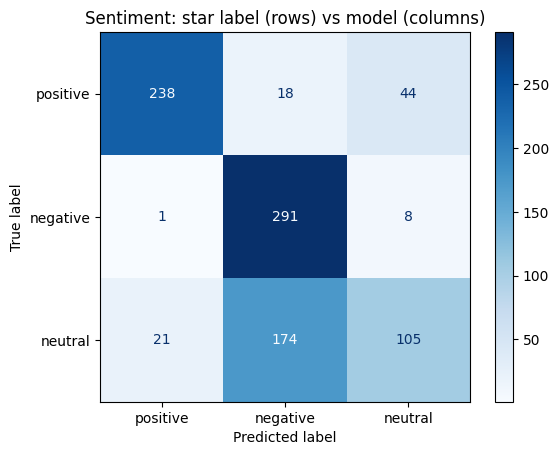

In [124]:
# Precision, recall, F1 and confusion matrix
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(classification_report(eval_results["star_label"], eval_results["predicted"],
                            labels=LABELS, digits=2, zero_division=0))
print("Unknown answers:", (eval_results["predicted"] == "unknown").sum())

matrix = confusion_matrix(eval_results["star_label"], eval_results["predicted"], labels=LABELS)
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(cmap="Blues", values_format="d")
plt.title("Sentiment: star label (rows) vs model (columns)")
plt.show()

#Difficult cases: 3-star reviews labelled negative
174 of 300 three-star reviews were labelled negative. A 3-star rating does not guarantee a neutral text, so we read 20 of these reviews and judge whether the text is really negative (model right) or neutral/mixed (model wrong).


In [125]:
#Read 20 three-star reviews the model called negative
neutral_as_negative = eval_results[(eval_results["star_label"] == "neutral") &
                                   (eval_results["predicted"] == "negative")]
check_reviews = neutral_as_negative.sample(20, random_state=SEED)

for i, (_, row) in enumerate(check_reviews.iterrows(), start=1):
    print(f"{i:2d}. {row['body'][:250]}\n")

 1. I went to my Note 5 up from a Note 4. I liked my Note 4 but it was getting a little slow. I was expecting a note 4 with a faster CPU. Boy was I disappointed. The first thing I noticed was this phone has no SD card slot like my Note 4 did. This limite

 2. I purchased this phone in 02/18, when purchased it said Duel sim phone. I tried to put a second sim in phone and didn’t work. Huawei customer service has informed me that you cant have a dual sim phone in the US and the second sim is disabled. Amazon

 3. Battery life is really bad and I have to shut it of once in a while because the typing screen doesn’t show..

 4. Please, don't waste your money on this phone. My screen went out after having it for only five months; and when I contacted Samsung's customer service they basically implied theft. The phones battery doesn't come out, it constantly over heats, and th

 5. I actually like the phone a lot, BUT, if you need an unlocked version, this isn't it. Mine came locked and I am ye

**Reading 20 of the 174 cases:** 7 were really negative (the stars were too kind). 13 were mixed, mostly "I like the phone, but..." with one complaint, often about the seller or delivery. The model gives complaints too much weight.

### Version 2: a rule for mixed reviews
If the customer likes the phone but has one complaint (including seller or delivery problems), the review is neutral. This rule came from reading the same sample, so it is tested on the same data.

Labelled 50 / 900 (17 s)
Labelled 100 / 900 (35 s)
Labelled 150 / 900 (52 s)
Labelled 200 / 900 (69 s)
Labelled 250 / 900 (86 s)
Labelled 300 / 900 (104 s)
Labelled 350 / 900 (122 s)
Labelled 400 / 900 (139 s)
Labelled 450 / 900 (157 s)
Labelled 500 / 900 (174 s)
Labelled 550 / 900 (191 s)
Labelled 600 / 900 (208 s)
Labelled 650 / 900 (226 s)
Labelled 700 / 900 (242 s)
Labelled 750 / 900 (259 s)
Labelled 800 / 900 (276 s)
Labelled 850 / 900 (293 s)
Labelled 900 / 900 (310 s)
              precision    recall  f1-score   support

    positive       0.97      0.61      0.75       300
    negative       0.78      0.66      0.71       300
     neutral       0.53      0.80      0.64       300

    accuracy                           0.69       900
   macro avg       0.76      0.69      0.70       900
weighted avg       0.76      0.69      0.70       900



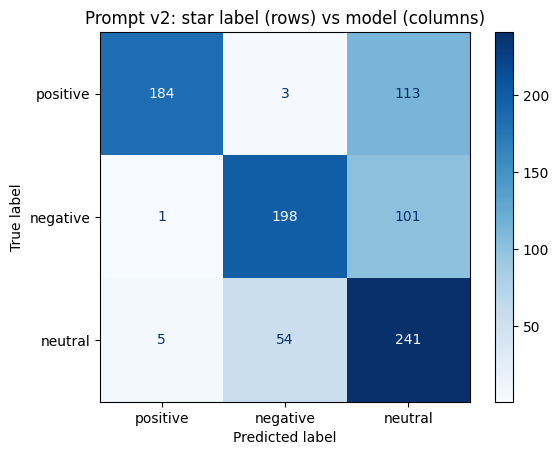

In [126]:
#Prompt version 2 (mixed reviews) and re-evaluate
SENTIMENT_PROMPT = """Classify the overall sentiment of this phone review.

Labels:
- positive: the customer is happy with the phone and has no real complaint.
- negative: the customer is mainly unhappy with the phone overall (it fails, breaks, or they regret buying it).
- neutral: mixed or average. The customer likes the phone but has a complaint (including problems with the seller, delivery, unlocking or accessories), or the review has clear good and bad points.

A complaint alone does not make a review negative if the customer also clearly likes the phone.

Review: "{review}"

Answer with one word only: positive, negative or neutral."""

eval_results_v2 = label_reviews(eval_sample, OUTPUT_DIR / "sentiment_eval_sample_v2.csv")

print(classification_report(eval_results_v2["star_label"], eval_results_v2["predicted"],
                            labels=LABELS, digits=2, zero_division=0))
matrix = confusion_matrix(eval_results_v2["star_label"], eval_results_v2["predicted"], labels=LABELS)
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(cmap="Blues", values_format="d")
plt.title("Prompt v2: star label (rows) vs model (columns)")
plt.show()

### Version 3: predict a 1–5 rating, then map to a label
v1 called mixed reviews negative. v2 called many clear reviews neutral. In v3 the model predicts the star rating (1–5) the customer would give, which we map to labels the same way as the reference (1–2 negative, 3 neutral, 4–5 positive). The model still reads only the text.

Labelled 50 / 900 (16 s)
Labelled 100 / 900 (32 s)
Labelled 150 / 900 (49 s)
Labelled 200 / 900 (65 s)
Labelled 250 / 900 (81 s)
Labelled 300 / 900 (97 s)
Labelled 350 / 900 (114 s)
Labelled 400 / 900 (131 s)
Labelled 450 / 900 (147 s)
Labelled 500 / 900 (163 s)
Labelled 550 / 900 (179 s)
Labelled 600 / 900 (195 s)
Labelled 650 / 900 (212 s)
Labelled 700 / 900 (227 s)
Labelled 750 / 900 (243 s)
Labelled 800 / 900 (259 s)
Labelled 850 / 900 (275 s)
Labelled 900 / 900 (291 s)
              precision    recall  f1-score   support

    positive       0.89      0.75      0.81       300
    negative       0.66      0.94      0.78       300
     neutral       0.66      0.48      0.55       300

    accuracy                           0.72       900
   macro avg       0.74      0.72      0.72       900
weighted avg       0.74      0.72      0.72       900

Unknown answers: 0


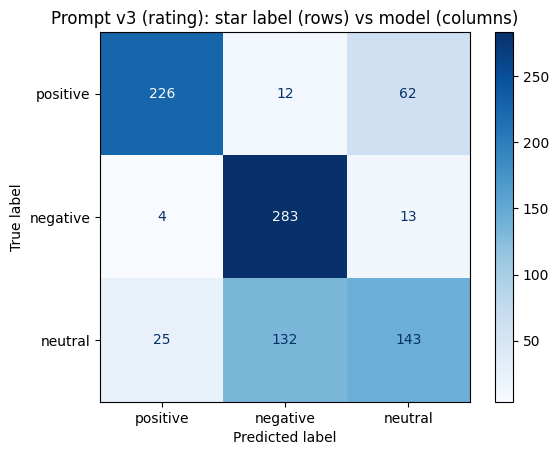

In [127]:
#Version 3 (predict a 1-5 rating) and re-evaluate
RATING_PROMPT = """Read this phone review and decide how many stars (1 to 5) the customer would give.
1 = very unhappy, 2 = unhappy, 3 = mixed or average, 4 = happy with small issues, 5 = very happy.

Review: "{review}"

Answer with one number only: 1, 2, 3, 4 or 5."""


def classify_sentiment(review):
    """v3: predict a 1-5 rating from the text, then map it to a sentiment label."""
    review = " ".join(str(review).split()[:MAX_REVIEW_WORDS])
    reply = ask_llm(RATING_PROMPT.format(review=review), max_new_tokens=5)
    match = re.search(r"[1-5]", reply)
    if not match:
        return "unknown"
    return star_label(int(match.group()))          # same mapping as the reference labels


eval_results_v3 = label_reviews(eval_sample, OUTPUT_DIR / "sentiment_eval_sample_v3.csv")

print(classification_report(eval_results_v3["star_label"], eval_results_v3["predicted"],
                            labels=LABELS, digits=2, zero_division=0))
print("Unknown answers:", (eval_results_v3["predicted"] == "unknown").sum())
matrix = confusion_matrix(eval_results_v3["star_label"], eval_results_v3["predicted"], labels=LABELS)
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(cmap="Blues", values_format="d")
plt.title("Prompt v3 (rating): star label (rows) vs model (columns)")
plt.show()

**Comparing the three versions (same 900 reviews)**

| | v1 (label) | v2 (mixed rule) | v3 (1–5 rating) |
|---|---|---|---|
| Positive F1 | 0.85 | 0.75 | 0.81 |
| Negative F1 | 0.74 | 0.71 | 0.78 |
| Neutral F1 | 0.46 | 0.64 | 0.55 |
| Macro F1 | 0.68 | 0.70 | **0.72** |
| Accuracy | 0.70 | 0.69 | **0.72** |
| Negative recall | 0.97 | 0.66 | 0.94 |

- v1 called most mixed 3-star reviews negative.
- v2 fixed that but pushed many clear 1–2 and 4–5 star reviews to neutral.
- **We keep v3:** best macro F1 and accuracy, and it still finds almost all negative reviews.

Neutral is still the hardest class, partly because many 3-star reviews mainly describe a problem.

In [128]:
# Keeping version 3 as the final sentiment labels
eval_results = eval_results_v3
eval_results.to_csv(OUTPUT_DIR / "sentiment_eval_results_final.csv", index=False)

print("Final sentiment labels (v3):")
print(eval_results["predicted"].value_counts())

# Examples for the report: one correct review per sentiment
for label in LABELS:
    example = eval_results[(eval_results["star_label"] == label) & (eval_results["predicted"] == label)].iloc[0]
    print(f"\n{label.upper()} ({example['rating']} stars): {example['body'][:200]}")

Final sentiment labels (v3):
predicted
negative    427
positive    255
neutral     218
Name: count, dtype: int64

POSITIVE (5 stars): Best phone I have ever had

NEGATIVE (1 stars): I loved this phone for the first month I had it. The camera was great! Around month two it started to glitz and flash green and yellow when I would push the home button, but all in all it still worked

NEUTRAL (3 stars): Not a bad product but I prefer my Unlocked Galaxy S5. The upgrades don't over shadow the S5 in anyway. Also its a Droids version of an I phone, no external memory (You can't add a chip IOT save songs 


## 3.2 Key feedback extraction
The LLM lists what each review praises and criticises, using a fixed list of 14 aspects so we can count them. We use 300 reviews from the evaluation sample (100 per star class).

First test: the model copied almost the whole aspect list for one review, and the answer was cut off (80 tokens), so it returned nothing. Fix: "only aspects the review mentions", one example, and 150 tokens.

In [129]:
#Extract pros and cons (fixed aspect list), tested on 3 reviews
import json
ASPECTS = ["battery", "camera", "screen", "performance", "price", "build quality",
           "signal and network", "software", "sound and calls", "storage", "charging",
           "unlocking and carrier", "condition on arrival", "seller and delivery"]

FEEDBACK_PROMPT = """Read this phone review and list what the customer praises and criticises.

Use only these aspects:
{aspects}

Meanings:
- performance: speed, lag, freezing, crashing, overheating
- build quality: durability, breaking, cracking, design
- condition on arrival: scratches, used or refurbished state, missing parts
- unlocking and carrier: locked phone, carrier problems, wrong version

Rules:
- Only include aspects the review actually talks about. Most reviews mention 0 to 3 aspects.
- Never include an aspect that the review does not mention.

Example:
Review: "Love the screen but it lags a lot and the seller sent the wrong colour."
{{"pros": ["screen"], "cons": ["performance", "seller and delivery"]}}

Review: "{review}"

Output only JSON in this format:
{{"pros": [...], "cons": [...]}}"""


def extract_feedback(review):
    """Return (pros, cons) as lists of aspects from the fixed list."""
    review = " ".join(str(review).split()[:MAX_REVIEW_WORDS])
    reply = ask_llm(FEEDBACK_PROMPT.format(aspects=", ".join(ASPECTS), review=review), max_new_tokens=150)
    found = re.search(r"\{.*\}", reply, flags=re.DOTALL)        # keep only the {...} part
    reply = found.group() if found else ""
    try:
        data = json.loads(reply)
    except json.JSONDecodeError:
        return [], []
    pros = [a for a in data.get("pros", []) if a in ASPECTS]     # keep only valid aspects
    cons = [a for a in data.get("cons", []) if a in ASPECTS]
    return pros, cons


for review in [
    "Great camera and screen, but the battery dies by lunchtime and it gets hot.",
    "Phone arrived with scratches on the back and was locked to Verizon, so I returned it.",
    eval_results.iloc[0]["body"],
]:
    print(extract_feedback(review), "|", review[:90])

(['camera', 'screen'], ['battery', 'performance']) | Great camera and screen, but the battery dies by lunchtime and it gets hot.
([], ['condition on arrival', 'unlocking and carrier']) | Phone arrived with scratches on the back and was locked to Verizon, so I returned it.
(['camera'], ['performance', 'screen']) | I loved this phone for the first month I had it. The camera was great! Around month two it


### Extract feedback from 300 reviews
Progress is saved every 25 reviews.

In [130]:
# Extract pros and cons for 300 reviews (with progress saving)
FEEDBACK_PER_CLASS = 100
feedback_sample = (eval_results.groupby("star_label")
                               .sample(n=FEEDBACK_PER_CLASS, random_state=SEED)
                               .reset_index(drop=True))

def extract_feedback_batch(reviews_to_check, save_path, save_every=25):
    """Extract pros and cons for every review. Saves progress and resumes from the saved file."""
    pros_list, cons_list = [], []
    if Path(save_path).exists():
        saved = pd.read_csv(save_path).fillna("")
        pros_list, cons_list = saved["pros"].tolist(), saved["cons"].tolist()
        print(f"Resuming: {len(pros_list)} already done.")

    start = time.time()
    for i in range(len(pros_list), len(reviews_to_check)):
        pros, cons = extract_feedback(reviews_to_check.loc[i, "body"])
        pros_list.append("|".join(pros))
        cons_list.append("|".join(cons))
        if (i + 1) % save_every == 0 or i + 1 == len(reviews_to_check):
            pd.DataFrame({"pros": pros_list, "cons": cons_list}).to_csv(save_path, index=False)
            print(f"Done {i + 1} / {len(reviews_to_check)} ({time.time() - start:.0f} s)")

    result = reviews_to_check.copy()
    result["pros"], result["cons"] = pros_list, cons_list
    return result


feedback_results = extract_feedback_batch(feedback_sample, OUTPUT_DIR / "feedback_300.csv")
display(feedback_results[["star_label", "predicted", "pros", "cons", "body"]].head(8))

Done 25 / 300 (81 s)
Done 50 / 300 (155 s)
Done 75 / 300 (241 s)
Done 100 / 300 (321 s)
Done 125 / 300 (406 s)
Done 150 / 300 (489 s)
Done 175 / 300 (583 s)
Done 200 / 300 (666 s)
Done 225 / 300 (771 s)
Done 250 / 300 (885 s)
Done 275 / 300 (978 s)
Done 300 / 300 (1080 s)


,star_label,predicted,pros,cons,body
0,negative,negative,,build quality|condition on arrival,The power button popped off and we had issues with it all around. Maybe a lemon.
1,negative,negative,,signal and network,Doesn't have good data reception with T-Mobile. Only 3G or H coverage where I get LTE with other phones.
2,negative,negative,,condition on arrival|software|seller and delivery,"As soon as the phone arrived it didn't work at all, I have returned the phone and I am still waiting for my refund"
3,negative,negative,,unlocking and carrier,Advertised as unlocked but when i tried to activate it i was unable to because the phone was not unlocked and still registered as an at&t phone
4,negative,negative,,build quality|performance|condition on arrival|seller and delivery,"sadly the phone did not live very long, like 4 and half months...not the sellers fault just a crappy phone. the chargers they came with the phone said they were the wrong chargers."
5,negative,negative,,condition on arrival,No recibí el celular por eso quiero cancelar la orden.
6,negative,negative,,unlocking and carrier|seller and delivery,"This was a Christmas present from my son. On the back of the box is stated, ""American SIM card only"". However, product was advertised as unlocked and international. We live in Singapore and just p..."
7,negative,negative,battery|screen|software|sound and calls|storage,seller and delivery|build quality|unlocking and carrier|condition on arrival|signal and network|camera|performance|price,"The touch screen failed after 64 days. Sony's service is clueless and keeps telling me it can be fixed via software, yet their software fix hasn't worked after 3 tries. The problem is, I can't get..."


### Count pros and cons by aspect
Some long reviews still got almost every aspect (one got 13), which would inflate the counts. Reviews with more than 5 aspects are left out, and we report how many.

In [131]:
# Remove list-copying results and count each aspect
def split_aspects(text):
    """'battery|camera' -> ['battery', 'camera']; empty text -> []."""
    return [a for a in str(text).split("|") if a]

feedback_results["pros_list"] = feedback_results["pros"].apply(split_aspects)
feedback_results["cons_list"] = feedback_results["cons"].apply(split_aspects)
feedback_results["n_aspects"] = feedback_results["pros_list"].str.len() + feedback_results["cons_list"].str.len()

print("Aspects per review:")
print(feedback_results["n_aspects"].value_counts().sort_index())

MAX_ASPECTS = 5
reliable = feedback_results[feedback_results["n_aspects"] <= MAX_ASPECTS]
print(f"\nUnreliable (more than {MAX_ASPECTS} aspects): {len(feedback_results) - len(reliable)} of {len(feedback_results)}")

aspect_counts = pd.DataFrame({
    "praised_by": [sum(a in pros for pros in reliable["pros_list"]) for a in ASPECTS],
    "criticised_by": [sum(a in cons for cons in reliable["cons_list"]) for a in ASPECTS],
}, index=ASPECTS)
aspect_counts["total"] = aspect_counts["praised_by"] + aspect_counts["criticised_by"]
aspect_counts = aspect_counts.sort_values("total", ascending=False)
aspect_counts.to_csv(OUTPUT_DIR / "aspect_counts.csv")
display(aspect_counts)

Aspects per review:
n_aspects
0      2
1     39
2     74
3     76
4     28
5     24
6     17
7     11
8      3
9      6
10     4
11     2
12     2
13     2
14    10
Name: count, dtype: int64

Unreliable (more than 5 aspects): 57 of 300


,praised_by,criticised_by,total
unlocking and carrier,9,80,89
condition on arrival,15,67,82
seller and delivery,3,69,72
build quality,27,41,68
performance,26,39,65
software,14,43,57
signal and network,6,30,36
battery,15,20,35
price,25,8,33
camera,23,5,28


### Check 15 reviews by hand
We read each review and mark the extracted aspects as correct, partly correct or wrong.

In [132]:
#Check 15 reliable reviews by hand
check_feedback = reliable.sample(15, random_state=SEED)

for i, (_, row) in enumerate(check_feedback.iterrows(), start=1):
    print(f"{i:2d}. PROS: {row['pros_list']}  CONS: {row['cons_list']}")
    print(f"    {row['body'][:300]}\n")

 1. PROS: []  CONS: ['battery', 'seller and delivery']
    Good day. The equipment does not work. The battery does not charge and the phone does not turn on. This phone is a Christmas gift for my mom. Replacement I need is sent before November 25 to the following address TIME SHIPPING / Andres Lorenzo 11601 NW 107TH ST MIAMI, FL 33178-3385 United States. Or

 2. PROS: []  CONS: ['unlocking and carrier', 'seller and delivery']
    This was a Christmas present from my son. On the back of the box is stated, "American SIM card only". However, product was advertised as unlocked and international. We live in Singapore and just put in a new SIM card and it was asking for the unlock code. The Singapore unlock code would not work. Ve

 3. PROS: ['price']  CONS: ['condition on arrival', 'seller and delivery']
    Phone came in on time but phone deffintly shows some wear on the screen with a large deep scratch on the front and the audio ports beening dirty. Not the most impressive for a referbish

### Version 2: every aspect needs a quote
The hand check found only 6 of 15 fully correct, mostly because of made-up aspects (especially "seller and delivery" and "software"). Now the model must copy the words from the review for each aspect, and we drop any aspect whose quote isn't in the review. The quotes also show the evidence.

First test: fewer made-up aspects (WiFi problems now go to "signal and network"), but three reviews lost all aspects because the quote was slightly different from the review. The check now accepts a quote if at least 80% of its words are in the review.

A quote proves the words exist, not that they were filed under the right aspect (e.g. "came on time" listed as a complaint).

In [134]:
# Version 2 extraction with supporting quotes, tested on the 15 checked reviews
FEEDBACK_PROMPT_V2 = """Read this phone review and list what the customer praises and criticises.

Use only these aspects:
{aspects}

Meanings:
- performance: speed, lag, freezing, crashing, overheating
- build quality: durability, breaking, cracking, design
- condition on arrival: scratches, used or refurbished state, missing parts
- unlocking and carrier: locked phone, carrier problems, wrong version
- signal and network: mobile data, reception, WiFi, Bluetooth

Rules:
- For every aspect, copy the exact words from the review (a few words) that talk about it.
- Only include an aspect if you can copy words from the review that mention it.

Example:
Review: "Love the screen but it lags a lot and the seller sent the wrong colour."
{{"pros": [{{"aspect": "screen", "quote": "Love the screen"}}], "cons": [{{"aspect": "performance", "quote": "it lags a lot"}}, {{"aspect": "seller and delivery", "quote": "the seller sent the wrong colour"}}]}}

Review: "{review}"

Output only JSON in this format."""


def simplify(text):
    """Lowercase, keep letters and numbers, single spaces (for checking quotes)."""
    return " ".join(re.sub(r"[^a-z0-9]+", " ", str(text).lower()).split())

def quote_in_review(quote, review, min_share=0.8):
    """True if at least 80% of the quote's words appear in the review."""
    quote_words = simplify(quote).split()
    review_words = set(simplify(review).split())
    if not quote_words:
        return False
    return sum(w in review_words for w in quote_words) / len(quote_words) >= min_share

def extract_feedback_v2(review):
    """Return (pros, cons, evidence). Aspects are kept only if their quote is found in the review."""
    review = " ".join(str(review).split()[:MAX_REVIEW_WORDS])
    reply = ask_llm(FEEDBACK_PROMPT_V2.format(aspects=", ".join(ASPECTS), review=review), max_new_tokens=300)
    found = re.search(r"\{.*\}", reply, flags=re.DOTALL)
    try:
        data = json.loads(found.group()) if found else {}
    except json.JSONDecodeError:
        data = {}

    pros, cons, evidence = [], [], []
    for side, kept in [("pros", pros), ("cons", cons)]:
        for item in data.get(side, []):
            aspect, quote = item.get("aspect"), item.get("quote", "")
            if aspect in ASPECTS and quote_in_review(quote, review) and aspect not in kept:
                kept.append(aspect)
                evidence.append(f"{side[:-1]}: {aspect} = \"{quote}\"")
    return pros, cons, evidence


# Compare old vs new on the 15 reviews checked by hand
for i, (_, row) in enumerate(check_feedback.iterrows(), start=1):
    pros, cons, evidence = extract_feedback_v2(row["body"])
    print(f"{i:2d}. OLD pros {row['pros_list']} cons {row['cons_list']}")
    print(f"    NEW pros {pros} cons {cons}")
    for e in evidence:
        print(f"      {e}")
    print()

 1. OLD pros [] cons ['battery', 'seller and delivery']
    NEW pros [] cons ['battery', 'performance']
      con: battery = "battery does not charge"
      con: performance = "equipment does not work"

 2. OLD pros [] cons ['unlocking and carrier', 'seller and delivery']
    NEW pros [] cons ['unlocking and carrier']
      con: unlocking and carrier = "unlocked and international"

 3. OLD pros ['price'] cons ['condition on arrival', 'seller and delivery']
    NEW pros ['price'] cons ['condition on arrival', 'build quality', 'seller and delivery']
      pro: price = "for a good price"
      con: condition on arrival = "shows some wear on the screen with a large deep scratch on the front and the audio ports being dirty"
      con: build quality = "Not the most impressive for a refurbished phone"
      con: seller and delivery = "Phone came in on time"

 4. OLD pros ['performance'] cons ['charging', 'unlocking and carrier']
    NEW pros [] cons []

 5. OLD pros ['screen', 'camera', 'soft

**Hand check, v1 vs v2 (same 15 reviews):** fully correct 6 -> 8, partly correct 8 -> 5, wrong 1 -> 0. Two reviews got no aspects in v2. We use v2, because every aspect is backed by words from the review.

### Run version 2 on 300 reviews
v2 took about 87 minutes (5 times slower, because it writes a quote for each aspect). 45 reviews still got more than 5 aspects, because general quotes like "This phone looks great" passed the check for several aspects, so we leave them out as in v1. 44 reviews got no aspects, mostly short reviews or quotes that failed the check.

In [135]:
# Version 2 on 300 reviews and count each aspect
def extract_feedback_v2_batch(reviews_to_check, save_path, save_every=25):
    """Version 2 extraction for every review, with progress saving and resume."""
    rows = []
    if Path(save_path).exists():
        rows = pd.read_csv(save_path).fillna("").to_dict("records")
        print(f"Resuming: {len(rows)} already done.")

    start = time.time()
    for i in range(len(rows), len(reviews_to_check)):
        pros, cons, evidence = extract_feedback_v2(reviews_to_check.loc[i, "body"])
        rows.append({"pros": "|".join(pros), "cons": "|".join(cons), "evidence": " ; ".join(evidence)})
        if (i + 1) % save_every == 0 or i + 1 == len(reviews_to_check):
            pd.DataFrame(rows).to_csv(save_path, index=False)
            print(f"Done {i + 1} / {len(reviews_to_check)} ({time.time() - start:.0f} s)")

    result = reviews_to_check.copy()
    saved = pd.DataFrame(rows)
    result["pros"], result["cons"], result["evidence"] = saved["pros"], saved["cons"], saved["evidence"]
    return result


feedback_v2 = extract_feedback_v2_batch(feedback_sample, OUTPUT_DIR / "feedback_300_v2.csv")
feedback_v2["pros_list"] = feedback_v2["pros"].apply(split_aspects)
feedback_v2["cons_list"] = feedback_v2["cons"].apply(split_aspects)
feedback_v2["n_aspects"] = feedback_v2["pros_list"].str.len() + feedback_v2["cons_list"].str.len()

print("\nReviews with more than 5 aspects:", (feedback_v2["n_aspects"] > 5).sum(), "(version 1: 57)")
print("Reviews with no aspects:", (feedback_v2["n_aspects"] == 0).sum())

aspect_counts_v2 = pd.DataFrame({
    "praised_by": [sum(a in p for p in feedback_v2["pros_list"]) for a in ASPECTS],
    "criticised_by": [sum(a in c for c in feedback_v2["cons_list"]) for a in ASPECTS],
}, index=ASPECTS)
aspect_counts_v2["total"] = aspect_counts_v2["praised_by"] + aspect_counts_v2["criticised_by"]
aspect_counts_v2 = aspect_counts_v2.sort_values("total", ascending=False)
aspect_counts_v2.to_csv(OUTPUT_DIR / "aspect_counts_v2.csv")
display(aspect_counts_v2)

Done 25 / 300 (409 s)
Done 50 / 300 (785 s)
Done 75 / 300 (1272 s)
Done 100 / 300 (1730 s)
Done 125 / 300 (2177 s)
Done 150 / 300 (2555 s)
Done 175 / 300 (3012 s)
Done 200 / 300 (3490 s)
Done 225 / 300 (3937 s)
Done 250 / 300 (4345 s)
Done 275 / 300 (4650 s)
Done 300 / 300 (5086 s)

Reviews with more than 5 aspects: 45 (version 1: 57)
Reviews with no aspects: 44


,praised_by,criticised_by,total
software,60,64,124
performance,56,63,119
build quality,54,38,92
unlocking and carrier,18,72,90
condition on arrival,34,56,90
seller and delivery,22,48,70
signal and network,27,38,65
price,31,18,49
storage,27,17,44
sound and calls,24,20,44


In [136]:
# Leave out reviews with more than 5 aspects (same rule as version 1)
reliable_v2 = feedback_v2[feedback_v2["n_aspects"] <= MAX_ASPECTS]
print(f"Reliable reviews: {len(reliable_v2)} of {len(feedback_v2)}")

aspect_counts_v2 = pd.DataFrame({
    "praised_by": [sum(a in p for p in reliable_v2["pros_list"]) for a in ASPECTS],
    "criticised_by": [sum(a in c for c in reliable_v2["cons_list"]) for a in ASPECTS],
}, index=ASPECTS)
aspect_counts_v2["total"] = aspect_counts_v2["praised_by"] + aspect_counts_v2["criticised_by"]
aspect_counts_v2 = aspect_counts_v2.sort_values("total", ascending=False)
aspect_counts_v2.to_csv(OUTPUT_DIR / "aspect_counts_v2.csv")

comparison = aspect_counts[["praised_by", "criticised_by"]].join(
    aspect_counts_v2[["praised_by", "criticised_by"]], lsuffix="_v1", rsuffix="_v2")
display(comparison)

Reliable reviews: 255 of 300


,praised_by_v1,criticised_by_v1,praised_by_v2,criticised_by_v2
unlocking and carrier,9,80,5,53
condition on arrival,15,67,16,42
seller and delivery,3,69,10,37
build quality,27,41,28,28
performance,26,39,32,44
software,14,43,26,49
signal and network,6,30,6,31
battery,15,20,9,14
price,25,8,16,13
camera,23,5,11,4


**v1 vs v2 counts:** both show the same main complaints (unlocking and carrier, software, performance, condition on arrival), while camera, screen and price are mostly praised. v2 counts are lower, because each aspect needs a quote. The biggest change is seller and delivery (69 → 37 complaints), which matches the hand check, where v1 often added it wrongly. We use v2 (255 reviews). The sample is balanced, so complaints are more common here than in all reviews.

### Most common feedback, with quotes
The chart shows how many reviews praise or criticise each aspect. For the top 6 aspects, we show quotes from different reviews, including mixed views.

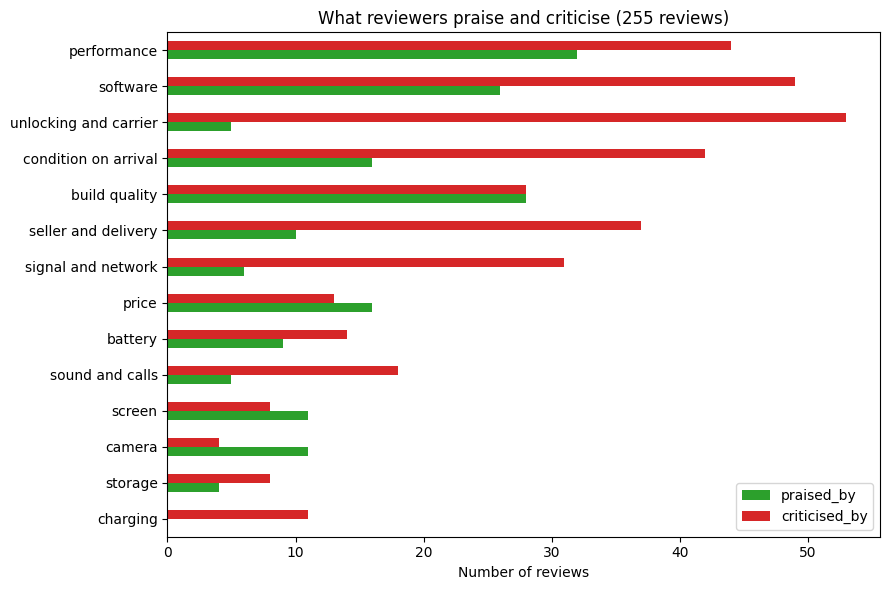


PERFORMANCE: praised by 32, criticised by 44
   - "it didn't work at all"
   - "did not live very long"
   - "audio jack (for earphones) don't work anymore"
   + "handled it carefully, and respectfully"
   + "good phone"

SOFTWARE: praised by 26, criticised by 49
   - "i have to be able to actually HEAR people with it in other words the auricular is messed up"
   - "Samsung they deny it and are zero help in resolving it"
   - "It will not connect to my Bluetooth devices"
   + "I always handled it carefully, and respectfully"
   + "Basic setup was easy"

UNLOCKING AND CARRIER: praised by 5, criticised by 53
   - "Maybe a lemon"
   - "Advertised as unlocked but when i tried to activate it i was unable to because the phone was not unlocked and still registered as an at&t phone"
   - "wrong chargers"
   + "unlocked from at&t"
   + "worked with sprint"

CONDITION ON ARRIVAL: praised by 16, criticised by 42
   - "we had issues with it all around"
   - "it didn't work at all"
   - "No recibí

In [137]:
#Chart of pros and cons, with supporting quotes
import matplotlib.pyplot as plt

chart_data = aspect_counts_v2[["praised_by", "criticised_by"]].iloc[::-1]
chart_data.plot(kind="barh", figsize=(9, 6), color=["tab:green", "tab:red"])
plt.title("What reviewers praise and criticise (255 reviews)")
plt.xlabel("Number of reviews")
plt.tight_layout()
plt.show()


def quotes_for(aspect, side, n=3):
    """Up to n quotes about an aspect ('pro' or 'con') from different reviews."""
    found = []
    for evidence in reliable_v2["evidence"]:
        for item in str(evidence).split(" ; "):
            if item.startswith(f"{side}: {aspect} ="):
                found.append(item.split("=", 1)[1].strip())
                break
        if len(found) == n:
            break
    return found


for aspect in aspect_counts_v2.index[:6]:
    row = aspect_counts_v2.loc[aspect]
    print(f"\n{aspect.upper()}: praised by {row['praised_by']}, criticised by {row['criticised_by']}")
    for q in quotes_for(aspect, "con"):
        print("   -", q)
    if row["praised_by"] > 0:
        for q in quotes_for(aspect, "pro", n=2):
            print("   +", q)

**Findings:** the main complaints are unlocking and carrier (53 reviews), software (49), performance (44) and condition on arrival (42), so it is more about reliability and how phones are sold than their features. Camera, screen and price are criticised least (4, 8 and 13 reviews). Build quality is split (28 praise, 28 complaints). Some quotes are filed under the wrong aspect (e.g. "Maybe a lemon" under unlocking and carrier, an earpiece problem under software), so the counts are approximate.

## 3.3 Product improvement suggestions
The LLM gets every complaint mentioned in at least 15 of the 255 reviews, with its count and up to 3 quotes from different reviews (printed below, so it can be seen exactly what it receives). It writes one suggestion per complaint, using only this evidence.

In [138]:
#LLM improvement suggestions from repeated complaints
MIN_COMPLAINTS = 15
top_complaints = aspect_counts_v2[aspect_counts_v2["criticised_by"] >= MIN_COMPLAINTS]

evidence_lines = []
for aspect, row in top_complaints.iterrows():
    quotes = quotes_for(aspect, "con", n=3)
    evidence_lines.append(f"- {aspect}: criticised in {row['criticised_by']} reviews. Examples: "
                          + " | ".join(quotes))
evidence_text = "\n".join(evidence_lines)
print("EVIDENCE GIVEN TO THE LLM:\n" + evidence_text)

SUGGESTION_PROMPT = """You advise an online shop that sells new and renewed phones, and the phone makers it works with.
Below are the most common complaints from {n_reviews} customer reviews, with how many reviews mention each one and example quotes.

{evidence}

For each complaint, write one specific improvement suggestion in this format:
Complaint: <aspect> ({{count}} reviews)
Suggestion: <a specific change the shop or the phone maker could make>
Why it helps: <how this change addresses what the customers described>

Rules:
- Use only the complaints and quotes above. Do not invent new problems or numbers.
- Keep the counts exactly as given.
- Make each suggestion specific to what customers described, not general advice."""

suggestions = ask_llm(SUGGESTION_PROMPT.format(n_reviews=len(reliable_v2), evidence=evidence_text),
                      max_new_tokens=700)
print("\nLLM SUGGESTIONS:\n" + suggestions)

EVIDENCE GIVEN TO THE LLM:
- performance: criticised in 44 reviews. Examples: "it didn't work at all" | "did not live very long" | "audio jack (for earphones) don't work anymore"
- software: criticised in 49 reviews. Examples: "i have to be able to actually HEAR people with it in other words the auricular is messed up" | "Samsung they deny it and are zero help in resolving it" | "It will not connect to my Bluetooth devices"
- unlocking and carrier: criticised in 53 reviews. Examples: "Maybe a lemon" | "Advertised as unlocked but when i tried to activate it i was unable to because the phone was not unlocked and still registered as an at&t phone" | "wrong chargers"
- condition on arrival: criticised in 42 reviews. Examples: "we had issues with it all around" | "it didn't work at all" | "No recibí el celular por eso quiero cancelar la orden."
- build quality: criticised in 28 reviews. Examples: "power button popped off" | "crappy phone" | "I haven't dropped it and it's protected by a cove

### Version 2: more specific, with priorities
Version 1 gave a correct suggestion for every complaint, but some were general ("provide better support"), counts appeared in braces, and there were no priorities. Version 2 asks who should act (shop or phone maker), one concrete step, and a top 3. Then we check every complaint and its count appear in the answer.

In [139]:
#Version 2 suggestions and an automatic check
SUGGESTION_PROMPT_V2 = """You advise an online shop that sells new and renewed phones, and the phone makers it works with.
Below are the most common complaints from {n_reviews} customer reviews, with how many reviews mention each one and example quotes.

{evidence}

For each complaint, write:
Complaint: <aspect> (<number> reviews)
Who should act: shop or phone maker
Action: one concrete, practical step (for example, a specific check, test or listing change), based on what the quotes describe
Why it helps: how this step prevents the problem the customers described

Then write "Top 3 priorities:" and list the three most important actions, explaining each choice using the number of reviews and how serious the problem is.

Rules:
- Use only the complaints and quotes above. Do not invent new problems or numbers.
- Write each count exactly as given, as a plain number."""

suggestions_v2 = ask_llm(SUGGESTION_PROMPT_V2.format(n_reviews=len(reliable_v2), evidence=evidence_text),
                         max_new_tokens=1000)
print(suggestions_v2)

# Automatic check: every complaint and its correct count appear in the answer
check = pd.DataFrame([{
    "complaint": aspect,
    "count": row["criticised_by"],
    "named": aspect in suggestions_v2.lower(),
    "count_correct": f"{aspect} ({row['criticised_by']} reviews)" in suggestions_v2.lower(),
} for aspect, row in top_complaints.iterrows()])
display(check)

with open(OUTPUT_DIR / "improvement_suggestions.txt", "w") as f:
    f.write("EVIDENCE\n" + evidence_text + "\n\nSUGGESTIONS\n" + suggestions_v2)

**Complaint: performance (44 reviews)**  
Who should act: shop  
Action: Implement a pre-order test where customers can verify the phone's functionality before purchase, including testing the audio jack and battery life.  
Why it helps: This step ensures that phones with performance issues are identified and addressed before they are sold, reducing the number of returns and customer dissatisfaction.

**Complaint: software (49 reviews)**  
Who should act: phone maker  
Action: Provide detailed technical support documentation and ensure that all software updates are thoroughly tested before release.  
Why it helps: This step helps phone makers address software-related issues before they become a problem for customers, reducing the need for customer support and returns.

**Complaint: unlocking and carrier (53 reviews)**  
Who should act: shop  
Action: Verify the unlock status of the phones before shipping and ensure that all devices are properly unlocked and registered for any carrier.  

,complaint,count,named,count_correct
0,performance,44,True,True
1,software,49,True,True
2,unlocking and carrier,53,True,True
3,condition on arrival,42,True,True
4,build quality,28,True,True
5,seller and delivery,37,True,True
6,signal and network,31,True,True
7,sound and calls,18,True,True


**Result:** all 8 complaints got a suggestion with the right count (8/8), saying who should act, one step and why it helps, followed by a top 3 (unlocking and carrier, software, performance). Limitations: some steps are still general (e.g. "optimise signal strength"), the seller suggestion is about tracking while the quotes are about refunds, and a few quotes came from the wrong aspect in 3.2.

# Summary of results

| Task | Result |
|---|---|
| 1.1 Image selection | Category queries: precision 0.98, recall 0.96. Colour/hand queries: precision 0.13 (group labels only) → 0.68 (our method) |
| 1.2 Slogans | Different for each audience, no made-up specs, tested on 3 images × 3 audiences + a new audience |
| 1.3 Auto-layout | Phone photos: product covered 19% → 9%, fully visible adverts 7 → 15 |
| 2 Specs CSV | All 720 products have a status; 27/30 matches exact, 1 wrong; 5/5 spot checks match gsmarena.com |
| 2.1 List all matches | 12/12 test requests correct, unsupported requests refused |
| 2.2 Recommendations | Use-aware, pandas-ranked, fact-checked explanations |
| 2.3 What reviewers say | 92% relevant reviews vs 15% random, quotes checked |
| 3.1 Sentiment | Macro F1 0.72, accuracy 0.72 (v3) |
| 3.2 Feedback | Main complaints: unlocking/carrier, software, performance, condition on arrival |
| 3.3 Suggestions | 8/8 complaints covered with correct counts, top 3 priorities |
